# 09 — The portfolio: scorecards, books, stage gates, levers, and the milestone-managed book

Scorecards and what-ifs, the simulated book with shared risk, the budget-constrained choice and its backtest (C9–C11), the stage gates and the four policies (F23), the decision pack; the constraint map, scenarios, levers and region playbooks; and the registered milestone-managed book (C15–C17, F18, F24).

**Inputs → Outputs**

| Part | Was | What it does |
|---|---|---|
| A | notebook 16 | The portfolio: scorecards, what-ifs, a simulated book, a budget-constrained choice, and a backtest |
| B | notebook 17 | Constraints, levers and region playbooks |
| C | notebook 20 | The milestone-managed book: does a model beat a careful analyst's lookup two years in? |

*Execution order:* Runs after notebook 07. Paths are relative to the repository root.

*Part A*

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet`, `results/dt_tuning.json`, `results/variant_chosen.json` | notebooks 04/06/11 |
| in | `data/processed/predictions_v2_recalibrated.parquet`, `results/recalibration.csv` | notebook 12 — P at 3/5/7 for the model and both baselines; the level repair |
| in | `results/value_table.csv`, `results/cost_table.csv`, `results/value_assumptions.csv` | notebook 15 |
| in | `results/success_criteria_v2_registered.json` | notebook 11 — bootstrap settings |
| out | `results/scorecards.csv`, `results/whatifs.csv` | the sample book, request by request |
| out | `results/book_rho.csv`, `results/book_simulation.csv` | the shared-risk estimate and the simulated book |
| out | `results/book_choice.csv`, `results/book_choice_by_region.csv` | the chosen book under the budget and caps |
| out | `results/backtest_books.csv`, `results/backtest_bootstrap.csv` | realised MW and value by chooser, with paired intervals |
| out | `figures/F14_simulated_book.*`, `figures/F15_backtest.*`, `figures/09_portfolio/*` | F14, F15 and the notebook's figures |
| out | `results/portfolio_checks.csv` | this notebook's checks |
| in | `results/npv_by_request.csv`, `results/npv_table.csv`, `results/segments_by_request.csv`, `data/processed/predictions_landmark.parquet`, `results/drift_by_cohort.csv` | notebooks 15, 09, 14, 12 — the portfolio review (section 9) |
| out | `results/portfolio_review_summary.csv`, `results/policy_comparison.csv`, `results/decision_pack.csv`, `figures/F23_portfolio_review.*` | gates at entry and two years in, four policies under one budget, one row per request (section 9) |

*Part B*

| | Path | Notes |
|---|---|---|
| in | `data/interim/queue_clean.parquet`, `data/interim/trackA.parquet`, `data/interim/milestones.parquet` | notebooks 02/04/13 |
| in | `results/cif_horizons.csv`, `results/five_year_by_congestion.csv`, `results/partial_dependence.csv`, `results/sanity_checks.csv` | notebooks 03/09 |
| in | `results/metrics_v2_by_size.csv`, `results/drift_by_cohort_region.csv`, `results/landmark_agreement_signal.csv`, `results/value_table.csv`, `results/book_choice.csv`, `results/book_simulation.csv`, `results/whatifs.csv` | notebooks 11/12/14/15/16 |
| out | `results/constraint_map.csv` | congestion at entry and early exits by region × entry year |
| out | `results/scenarios.csv` | the sample book's expected MW online under the named scenarios |
| out | `results/levers.csv` | levers by actor with their evidence |
| out | `results/playbooks.csv`, `report/playbooks.md` | one row / one page per region |
| out | `figures/F16_constraint_map.*`, `figures/09_portfolio/*` | F16 and the notebook's figures |
| out | `results/levers_checks.csv` | this notebook's checks |

*Part C*

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet`, `results/dt_tuning.json` | notebooks 02/04/06 |
| in | `data/interim/milestones.parquet` | notebook 13 — dated agreements |
| in | `data/processed/predictions_v2.parquet` | notebook 11 — the fair baseline's entry P(operation by 5 years) |
| in | `data/processed/predictions_landmark.parquet` | notebook 14 — to check the refit reproduces the landmark model |
| out | `results/success_criteria_v4.csv`, `results/success_criteria_v4_registered.json` | criteria C15–C17, written before any test number (decision #58) |
| out | `results/managed_book_pool.csv` | the pool at the +2 landmark |
| out | `results/managed_books.csv`, `results/managed_book_bootstrap.csv` | each chooser's books, point and resampled |
| out | `results/managed_book_composition.csv` | what each book holds (agreement known, region) |
| out | `results/landmark_level_repair.csv`, `results/landmark_level_calibration.csv` | the level repair at the landmark (C17) |
| out | `results/success_criteria_v4_scored.csv` | the ten registered lines, scored |
| out | `figures/F18_managed_book.*`, `figures/09_portfolio/*` | F18 and the notebook's figures |
| out | `results/managed_book_checks.csv` | this notebook's checks |
| out | `results/recommended_books.csv`, `results/recommended_books_curve.csv`, `figures/F24_book_per_region.*` | how many to add per region at the two-year milestone (section 10; an extension of C15, not registered) |

# Part A — The portfolio: scorecards, what-ifs, a simulated book, a budget-constrained choice, and a backtest (was notebook 16)

This is the notebook the report is for. The unit of analysis moves from a request to a *book* of requests. For each request in a book: its probabilities at each horizon, the reasons behind them in words, what would change them (counterfactuals a developer can act on), and its expected value. For the book: a Monte Carlo of MW online by year with the shared risk of a cohort slowing down together, a budget-constrained choice of requests per region and technology, and — the test that matters — a backtest on the 2017–2019 cohort: did the books the model would have chosen deliver more MW and value than books chosen by the fair baseline or at random? Criteria C9, C10 and C11 are read from here in notebook 18.

## Setup

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, drift, explain, paths, plots, portfolio, variants

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "09_portfolio"
TRACK_A = config.TRACK_A_REGIONS
START = time.time()
REGISTERED = json.loads((paths.RESULTS / "success_criteria_v2_registered.json").read_text(encoding="utf-8"))
N_BOOT, LEVEL, SEED = REGISTERED["n_boot"], REGISTERED["level"], REGISTERED["seed_v2"] + 400
WINDOW = 10  # years after entry over which a request is valued (notebook 15)
BACKTEST_HORIZON = 5  # years after entry at which the backtest reads the realised MW
REGION_CAP, TECH_CAP = 0.5, 0.6  # share of the budget in any one region / technology (decision #46)
N_DRAWS = 5000  # Monte Carlo draws of a book


def save(fig, name, caption):
    """Save a figure of this notebook under figures/09_portfolio/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

## 1. Data, the model, and one value rule for every chooser

The v2 model (notebook 11) is refitted on entrants to 2016; its yearly P(operation by year 1 … 10) is read for every test request and repaired with notebook 12's rolling intercepts (the 5-year intercept of the request's region and entry year applied to the whole curve). The baselines give P only at 3, 5 and 7 years, so for the choosers' comparison every curve — model and baselines alike — is valued the same simple way: the value table of notebook 15 by region, technology and year (base case), the cost table's sunk cost, and `src/value.expected_value`. The baselines' curves are interpolated between 0, 3, 5 and 7 years and held flat after.

In [2]:
from src import value as value_mod

clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
chosen_name = json.loads((paths.RESULTS / "variant_chosen.json").read_text(encoding="utf-8"))["chosen"]
SPEC = variants.CANDIDATES[chosen_name]
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy().reset_index()
test["region"], test["tech"], test["size_regime"] = test["region"].astype(str), test["tech"].astype(str), test["size_regime"].astype(str)
fit = variants.fit_candidate(SPEC, final, clean, tuning)
years_ahead = list(range(1, WINDOW + 1))
P_raw = discrete_time.predict_both(fit, test.set_index("index"), horizons=years_ahead)[SPEC["model"]][years_ahead].to_numpy()
recal = pd.read_csv(paths.RESULTS / "recalibration.csv")
shift = recal[recal["horizon"] == 5].set_index(["scored_year", "region"])["intercept"]
a = np.array([shift.get((int(y), r), 0.0) for y, r in zip(test["q_year"], test["region"])])
P_model = drift.apply_intercept(P_raw, a[:, None])

pred = pd.read_parquet(paths.DATA_PROCESSED / "predictions_v2_recalibrated.parquet")
keys = test["project_key"].astype(str)


def interpolated_curve(column):
    """A baseline's P at 3, 5, 7 years as a yearly curve 1 … 10 (linear from 0, flat after 7)."""
    at = {h: pred[pred["horizon"] == h].set_index("project_key").loc[keys, column].to_numpy() for h in config.HORIZONS}
    knots_x, knots_y = [0, 3, 5, 7], np.column_stack([np.zeros(len(test)), at[3], at[5], at[7]])
    return np.column_stack([np.array([np.interp(min(j, 7), knots_x, row) for row in knots_y]) for j in years_ahead])


P_fair, P_v1 = interpolated_curve("fair_baseline"), interpolated_curve("baseline")
vt = pd.read_csv(paths.RESULTS / "value_table.csv").set_index(["region", "tech", "year"])["base"]
cost_table = pd.read_csv(paths.RESULTS / "cost_table.csv", index_col=0)
STUDY_COST = 150_000  # base case of notebook 15
sunk = (cost_table.loc[test["size_regime"], "sunk_per_mw_base"].to_numpy() * test["mw"].to_numpy() + STUDY_COST)


def expected_values(P):
    """Expected value of every test request from a (requests × years) incidence matrix, base case."""
    out = np.empty(len(test))
    for i, r in test.iterrows():
        vals = [vt.get((r["region"], r["tech"], int(r["q_year"]) + j), 0.0) for j in years_ahead]
        out[i] = value_mod.expected_value(P[i], r["mw"], vals, sunk[i])
    return out


EV = {"v2 model, level repaired": expected_values(P_model), "v2 model, raw": expected_values(P_raw),
      "fair baseline": expected_values(P_fair), "v1 baseline": expected_values(P_v1)}
CURVES = {"v2 model, level repaired": P_model, "v2 model, raw": P_raw, "fair baseline": P_fair, "v1 baseline": P_v1}
print(f"{len(test):,} test requests; mean P(operation by 5): model raw {P_raw[:, 4].mean():.3f}, repaired {P_model[:, 4].mean():.3f}, "
      f"fair baseline {P_fair[:, 4].mean():.3f}; mean expected value (repaired) ${EV['v2 model, level repaired'].mean() / 1e6:.1f}M "
      f"({(time.time() - START) / 60:.1f} min)")

2,268 test requests; mean P(operation by 5): model raw 0.136, repaired 0.112, fair baseline 0.143; mean expected value (repaired) $16.4M (0.0 min)


## 2. Scorecards for a book of 25 requests

The same book as notebook 09: 25 requests that entered in 2019 (9 PJM, 8 ERCOT, 8 CAISO, drawn with seed 2019), so the two notebooks can be read side by side. For each request: P(operation by 3, 5 and 7 years) raw and level-repaired, the fair baseline's figure, the top three reasons from SHAP (notebook 09's explanation function), the expected value, and what happened by end-2024.

In [3]:
pool = test[test["q_year"] == 2019]
book_rng = np.random.default_rng(2019)
book_idx = np.concatenate([pool.index[pool["region"] == r][book_rng.choice((pool["region"] == r).sum(), n, replace=False)]
                           for r, n in [("PJM", 9), ("ERCOT", 8), ("CAISO", 8)]])
book = test.loc[book_idx]
STATES = sorted(track_a["state"].astype(str).unique())
f5 = explain.incidence_function(fit, STATES, 5)
X_test = explain.encode(test.set_index("index"), STATES)
X_book = explain.encode(book.set_index("index"), STATES)
rng = np.random.default_rng(9)
background = X_test.iloc[rng.choice(len(X_test), 100, replace=False)].to_numpy()
explainer = shap.PermutationExplainer(f5, shap.maskers.Independent(background, max_samples=100), seed=9)
sv = explainer(X_book.to_numpy(), max_evals=2 * (2 * len(explain.FEATURES) + 1), silent=True)
shap_book = pd.DataFrame(sv.values, columns=explain.FEATURES, index=book.index)
LABELS = {"region": "region", "state": "state", "tech": "technology", "hybrid": "hybrid", "size_mw": "size", "service": "service",
          "q_year": "request year", "congestion_gw": "GW waiting", "congestion_rank": "congestion rank"}


def reason(row, feature):
    """One reason in words: the feature's value and its contribution in points."""
    pts = shap_book.loc[row.name, feature] * 100
    if feature == "size_mw":
        text = f"{row['mw']:.0f} MW"
    elif feature == "congestion_gw":
        text = f"{row['congestion_gw']:.0f} GW waiting"
    elif feature == "congestion_rank":
        text = f"congestion rank {row['congestion_rank']:.2f}"
    elif feature == "q_year":
        text = f"requested {int(row['q_year'])}"
    elif feature == "hybrid":
        text = "hybrid" if row["hybrid"] else "not hybrid"
    else:
        text = f"{LABELS[feature]} {row[feature]}"
    return f"{text} ({pts:+.1f} pts)"


pos = {idx: i for i, idx in enumerate(test.index)}
cards = []
for idx, r in book.iterrows():
    i = pos[idx]
    top = shap_book.loc[idx].abs().sort_values(ascending=False).index[:3]
    cards.append({"request": r["project_key"], "region": r["region"], "state": r["state"], "technology": r["tech"], "mw": r["mw"],
                  "p3_raw": P_raw[i, 2], "p5_raw": P_raw[i, 4], "p7_raw": P_raw[i, 6],
                  "p3_repaired": P_model[i, 2], "p5_repaired": P_model[i, 4], "p7_repaired": P_model[i, 6],
                  "p5_fair_baseline": P_fair[i, 4], "expected_value_repaired_$M": EV["v2 model, level repaired"][i] / 1e6,
                  "expected_mw_online_5yr": P_model[i, 4] * r["mw"], "reason_1": reason(r, top[0]), "reason_2": reason(r, top[1]),
                  "reason_3": reason(r, top[2]),
                  "status_by_end_2024": {1: "operated", 2: "withdrew", 0: "still in the queue"}[int(r["event"])]
                  if r["duration_years"] <= 5 or r["event"] == 0 else "exited after 5 years"})
scorecards = pd.DataFrame(cards).sort_values("expected_value_repaired_$M", ascending=False)
scorecards.to_csv(paths.RESULTS / "scorecards.csv", index=False)
print(f"book: {len(book)} requests, {book['mw'].sum():,.0f} MW; expected MW online within 5 years (repaired) "
      f"{scorecards['expected_mw_online_5yr'].sum():,.0f}; operated within 5 years: {int(((book['event'] == 1) & (book['duration_years'] <= 5)).sum())}")
scorecards[["request", "technology", "mw", "p5_raw", "p5_repaired", "p5_fair_baseline", "expected_value_repaired_$M", "reason_1", "reason_2", "status_by_end_2024"]].round(3).head(12)

book: 25 requests, 6,638 MW; expected MW online within 5 years (repaired) 203; operated within 5 years: 2


,request,technology,mw,p5_raw,p5_repaired,p5_fair_baseline,expected_value_repaired_$M,reason_1,reason_2,status_by_end_2024
9,ERCOT|21INR0432,Wind,300.000,0.091,0.073,0.208,37.102,300 MW (-4.3 pts),state TX (+3.6 pts),still in the queue
18,CAISO|1627,Solar+Battery,1242.900,0.013,0.009,0.000,28.365,state CA (-5.5 pts),1243 MW (-4.2 pts),withdrew
22,CAISO|1600,Other,1887.350,0.008,0.006,0.086,21.716,1887 MW (-7.5 pts),state CA (-6.7 pts),withdrew
12,ERCOT|21INR0474,Other,71.450,0.366,0.314,0.223,21.271,technology Other (+13.3 pts),state TX (+8.8 pts),operated
3,PJM|AE2-261,Solar,299.000,0.078,0.039,0.134,12.953,299 MW (-3.7 pts),state IL (-2.6 pts),still in the queue
20,CAISO|1618,Solar+Battery,405.996,0.021,0.016,0.000,12.217,state CA (-6.2 pts),406 MW (-2.2 pts),withdrew
14,ERCOT|22INR0238,Solar,207.480,0.108,0.087,0.141,11.427,state TX (+4.6 pts),congestion rank 0.39 (+3.8 pts),still in the queue
15,ERCOT|21INR0371,Solar,137.600,0.162,0.132,0.182,10.746,congestion rank 0.39 (+5.1 pts),state TX (+4.8 pts),still in the queue
19,CAISO|1649,Solar+Battery,450.000,0.019,0.014,0.000,10.730,state NV (-5.4 pts),450 MW (-2.9 pts),still in the queue
6,PJM|AE2-341,Solar,150.000,0.121,0.062,0.134,10.321,152 GW waiting (+3.0 pts),state IL (-2.5 pts),still in the queue


**Reading this.** The scorecard is what a portfolio manager would actually read. The book is 6,638 MW in 25 requests; the level-repaired model expected 203 MW of it online within five years and ranked a 71 MW ERCOT request first on probability (31% repaired) while a 300 MW ERCOT wind request led on expected value ($37 million) at a 7% probability — the two orderings differ because value multiplies MW. The reasons are in words: for the small ERCOT requests the state and the congestion rank add 4–9 points; for the large CAISO hybrids the state and the size take 4–8 points away. Two of the 25 operated within five years (72 MW); the fair baseline put 0% on the CAISO hybrids and 18–22% on the ERCOT wind and solar — in this book it was no worse a guide than the model, which is section 4 of notebook 11 at the scale of one book.

## 3. What-ifs: changes a developer can make

Three counterfactuals per request, read from the same explanation function so they are the model's own answer: (a) size cut to 19.9 MW (the small-generator side of the FERC step) when the request is 20 MW or more; (b) solar hybridised with storage (Solar → Solar+Battery); (c) entry in a queue 25% less crowded. Each is reported as the change in P(operation by 5 years) in points. These are model statements about attributes, not causal effects — a request that changes its size is a different request — and the notebook says so.

In [4]:
def with_changes(X, **changes):
    X = X.copy()
    for column, value in changes.items():
        X[column] = value
    return X


base5 = f5(X_book.to_numpy())
tech_code = {t: i for i, t in enumerate(discrete_time.TECH_LEVELS)}
whatifs = pd.DataFrame({"request": book["project_key"].to_numpy(), "p5_model": base5})
large = X_book["size_mw"].to_numpy() >= 20
X_small = with_changes(X_book, size_mw=np.where(large, 19.9, X_book["size_mw"]))
whatifs["cut to 19.9 MW (if ≥ 20 MW)"] = np.where(large, f5(X_small.to_numpy()) - base5, np.nan)
solar = X_book["tech"].to_numpy() == tech_code["Solar"]
X_hybrid = with_changes(X_book, tech=np.where(solar, tech_code["Solar+Battery"], X_book["tech"]), hybrid=np.where(solar, 1.0, X_book["hybrid"]))
whatifs["add storage (if solar)"] = np.where(solar, f5(X_hybrid.to_numpy()) - base5, np.nan)
X_quiet = with_changes(X_book, congestion_gw=X_book["congestion_gw"] * 0.75)
whatifs["enter a 25% quieter queue"] = f5(X_quiet.to_numpy()) - base5
whatifs.to_csv(paths.RESULTS / "whatifs.csv", index=False)
summary = whatifs.drop(columns=["request", "p5_model"]).agg(["count", "mean", "min", "max"]).T * [1, 100, 100, 100]
summary.columns = ["requests", "mean change (points)", "min", "max"]
summary.round(1)

,requests,mean change (points),min,max
cut to 19.9 MW (if ≥ 20 MW),21.0,3.0,-2.1,8.5
add storage (if solar),13.0,3.5,-4.1,17.8
enter a 25% quieter queue,25.0,-0.7,-8.3,3.0


**Reading this.** The model's answers to the three what-ifs are small and mixed. Cutting a request to just under 20 MW adds 3.0 points on average for the 21 large requests (−2.1 to +8.5): the step is real in the model but modest for most requests. Adding storage to a solar request adds 3.5 points on average for 13 requests, with a range from −4.1 to +17.8 that says the model's hybrid effect depends on where the request is. Entering a 25% quieter queue takes 0.7 points *away* on average — the congestion artefact of figure 09_09 — so this is the one what-if whose sign a developer should not read from the model. All three are statements about attributes under a fitted model; none is a causal effect, and a request that changes its size is a different project.

## 4. Shared risk and the simulated book

How much do requests in the same region and cohort move together? From the training cohorts (entry years 2012–2016 by region), the variance of the observed 5-year completion rate around the model's mean prediction, in excess of what independent outcomes would give, is `phi`; it is used as the latent correlation of a one-factor Gaussian copula (`src/portfolio.estimate_rho`, with the caveat in its docstring). The book of section 2 is then simulated 5,000 times: cumulative MW online by year with its 5–95% band, and the probability of missing a target of half the expected MW.

In [5]:
train_pred = discrete_time.predict_both(fit, final, horizons=[5])[SPEC["model"]][5]
coh = final.assign(p=train_pred.to_numpy(), built=((final["event"] == 1) & (final["duration_years"] <= 5)).astype(float))
coh = coh[coh["q_year"].between(2012, 2016)]
groups = coh.groupby(["region", "q_year"]).agg(n=("p", "size"), observed=("built", "mean"), predicted=("p", "mean"))
groups = groups[groups["n"] >= 30]
rho, phi = portfolio.estimate_rho(groups["observed"], groups["predicted"], groups["n"])
pd.DataFrame([{"rho": rho, "phi": phi, "groups": len(groups), "note": "training cohorts 2012–2016 by region; in-sample predictions"}]).to_csv(paths.RESULTS / "book_rho.csv", index=False)
print(f"over-dispersion of cohort completion rates: phi = {phi:.3f}; latent correlation used: rho = {rho:.3f} ({len(groups)} region × year groups)")

book_i = np.array([pos[idx] for idx in book.index])
book_groups = (book["region"] + "|" + book["q_year"].astype(str)).to_numpy()
sim = portfolio.simulate_book(P_model[book_i], book["mw"].to_numpy(), book_groups, rho, N_DRAWS, SEED)
sim_indep = portfolio.simulate_book(P_model[book_i], book["mw"].to_numpy(), book_groups, 0.0, N_DRAWS, SEED)
expected = (P_model[book_i] * book["mw"].to_numpy()[:, None]).sum(axis=0)
realised_book = np.array([book.loc[(book["event"] == 1) & (book["duration_years"] <= j), "mw"].sum() for j in years_ahead])
sim_table = pd.DataFrame({"years_after_entry": years_ahead, "expected_mw": expected,
                          "p5": np.percentile(sim, 5, axis=0), "p95": np.percentile(sim, 95, axis=0),
                          "p5_independent": np.percentile(sim_indep, 5, axis=0), "p95_independent": np.percentile(sim_indep, 95, axis=0),
                          "realised_mw_by_end_2024": realised_book,
                          "p_miss_half_target": (sim < 0.5 * expected[None, :]).mean(axis=0)})
sim_table.to_csv(paths.RESULTS / "book_simulation.csv", index=False)
sim_table.round(1)

over-dispersion of cohort completion rates: phi = 0.041; latent correlation used: rho = 0.041 (15 region × year groups)


,years_after_entry,expected_mw,p5,p95,p5_independent,p95_independent,realised_mw_by_end_2024,p_miss_half_target
0,1,9.5,0.0,71.4,0.0,71.4,0.8,0.9
1,2,38.4,0.0,207.5,0.0,207.5,0.8,0.7
2,3,74.8,0.0,300.0,0.0,300.0,0.8,0.6
3,4,132.7,0.0,430.1,0.0,426.0,72.2,0.4
4,5,202.6,0.0,586.5,0.0,586.3,72.2,0.4
5,6,273.6,0.0,778.4,0.0,754.0,92.2,0.4
6,7,348.6,0.8,1066.1,0.8,1067.2,92.2,0.4
7,8,413.1,4.1,1354.4,4.1,1365.2,92.2,0.4
8,9,495.3,4.9,1594.3,9.1,1541.8,92.2,0.4
9,10,555.3,20.0,1735.4,20.0,1687.9,92.2,0.3


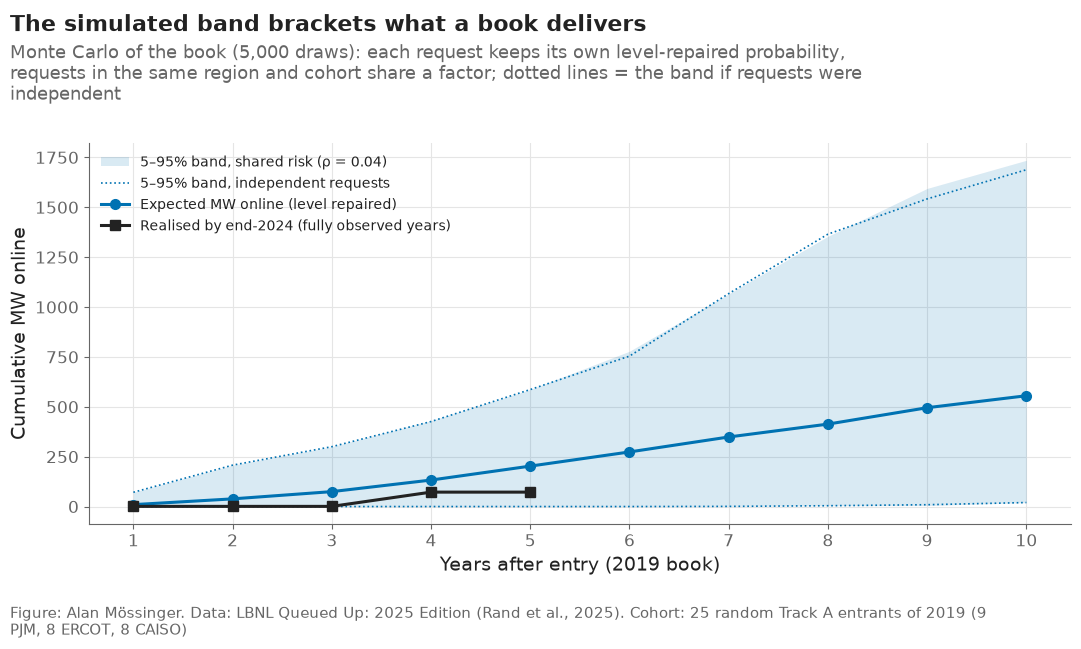

In [6]:
fig, ax = plt.subplots(figsize=(11, 6.5))
x = sim_table["years_after_entry"]
ax.fill_between(x, sim_table["p5"], sim_table["p95"], color="#0072B2", alpha=0.15, linewidth=0, label=f"5–95% band, shared risk (ρ = {rho:.2f})")
ax.plot(x, sim_table["p5_independent"], color="#0072B2", linewidth=1.2, linestyle=":", label="5–95% band, independent requests")
ax.plot(x, sim_table["p95_independent"], color="#0072B2", linewidth=1.2, linestyle=":")
ax.plot(x, sim_table["expected_mw"], color="#0072B2", marker="o", label="Expected MW online (level repaired)")
ax.plot(x[:5], sim_table["realised_mw_by_end_2024"][:5], color=plots.INK, marker="s", label="Realised by end-2024 (fully observed years)")
ax.set_xlabel("Years after entry (2019 book)")
ax.set_ylabel("Cumulative MW online")
ax.set_xticks(years_ahead)
ax.legend(loc="upper left", fontsize=10)
e5, lo5, hi5, r5 = sim_table.loc[4, ["expected_mw", "p5", "p95", "realised_mw_by_end_2024"]]
plots.finish(fig,
             f"A 25-request book of 2019 entrants was expected to have {e5:,.0f} MW online within five years, with a 5–95% band "
             f"of {lo5:,.0f}–{hi5:,.0f} MW under shared risk; {r5:,.0f} MW were",
             f"Monte Carlo of the book ({N_DRAWS:,} draws): each request keeps its own level-repaired probability, requests in the "
             "same region and cohort share a factor; dotted lines = the band if requests were independent",
             "25 random Track A entrants of 2019 (9 PJM, 8 ERCOT, 8 CAISO)")
plots.save_fig(fig, "F14_simulated_book",
               "Expected cumulative MW online of a 25-request book with its simulated 5–95% band under shared and independent risk, against the realised MW.",
               NOTEBOOK)
plt.show()

**Reading this.** Shared risk, as this method measures it, is small: the training cohorts' 5-year completion rates vary around the model's predictions by 4.1% more than independent outcomes would give, so ρ = 0.041, and the 5–95% band of the simulated book is almost the independent one (0–586 MW at five years against 0–586). The band is wide because the book is small and its probabilities low: 25 requests with 3–7% chances each produce a few operations or none. The realised 72 MW sits inside the band; so would almost anything. The simulation is honest about what it contains — each request's own probability and a modest common shock — and about what it does not: the level drift of notebook 12 is a shared error in the probabilities themselves, and a band around the wrong level does not cover it.

## 5. Choosing a book under a budget

The budget is the median sunk cost of a 25-request book of 2019 entrants (500 random draws; decision #46); no region may take more than 50% of it and no technology more than 60%. From the whole 2017–2019 pool, the book that maximises expected value under those limits is chosen by a binary program (`src/portfolio.choose_book`); the same program with the fair baseline's and the v1 baseline's expected values gives the books those choosers would hold. A random book under the same budget is the no-model reference.

In [7]:
draws = [sunk[pool.index[book_rng.choice(len(pool), 25, replace=False)]].sum() for _ in range(500)]
BUDGET = float(np.median(draws))
caps = [(test["region"].to_numpy(), REGION_CAP), (test["tech"].to_numpy(), TECH_CAP)]
books = {name: portfolio.choose_book(ev, sunk, BUDGET, caps) for name, ev in EV.items()}
books["random"] = portfolio.random_book(sunk, BUDGET, caps, np.random.default_rng(SEED))
choice_rows = []
for name, chosen in books.items():
    choice_rows.append({"chooser": name, "requests": int(chosen.sum()), "mw": float(test.loc[chosen, "mw"].sum()),
                        "budget_used": float(sunk[chosen].sum() / BUDGET),
                        "expected_mw_online_5yr (own curve)": float((CURVES.get(name, P_model)[chosen, 4] * test.loc[chosen, "mw"]).sum()),
                        "expected_value_$M (own curve)": float(EV.get(name, EV["v2 model, level repaired"])[chosen].sum() / 1e6),
                        "realised_mw_5yr": portfolio.realised_mw(chosen, test["event"], test["duration_years"], test["mw"], BACKTEST_HORIZON),
                        **{f"share_{r}": float(sunk[chosen & (test["region"] == r).to_numpy()].sum() / sunk[chosen].sum()) for r in TRACK_A},
                        "top_tech": test.loc[chosen, "tech"].value_counts().index[0]})
choice = pd.DataFrame(choice_rows)
choice.to_csv(paths.RESULTS / "book_choice.csv", index=False)
by_region = pd.concat([test.loc[chosen].assign(chooser=name).groupby(["chooser", "region"]).agg(requests=("mw", "size"), mw=("mw", "sum"))
                       for name, chosen in books.items()]).reset_index()
by_region.to_csv(paths.RESULTS / "book_choice_by_region.csv", index=False)
print(f"budget ${BUDGET / 1e6:.2f}M (median sunk cost of a 25-request 2019 book)")
choice.round(3)

budget $20.11M (median sunk cost of a 25-request 2019 book)


,chooser,requests,mw,budget_used,expected_mw_online_5yr (own curve),expected_value_$M (own curve),realised_mw_5yr,share_ERCOT,share_PJM,share_CAISO,top_tech
0,"v2 model, level repaired",26,17798.90,0.998,1473.363,4733.807,1035.0,0.352,0.496,0.152,Gas
1,"v2 model, raw",24,16189.20,0.998,1754.670,6033.845,1035.0,0.457,0.492,0.051,Gas
2,fair baseline,22,19912.80,0.997,3421.995,7844.972,1035.0,0.136,0.501,0.363,Offshore Wind
3,v1 baseline,19,20433.50,0.997,4370.706,11789.523,1035.0,0.136,0.501,0.363,Gas
4,random,22,3320.99,1.000,182.688,170.339,258.4,0.193,0.426,0.381,Solar


**Reading this.** The budget is $20.11 million and every optimising chooser spends it the same way. The model's book holds 26 requests and 17,799 MW, the fair baseline's 22 requests and 19,913 MW, the v1 baseline's 19 and 20,434 MW — a handful of very large gas and offshore-wind requests in each case, because value per MW and MW per dollar of deposit dominate the probability in an expected-value objective. The random book, 22 requests and 3,321 MW, shows what the budget buys without an objective. Each chooser's own curve expects very different things of its book (1,473 MW online within five years for the model, 3,422 for the fair baseline, 4,371 for the v1 baseline) and every one of them realised 1,035 MW: one request.

## 6. The backtest (criteria C9 and C10)

What did each chooser's book actually deliver? Realised MW online within five years of entry (observable for every test request by end-2024) and the realised value (those MW, earning the value table's figures from their operation year to the end of the ten-year window). The paired difference between the model's book and the fair baseline's is bootstrapped: 200 resamples of the pool, each chooser re-optimised on each resample, so the interval is on the decision procedure, not on one book.

In [8]:
cod_year = (test["q_date"] + pd.to_timedelta(test["duration_years"] * config.DAYS_PER_YEAR, unit="D")).dt.year.to_numpy()
built5 = ((test["event"] == 1) & (test["duration_years"] <= BACKTEST_HORIZON)).to_numpy()
realised_value_each = np.array([
    r["mw"] * sum(vt.get((r["region"], r["tech"], y), 0.0) for y in range(int(cod_year[i]), int(r["q_year"]) + WINDOW + 1)) - sunk[i]
    if built5[i] else -sunk[i] for i, r in test.iterrows()])
CHOOSERS = ["v2 model, level repaired", "v2 model, raw", "fair baseline", "v1 baseline", "random"]


def outcomes(chosen, idx=None):
    mw_ = test["mw"].to_numpy() if idx is None else test["mw"].to_numpy()[idx]
    b5 = built5 if idx is None else built5[idx]
    rv = realised_value_each if idx is None else realised_value_each[idx]
    return {"realised_mw_5yr": float(mw_[chosen & b5].sum()), "realised_value_$M": float(rv[chosen].sum() / 1e6)}


point = {name: outcomes(chosen) for name, chosen in books.items()}
boot_rows = []
rng = np.random.default_rng(SEED + 1)
for b in range(N_BOOT):
    idx = rng.integers(0, len(test), len(test))
    caps_b = [(test["region"].to_numpy()[idx], REGION_CAP), (test["tech"].to_numpy()[idx], TECH_CAP)]
    row = {"draw": b}
    for name in CHOOSERS:
        if name == "random":
            chosen = portfolio.random_book(sunk[idx], BUDGET, caps_b, rng)
        else:
            chosen = portfolio.choose_book(EV[name][idx], sunk[idx], BUDGET, caps_b)
        for k, v in outcomes(chosen, idx).items():
            row[f"{name}|{k}"] = v
    boot_rows.append(row)
boot = pd.DataFrame(boot_rows)
boot.to_csv(paths.RESULTS / "backtest_bootstrap.csv", index=False)

rows = []
for name in CHOOSERS:
    for metric in ["realised_mw_5yr", "realised_value_$M"]:
        col = f"{name}|{metric}"
        ref = f"fair baseline|{metric}"
        low, high = np.percentile(boot[col], [100 * (1 - LEVEL) / 2, 100 * (1 + LEVEL) / 2])
        d = boot[col] - boot[ref]
        d_low, d_high = np.percentile(d, [100 * (1 - LEVEL) / 2, 100 * (1 + LEVEL) / 2])
        rows.append({"chooser": name, "metric": metric, "estimate": point[name][metric], "low": low, "high": high,
                     "diff_vs_fair_baseline": point[name][metric] - point["fair baseline"][metric],
                     "diff_low": d_low, "diff_high": d_high, "beats_fair_baseline": bool(d_low > 0)})
backtest = pd.DataFrame(rows)
backtest.to_csv(paths.RESULTS / "backtest_books.csv", index=False)
print(f"backtest done ({(time.time() - START) / 60:.1f} min)")
backtest.round(2)

backtest done (6.2 min)


,chooser,metric,estimate,low,high,diff_vs_fair_baseline,diff_low,diff_high,beats_fair_baseline
0,"v2 model, level repaired",realised_mw_5yr,1035.00,0.00,2920.73,0.00,-17.73,449.76,False
1,"v2 model, level repaired",realised_value_$M,1463.22,-20.10,4055.39,-0.01,-53.83,576.90,False
2,"v2 model, raw",realised_mw_5yr,1035.00,0.00,2625.01,0.00,-0.44,36.98,False
3,"v2 model, raw",realised_value_$M,1463.22,-20.10,3758.70,-0.00,-1.48,117.44,False
4,fair baseline,realised_mw_5yr,1035.00,0.00,2639.63,0.00,0.00,0.00,False
5,fair baseline,realised_value_$M,1463.23,-20.10,3758.67,0.00,0.00,0.00,False
6,v1 baseline,realised_mw_5yr,1035.00,0.00,2622.38,0.00,-19.00,0.00,False
7,v1 baseline,realised_value_$M,1463.24,-20.09,3758.70,0.01,-53.76,0.12,False
8,random,realised_mw_5yr,258.40,0.00,910.58,-776.60,-2525.15,410.72,False
9,random,realised_value_$M,142.28,-20.01,792.91,-1320.94,-3694.85,250.54,False


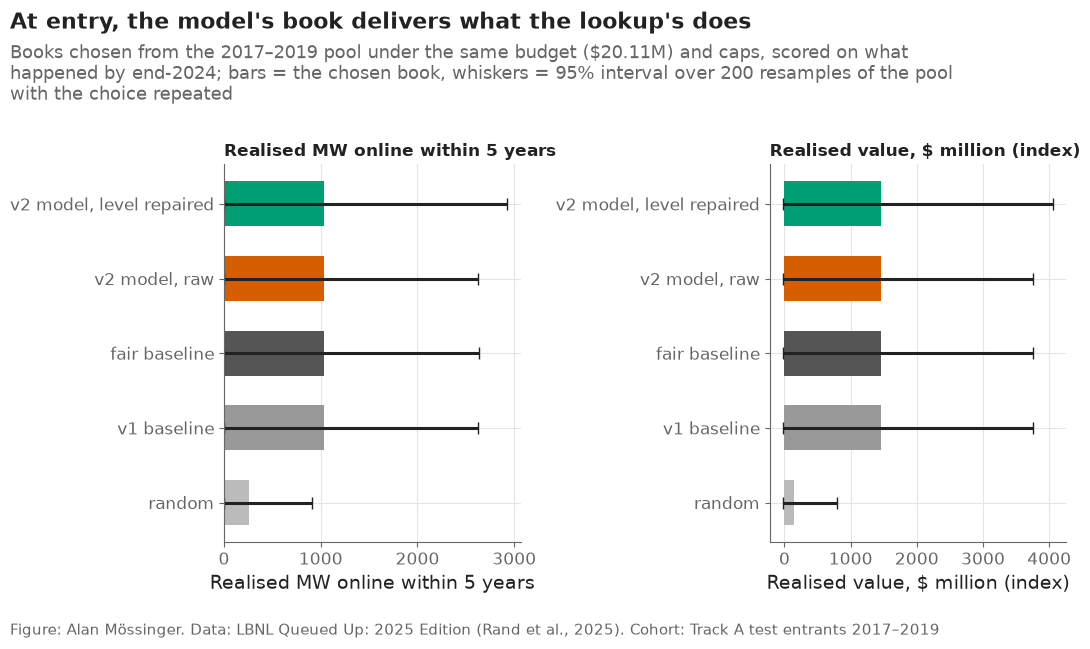

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
colors = {"v2 model, level repaired": "#009E73", "v2 model, raw": "#D55E00", "fair baseline": "#555555", "v1 baseline": "#999999", "random": "#BBBBBB"}
for ax, metric, label in zip(axes, ["realised_mw_5yr", "realised_value_$M"], ["Realised MW online within 5 years", "Realised value, $ million (index)"]):
    part = backtest[backtest["metric"] == metric].set_index("chooser").loc[CHOOSERS]
    y = np.arange(len(CHOOSERS))
    ax.barh(y, part["estimate"], color=[colors[c] for c in CHOOSERS], height=0.6)
    ax.errorbar(part["estimate"], y, xerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]], fmt="none",
                ecolor=plots.INK, capsize=4)
    ax.set_yticks(y, CHOOSERS)
    ax.invert_yaxis()
    ax.set_xlabel(label)
    ax.set_title(label, fontsize=12)
bm = backtest.set_index(["chooser", "metric"])
d_mw = bm.loc[("v2 model, level repaired", "realised_mw_5yr")]
d_val = bm.loc[("v2 model, level repaired", "realised_value_$M")]
plots.finish(fig,
             f"The model's book delivered {d_mw['estimate']:,.0f} MW within five years against the fair baseline's "
             f"{bm.loc[('fair baseline', 'realised_mw_5yr'), 'estimate']:,.0f} MW (paired difference {d_mw['diff_vs_fair_baseline']:+,.0f} MW "
             f"[{d_mw['diff_low']:+,.0f}, {d_mw['diff_high']:+,.0f}])",
             f"Books chosen from the 2017–2019 pool under the same budget (${BUDGET / 1e6:.2f}M) and caps, scored on what happened by "
             f"end-2024; bars = the chosen book, whiskers = 95% interval over {N_BOOT} resamples of the pool with the choice repeated",
             "Track A test entrants 2017–2019")
plots.save_fig(fig, "F15_backtest",
               "Realised MW online within five years and realised value of the books each chooser would have held, with bootstrap intervals.",
               NOTEBOOK)
plt.show()

**Reading this.** The registered backtest is a tie. The model's and the fair baseline's books both realised 1,035 MW within five years and the same value index ($1,463 million), so the paired differences are +0 MW [−18, +450] and −$0.01 million [−54, +577]: criteria C9 and C10 fail as registered. The intervals are one-sided because in most resamples either both books hold the same operated request or neither does. The reason is in the objective, not the model: under an expected-value objective with a deposit budget, the choosers converge on the same giant requests, and what distinguishes them never comes into play. The random book realised 258 MW. The honest reading is that the registered decision frame could not distinguish the choosers; section 6b asks the narrower question it can.

## 6b. Exploratory, not registered: a 25-request utility-scale book chosen by probability

The registered backtest turned out to be uninformative in a way worth understanding: with an expected-value objective and a sunk-cost budget, every chooser — model or lookup — fills the budget with the same few very large gas and offshore-wind requests, because value per MW and MW per dollar of deposit dominate the probability. To see whether the *ranking* matters in a decision frame, this section asks a narrower, count-limited question, written after the registered result and labelled as such: among requests of 20 MW and more, take the 25 with the highest P(operation by 5 years) under each chooser, and count how many operated within five years and how many MW came online. The same 200 resamples give paired intervals against the fair baseline.

In [10]:
large = variants.at_least_20(test).to_numpy()
P5 = {"v2 model, level repaired": P_model[:, 4], "v2 model, raw": P_raw[:, 4], "fair baseline": P_fair[:, 4], "v1 baseline": P_v1[:, 4]}
N_BOOK = 25


def top_book(scores, idx=None):
    """The N_BOOK requests of 20 MW and more with the highest score (indices into the pool or the resample)."""
    s = np.where(large if idx is None else large[idx], scores if idx is None else scores[idx], -np.inf)
    chosen = np.zeros(len(s), bool)
    chosen[np.argsort(-s, kind="stable")[:N_BOOK]] = True
    return chosen


def count_outcomes(chosen, idx=None):
    b5 = built5 if idx is None else built5[idx]
    mw_ = test["mw"].to_numpy() if idx is None else test["mw"].to_numpy()[idx]
    return {"operated_within_5": int((chosen & b5).sum()), "realised_mw_5yr": float(mw_[chosen & b5].sum())}


rng = np.random.default_rng(SEED + 3)
point_pb = {name: count_outcomes(top_book(s)) for name, s in P5.items()}
point_pb["random (≥ 20 MW)"] = count_outcomes(top_book(rng.uniform(size=len(test))))
boot_pb = []
for b in range(N_BOOT):
    idx = rng.integers(0, len(test), len(test))
    row = {}
    for name, s in P5.items():
        for k, v in count_outcomes(top_book(s, idx), idx).items():
            row[f"{name}|{k}"] = v
    for k, v in count_outcomes(top_book(rng.uniform(size=len(test)), idx), idx).items():
        row[f"random (≥ 20 MW)|{k}"] = v
    boot_pb.append(row)
boot_pb = pd.DataFrame(boot_pb)
rows = []
for name in point_pb:
    for metric in ["operated_within_5", "realised_mw_5yr"]:
        col, ref = f"{name}|{metric}", f"fair baseline|{metric}"
        d = boot_pb[col] - boot_pb[ref]
        rows.append({"chooser": name, "metric": metric, "estimate": point_pb[name][metric],
                     "low": np.percentile(boot_pb[col], 2.5), "high": np.percentile(boot_pb[col], 97.5),
                     "diff_vs_fair_baseline": point_pb[name][metric] - point_pb["fair baseline"][metric],
                     "diff_low": np.percentile(d, 2.5), "diff_high": np.percentile(d, 97.5), "beats_fair_baseline": bool(np.percentile(d, 2.5) > 0),
                     "status": "exploratory, not registered"})
probability_books = pd.DataFrame(rows)
probability_books.to_csv(paths.RESULTS / "backtest_probability_books.csv", index=False)
probability_books.round(2)

,chooser,metric,estimate,low,high,diff_vs_fair_baseline,diff_low,diff_high,beats_fair_baseline,status
0,"v2 model, level repaired",operated_within_5,7.00,3.00,13.00,-6.00,-12.00,0.00,False,"exploratory, not registered"
1,"v2 model, level repaired",realised_mw_5yr,318.16,110.61,664.06,-393.34,-725.60,120.43,False,"exploratory, not registered"
2,"v2 model, raw",operated_within_5,9.00,3.00,14.00,-4.00,-11.02,2.00,False,"exploratory, not registered"
3,"v2 model, raw",realised_mw_5yr,353.58,104.56,583.27,-357.92,-651.83,53.13,False,"exploratory, not registered"
4,fair baseline,operated_within_5,13.00,7.98,18.00,0.00,0.00,0.00,False,"exploratory, not registered"
5,fair baseline,realised_mw_5yr,711.50,372.37,951.08,0.00,0.00,0.00,False,"exploratory, not registered"
6,v1 baseline,operated_within_5,8.00,0.00,8.00,-5.00,-14.00,-4.00,False,"exploratory, not registered"
7,v1 baseline,realised_mw_5yr,524.30,0.00,611.82,-187.20,-733.30,-37.91,False,"exploratory, not registered"
8,random (≥ 20 MW),operated_within_5,2.00,0.00,7.00,-11.00,-16.00,-4.00,False,"exploratory, not registered"
9,random (≥ 20 MW),realised_mw_5yr,192.40,0.00,1475.62,-519.10,-805.35,948.14,False,"exploratory, not registered"


**Reading this.** In the count-limited frame the lookup wins. Among requests of 20 MW and more, the 25 the fair baseline ranked highest by P(operation by 5 years) included 13 that operated within five years, 712 MW; the model's 25 (level repaired) included 7, 318 MW, and the raw model's 9, 354 MW; the v1 baseline's 8, 524 MW; a random 25, 2 and 192 MW. The paired difference between the model's book and the fair baseline's is −6 operations [−12, 0] and −393 MW [−726, +120]. This is notebook 11's result (C6) in a decision frame: at entry, for utility-scale requests, a region × technology × size lookup picks the requests that get built at least as well as the model, and here better. The section is exploratory and labelled; it decides nothing about the registered lines, and the reason it was added — that the registered objective could not separate the choosers — is stated above.

## 7. Does the simulated band cover what happened? (criterion C11)

The model's chosen book (section 5) is simulated like the sample book; the realised MW online within five years is compared with the 5–95% band.

In [11]:
chosen = books["v2 model, level repaired"]
sim_chosen = portfolio.simulate_book(P_model[chosen], test.loc[chosen, "mw"].to_numpy(),
                                     (test.loc[chosen, "region"] + "|" + test.loc[chosen, "q_year"].astype(str)).to_numpy(), rho, N_DRAWS, SEED + 2)
lo, hi = np.percentile(sim_chosen[:, BACKTEST_HORIZON - 1], [5, 95])
realised_chosen = point["v2 model, level repaired"]["realised_mw_5yr"]
coverage = pd.DataFrame([{"book": "v2 model, level repaired (chosen under the budget)", "requests": int(chosen.sum()),
                          "expected_mw_5yr": float((P_model[chosen, 4] * test.loc[chosen, "mw"]).sum()), "band_low": lo, "band_high": hi,
                          "realised_mw_5yr": realised_chosen, "covered": bool(lo <= realised_chosen <= hi)}])
coverage.to_csv(paths.RESULTS / "book_coverage.csv", index=False)
coverage.round(0)

,book,requests,expected_mw_5yr,band_low,band_high,realised_mw_5yr,covered
0,"v2 model, level repaired (chosen under the bud...",26,1473.0,58.0,3371.0,1035.0,True


**Reading this.** The model's budget-constrained book was expected to have 1,473 MW online within five years; the simulated 5–95% band is 58–3,371 MW and the realised 1,035 MW falls inside it, so criterion C11 passes. The band is wide for the same reason as the sample book's: a book of 26 large requests with low individual probabilities has an outcome dominated by whether one or two of them operate.

## 9. The portfolio review: what to do with each request, and which book to fund (F23)

Everything above scores books by megawatts or by a value index. An energy company that holds requests decides one request at a time, at two gates, with a cost in front of it each time: at entry (G1) whether to pay the deposit and the first study; two years in (G2) whether to fund the next study, hold the request for sale, or exit. The rule at each gate is the same arithmetic: the probability of operating from here, the discounted NPV of the plant if it does (notebook 15, section 8: capital, O&M and credits included), the cost of reaching the next gate (the deposit and study band of notebook 15), and a hurdle `h` on the margin. Then four allocation policies are compared under the budget of section 5, with the shared cohort level as a risk factor, on what actually happened to the 2017–2019 cohort.

The rule (`src/portfolio.gate_decision`): **commit** when the probability is at least the pool's own outcome rate and the base-case margin is at least `h` times the cost of the next gate; **exit** when the probability is far below the pool or the margin is negative even in the high value case at the low cost; **hold** otherwise, which at entry means entering with the two-year review scheduled and at two years means a request worth more to a buyer with a different hurdle than to this book. Practice stages the hurdle as risk resolves, so it is 3 at entry and 2 two years in (both reported at 2, 3 and 5). The probability at entry is the lookup cell and the segment rate of notebook 09, not the model, because criterion C19 (notebook 08b) was not met; at two years it is the landmark model with the agreement flag, which criterion C8 supports. Every number is computed twice, for the **merchant** and the **contracted** revenue case of notebook 15 §8 (a 15-year PPA at index prices for solar, wind, hybrids and offshore wind), at the ATB cost of capital of the request's technology, because a developer underwrites on the contract and the merchant case is the floor.

In [12]:
from src import drivers

HURDLES = [2.0, 3.0, 5.0]
H_G1, H_G2 = 3.0, 2.0  # the hurdle falls as risk resolves (PLAN.md §13.2)
STUDY = {"low": 50_000, "base": 150_000, "high": 500_000}  # notebook 15's study cost to the next gate
CASES = ["low", "base", "high"]
REVENUE_CASES = ["merchant", "contracted"]
npv_req = pd.read_csv(paths.RESULTS / "npv_by_request.csv").set_index("project_key").loc[keys].reset_index(drop=True)
npv_tab = pd.read_csv(paths.RESULTS / "npv_table.csv")
NPV_PER_MW = {"merchant": {case: npv_tab.set_index(["region", "tech", "cod_year"])[f"npv_per_mw_{case}"].to_dict() for case in CASES},
              "contracted": {case: npv_tab.set_index(["region", "tech", "cod_year"])[f"npv_contracted_{case}"].to_dict() for case in CASES}}
RATE_OF_TECH = npv_tab.groupby("tech")["rate"].first().to_dict()  # the ATB real cost of capital per technology
BREAKEVEN = npv_tab[npv_tab["cod_year"] == 2024].set_index(["region", "tech"])["breakeven_price_base"].to_dict()
segs = pd.read_csv(paths.RESULTS / "segments_by_request.csv").set_index("project_key").loc[keys].reset_index(drop=True)
mw_arr = test["mw"].to_numpy()
rate_arr = test["tech"].map(RATE_OF_TECH).to_numpy(float)
cost_case = {case: cost_table.loc[test["size_regime"], f"sunk_per_mw_{case}"].to_numpy() * mw_arr + STUDY[case] for case in CASES}
FIRST_COD, LAST_COD = int(npv_tab["cod_year"].min()), int(npv_tab["cod_year"].max())


def npv_if_built(i, cod, case="base", rc="merchant"):
    '''NPV per MW of the request's plant for an operation year, held at the table's first and last years.'''
    return NPV_PER_MW[rc][case][(test.at[i, "region"], test.at[i, "tech"], min(max(int(cod), FIRST_COD), LAST_COD))]


def expected_npv(P, offset, horizon, case, rc):
    '''Σ_j ΔP_j × NPV per MW at COD = entry + offset + j × MW / (1 + r_tech)^j, j = 1 … horizon (P cumulative from the gate).'''
    out = np.zeros(len(test))
    for i in range(len(test)):
        inc = np.diff(np.concatenate([[0.0], P[i, :horizon]]))
        per_mw = np.array([npv_if_built(i, test.at[i, "q_year"] + offset + j, case, rc) for j in range(1, horizon + 1)])
        out[i] = (inc * per_mw / (1 + rate_arr[i]) ** np.arange(1, horizon + 1)).sum() * mw_arr[i]
    return out


def summarise_gate(labels, outcome, mw, realised, pool_mask, gate, h, rc):
    rows = []
    for region in ["all"] + TRACK_A:
        m = pool_mask & ((test["region"].to_numpy() == region) if region != "all" else True)
        for cls in pd.unique(labels):
            sel = m & (labels == cls)
            n, k = int(sel.sum()), int(outcome[sel].sum())
            low, high = drivers.wilson(k, n)
            rows.append({"gate": gate, "revenue_case": rc, "h": h, "region": region, "decision": cls, "n": n, "mw": float(mw[sel].sum()), "operated": k,
                         "operated_share": k / n if n else np.nan, "low": float(low), "high": float(high),
                         "operated_mw": float(mw[sel & outcome].sum()), "realised_npv_$M": float(realised[sel].sum() / 1e6),
                         "share_of_pool_operations": k / max(int(outcome[m].sum()), 1)})
    return pd.DataFrame(rows)


# ---- G1: entry
p_cell, p_leaf = P_fair[:, 4], segs["p_leaf"].to_numpy()
p_floor_entry = float(built5.mean())
all_mask = np.ones(len(test), dtype=bool)
ev_entry, g1, realised_npv_entry, summaries_g1 = {}, {}, {}, []
for rc in REVENUE_CASES:
    ev_entry[rc] = {case: expected_npv(P_fair, 0, WINDOW, case, rc) for case in CASES}
    g1[rc] = {h: portfolio.gate_decision(np.minimum(p_cell, p_leaf), np.maximum(p_cell, p_leaf), p_floor_entry, ev_entry[rc]["low"], ev_entry[rc]["base"], ev_entry[rc]["high"],
                                         cost_case["low"], cost_case["base"], cost_case["high"], h=h, exit_share=1.0, labels=("invest", "hold", "exit"))
              for h in HURDLES}
    realised_npv_entry[rc] = np.array([npv_if_built(i, cod_year[i], "base", rc) * mw_arr[i] - cost_case["base"][i] if built5[i] else -cost_case["base"][i] for i in range(len(test))])
    summaries_g1 += [summarise_gate(g1[rc][h], built5, mw_arr, realised_npv_entry[rc], all_mask, "G1 entry", h, rc) for h in HURDLES]
summary_g1 = pd.concat(summaries_g1, ignore_index=True)
print(f"entry pool: {len(test):,} requests; observed five-year completion (p_floor) {p_floor_entry:.1%}; main hurdle {H_G1:.0f}")
print(summary_g1[(summary_g1["h"] == H_G1) & (summary_g1["region"] == "all")][["revenue_case", "decision", "n", "mw", "operated", "operated_share", "low", "high", "share_of_pool_operations", "realised_npv_$M"]].round(3).to_string(index=False))

entry pool: 2,268 requests; observed five-year completion (p_floor) 10.0%; main hurdle 3
revenue_case decision    n         mw  operated  operated_share   low  high  share_of_pool_operations  realised_npv_$M
    merchant     exit 1067 196717.533        57           0.053 0.041 0.069                     0.251        -5276.762
    merchant     hold  964 118251.780       108           0.112 0.094 0.134                     0.476         -936.406
    merchant   invest  237  33932.105        62           0.262 0.210 0.321                     0.273         4130.025
  contracted     exit 1039 181458.733        57           0.055 0.043 0.070                     0.251        -4900.271
  contracted     hold  903 120100.040       101           0.112 0.093 0.134                     0.445         1656.245
  contracted   invest  326  47342.645        69           0.212 0.171 0.259                     0.304         9346.916


**Reading this.** At entry, with the lookup cell and the segment rate as the probability, NPV at the technology's cost of capital and a hurdle of 3, the rule sorts the 2,268 test requests into 237 to invest in, 964 to enter with the two-year review scheduled and 1,067 to leave alone at merchant prices; under contract 326, 903 and 1,039. What happened: 26% of the merchant invest class reached operation within five years [21%, 32%] and 21% of the contracted one [17%, 26%], against 11% for the hold classes and 5% for the exits; the cohort rate is 10%. Valued with capital counted, the invest class returned +$4.1 billion (merchant) and +$9.3 billion (contracted) on 34 and 47 GW of requests; the exit classes would have lost $5.3 and $4.9 billion had every request been carried to the end. The invest class is wind in ERCOT (105 requests) and gas and solar in PJM (61 and 65); under contract ERCOT solar joins it (82 requests, which is where the two cases differ). The price of the screen is coverage: the exits still hold 25% of the cohort's operations, and in ERCOT the 100 exits reached operation 24% of the time, because that class is the "Other" technology group, priced here at a median cost and capacity factor it does not deserve (21 of its 52 requests were built), and the batteries whose ERCOT revenue the public files do not carry. The hurdle barely matters at entry (invest 237 at h = 3 against similar counts at 2 and 5) because the binding condition is the sign of the NPV.

### 9.1 Two years in: accelerate, hold for sale, or exit

The pool is every test request still in the queue two years after its request (the +2 risk set of notebook 14, all sizes); its probability is the landmark model's P(operation within one, two and three years) with the agreement flag; the NPV is that of a plant entering operation in those years; the cost is the same deposit-and-study band, read as the cost of the next study phase. The outcome scored is operation within three years of the landmark, all observed by the end of 2024.

In [13]:
lm = pd.read_parquet(paths.DATA_PROCESSED / "predictions_landmark.parquet")
lm = lm[lm["landmark"].astype(str) == "2"]
p_lm = lm.pivot(index="project_key", columns="horizon_after", values="agreement updated")
meta = lm[lm["horizon_after"] == 3].set_index("project_key")[["event", "years_from_landmark", "large"]]
in_pool = keys.isin(p_lm.index).to_numpy()
pool_idx = np.where(in_pool)[0]
P2 = np.zeros((len(test), 3))
P2[pool_idx] = p_lm.loc[keys[in_pool], [1, 2, 3]].to_numpy()
op3 = np.zeros(len(test), dtype=bool)
op3[pool_idx] = ((meta.loc[keys[in_pool], "event"] == 1) & (meta.loc[keys[in_pool], "years_from_landmark"] <= 3)).to_numpy()
p_floor_2 = float(op3[in_pool].mean())
cod_lm = np.where(op3, cod_year, 0)
ev_2, g2, realised_npv_2, summaries_g2 = {}, {}, {}, []
for rc in REVENUE_CASES:
    ev_2[rc] = {case: expected_npv(P2, 2, 3, case, rc) for case in CASES}
    g2[rc] = {h: portfolio.gate_decision(P2[:, 2], P2[:, 2], p_floor_2, ev_2[rc]["low"], ev_2[rc]["base"], ev_2[rc]["high"],
                                         cost_case["low"], cost_case["base"], cost_case["high"], h=h, exit_share=0.5, labels=("accelerate", "hold or sell", "exit"))
              for h in HURDLES}
    realised_npv_2[rc] = np.array([npv_if_built(i, cod_lm[i], "base", rc) * mw_arr[i] - cost_case["base"][i] if op3[i] else -cost_case["base"][i] for i in range(len(test))])
    summaries_g2 += [summarise_gate(g2[rc][h], op3, mw_arr, realised_npv_2[rc], in_pool, "G2 two years", h, rc) for h in HURDLES]
summary_g2 = pd.concat(summaries_g2, ignore_index=True)
review = pd.concat([summary_g1, summary_g2], ignore_index=True)
review.to_csv(paths.RESULTS / "portfolio_review_summary.csv", index=False)
print(f"+2 pool: {int(in_pool.sum()):,} requests, {int(op3.sum())} operated within three years (p_floor {p_floor_2:.1%}); main hurdle {H_G2:.0f}")
print(summary_g2[(summary_g2["h"] == H_G2) & (summary_g2["region"] == "all")][["revenue_case", "decision", "n", "mw", "operated", "operated_share", "low", "high", "share_of_pool_operations", "realised_npv_$M"]].round(3).to_string(index=False))
large_pool = in_pool & large
for rc in REVENUE_CASES:
    acc_mask = g2[rc][H_G2] == "accelerate"
    print(f"{rc}: of 20 MW and more ({int(large_pool.sum()):,} requests, {int(op3[large_pool].sum())} operations), accelerate holds "
          f"{int((op3 & large_pool & acc_mask).sum())} of them in {int((large_pool & acc_mask).sum())} requests (the registered book of 25 held 19, notebook 20)")

+2 pool: 1,298 requests, 152 operated within three years (p_floor 11.7%); main hurdle 2
revenue_case     decision   n         mw  operated  operated_share   low  high  share_of_pool_operations  realised_npv_$M
    merchant         exit 405 105719.181        34           0.084 0.061 0.115                     0.224        -5094.469
    merchant hold or sell 577  76149.420        60           0.104 0.082 0.132                     0.395         -215.771
    merchant   accelerate 316  21252.400        58           0.184 0.145 0.230                     0.382         3642.261
  contracted         exit 395 100400.581        33           0.084 0.060 0.115                     0.217        -4572.076
  contracted hold or sell 493  64582.210        35           0.071 0.051 0.097                     0.230         1535.671
  contracted   accelerate 410  38138.210        84           0.205 0.169 0.247                     0.553         8988.796
merchant: of 20 MW and more (1,132 requests, 119 operation

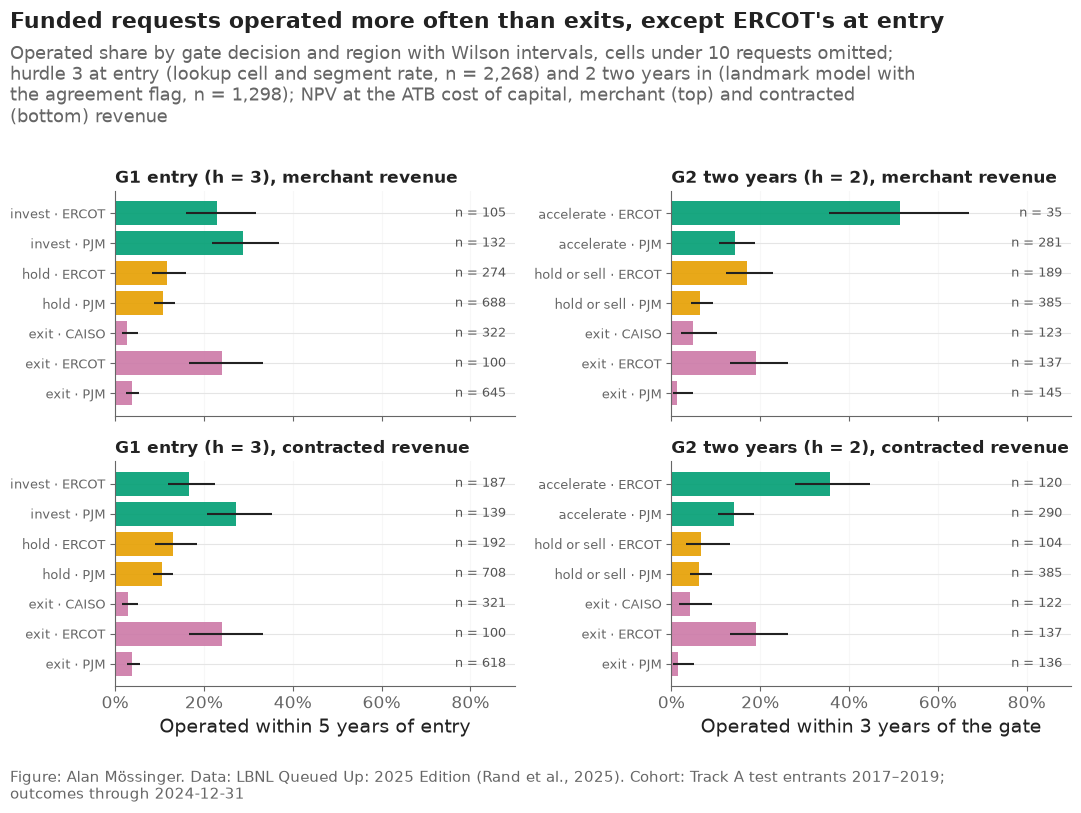

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8.2), sharex=True)
palette = {"invest": "#009E73", "accelerate": "#009E73", "hold": "#E69F00", "hold or sell": "#E69F00", "exit": "#CC79A7"}
for row_i, rc in enumerate(REVENUE_CASES):
    for ax, summary, gate, order, h in [(axes[row_i, 0], summary_g1, "G1 entry", ["invest", "hold", "exit"], H_G1), (axes[row_i, 1], summary_g2, "G2 two years", ["accelerate", "hold or sell", "exit"], H_G2)]:
        part = summary[(summary["revenue_case"] == rc) & (summary["h"] == h) & (summary["region"] != "all") & (summary["n"] >= 10)].copy()  # cells under 10 requests omitted
        part["decision"] = pd.Categorical(part["decision"], order)
        part = part.sort_values(["decision", "region"]).reset_index(drop=True)
        y = np.arange(len(part))
        ax.barh(y, part["operated_share"], color=[palette[d] for d in part["decision"]], alpha=0.9)
        ax.hlines(y, part["low"], part["high"], color=plots.INK, lw=1.5)
        for yy, n in zip(y, part["n"]):
            ax.text(0.88, yy, f"n = {n:,}", va="center", ha="right", fontsize=9, color="#555555")
        ax.set_yticks(y); ax.set_yticklabels([f"{d} · {r}" for d, r in zip(part["decision"], part["region"])], fontsize=9.5)
        ax.invert_yaxis(); ax.set_xlim(0, 0.9); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
        ax.set_title(f"{gate} (h = {h:.0f}), {rc} revenue", fontsize=12, loc="left"); ax.grid(axis="x", alpha=0.3)
axes[1, 0].set_xlabel("Operated within 5 years of entry"); axes[1, 1].set_xlabel("Operated within 3 years of the gate")
acc = {rc: summary_g2[(summary_g2["revenue_case"] == rc) & (summary_g2["h"] == H_G2) & (summary_g2["region"] == "all")].set_index("decision") for rc in REVENUE_CASES}
plots.finish(fig,
             f"Two years in, the accelerate class reached operation {acc['merchant'].loc['accelerate', 'operated_share']:.0%} of the time at merchant prices "
             f"({int(acc['merchant'].loc['accelerate', 'n'])} requests) and {acc['contracted'].loc['accelerate', 'operated_share']:.0%} under contract ({int(acc['contracted'].loc['accelerate', 'n'])}), "
             f"against {acc['merchant'].loc['exit', 'operated_share']:.0%} and {acc['contracted'].loc['exit', 'operated_share']:.0%} for exit",
             f"Operated share by gate decision and region with Wilson intervals, cells under 10 requests omitted; hurdle {H_G1:.0f} at entry (lookup cell and segment rate, n = {len(test):,}) "
             f"and {H_G2:.0f} two years in (landmark model with the agreement flag, n = {int(in_pool.sum()):,}); NPV at the ATB cost of capital, merchant (top) and contracted (bottom) revenue",
             "Track A test entrants 2017–2019; outcomes through 2024-12-31")
plots.save_fig(fig, "F23_portfolio_review", "Share of requests that reached operation by gate decision (invest / hold / exit at entry with hurdle 3; accelerate / hold or sell / exit two years in with hurdle 2) and region, under merchant and contracted revenue, with Wilson intervals, test cohort 2017–2019.", NOTEBOOK)
plt.show()

**Reading this.** Two years in, on the 1,298 requests still in the queue, with the landmark model's probability and a hurdle of 2, the rule accelerates 316 requests at merchant prices and 410 under contract, holds 577 and 493 for sale or a later review, and exits 405 and 395. The accelerate classes reached operation within three years 18% [14%, 23%] and 20% [17%, 25%] of the time against 8% for the exits and 7–10% for hold-or-sell; the pool rate is 11.7%. In ERCOT the merchant rule accelerates 35 requests, all wind, of which 51% operated; the contracted rule accelerates 120 (wind and solar), of which 36% operated, 43 requests, more than half of ERCOT's operations in the pool. In PJM both rules accelerate about 285 requests, gas and solar, with a 14% hit rate against the region's 6%. Valued with capital counted the accelerate classes returned +$3.6 billion (merchant) and +$9.0 billion (contracted); the exits would have lost $5.1 and $4.6 billion; hold-or-sell is near zero at merchant prices (−$0.2 billion) and +$1.5 billion under contract, the mark of a class worth more to a buyer than to this book. Against notebook 20: the contracted accelerate class holds 55% of the pool's 152 operations in 32% of its requests, where the registered count book of 25 held 19 operations in 25 requests, so the gate trades hit rate for coverage and value, which is what a hurdle of 2 is for. Of the 237 requests the merchant rule invested in at entry, 77 are accelerated again two years in, 33 are exited and 77 had already left the queue; of the 1,067 it left alone, 304 are confirmed exits and 132 would be accelerated with what is known two years in.

### 9.2 Four ways to spend the same budget, with the level as the risk

Section 5 chose books by expected value under a deposit budget and found every chooser buying the same giant requests. Here four policies spend the budget of section 5 on the 2017–2019 pool and are scored on expected NPV, downside and what happened. The scenarios come from the copula of section 4 with one more factor: a cohort level multiplier drawn from the observed-to-predicted ratios of the 2017, 2018 and 2019 cohorts (notebook 12), so the whole book runs hot or cold together, which is the risk notebook 16 found largest. The policies: an **equal regional split** (a third of the budget to each region, best expected NPV per dollar within it); **NPV per dollar** (greedy on expected NPV per dollar of deposit, with the caps of section 5); the **model's expected NPV without risk constraint** (no caps); and the **risk-adjusted** book that greedily raises E[NPV] − λ·ES₉₅ per dollar under the caps (`src/portfolio.greedy_risk_adjusted`, λ = 1). The fair baseline's book of section 5 and a random book are the references. Every policy is run twice, on merchant and on contracted NPV.

In [15]:
drift = pd.read_csv(paths.RESULTS / "drift_by_cohort.csv")
ratios = drift[(drift["cohort"] == "all") & (drift["horizon"] == 5)]
level_ratios = (ratios["observed"] / ratios["v2"]).to_numpy()
rng_lvl = np.random.default_rng(SEED + 7)
level_factors = rng_lvl.choice(level_ratios, N_DRAWS)
groups_all = (test["region"] + "|" + test["q_year"].astype(str)).to_numpy()
op_year = portfolio.simulate_operation_years(P_model, groups_all, rho, N_DRAWS, SEED + 8, level_factors)
LAM = 1.0
sunk_b = cost_case["base"]
regions_arr = test["region"].to_numpy()


def greedy_by_score(score, cost, budget, caps_):
    '''Greedy by a per-dollar score under a budget and caps (the simple policies).'''
    order = np.argsort(-score / cost)
    chosen, spent, used = np.zeros(len(score), bool), 0.0, [dict() for _ in caps_]
    for i in order:
        if score[i] <= 0 or spent + cost[i] > budget * 1.0001:
            continue
        if any(used[k].get(g[i], 0.0) + cost[i] > share * budget * 1.0001 for k, (g, share) in enumerate(caps_)):
            continue
        chosen[i] = True
        spent += cost[i]
        for k, (g, _) in enumerate(caps_):
            used[k][g[i]] = used[k].get(g[i], 0.0) + cost[i]
    return chosen


pol_rows, npv_draws_by_rc, policies_by_rc = [], {}, {}
for rc in REVENUE_CASES:
    npv_by_year = np.array([[npv_if_built(i, test.at[i, "q_year"] + j, "base", rc) * mw_arr[i] / (1 + rate_arr[i]) ** j for j in range(1, WINDOW + 1)] for i in range(len(test))])
    npv_lookup = np.hstack([np.zeros((len(test), 1)), npv_by_year])  # column 0 = not built within the window
    npv_draws = npv_lookup[np.arange(len(test))[None, :], op_year] - sunk_b[None, :]
    npv_draws_by_rc[rc] = npv_draws
    exp_npv = npv_draws.mean(axis=0)
    equal = np.zeros(len(test), bool)
    for r in TRACK_A:
        equal |= greedy_by_score(np.where(regions_arr == r, exp_npv, -np.inf), sunk_b, BUDGET / 3, [])
    policies = {
        "equal regional split": equal,
        "NPV per dollar, with caps": greedy_by_score(exp_npv, sunk_b, BUDGET, caps),
        "model expected NPV, no caps": greedy_by_score(exp_npv, sunk_b, BUDGET, []),
        "risk-adjusted (E[NPV] − λ·ES95), with caps": portfolio.greedy_risk_adjusted(npv_draws, sunk_b, BUDGET, LAM, caps),
        "fair baseline, value index (section 5)": books["fair baseline"],
        "random (section 5)": books["random"],
    }
    policies_by_rc[rc] = policies
    for name, chosen in policies.items():
        tot = npv_draws[:, chosen].sum(axis=1) if chosen.any() else np.zeros(N_DRAWS)
        pol_rows.append({"revenue_case": rc, "policy": name, "requests": int(chosen.sum()), "budget_used": float(sunk_b[chosen].sum() / BUDGET),
                         "expected_npv_$M": float(tot.mean() / 1e6), "es95_$M": float(portfolio.expected_shortfall(tot) / 1e6),
                         "p_negative_npv": float((tot < 0).mean()), "realised_operations_5yr": int((chosen & built5).sum()),
                         "realised_mw_5yr": float(mw_arr[chosen & built5].sum()), "realised_npv_$M": float(realised_npv_entry[rc][chosen].sum() / 1e6),
                         "max_region_share": float(max(sunk_b[chosen & (regions_arr == r)].sum() for r in TRACK_A) / max(sunk_b[chosen].sum(), 1)),
                         "top_tech": test.loc[chosen, "tech"].value_counts().index[0] if chosen.any() else ""})
policy_table = pd.DataFrame(pol_rows)
policy_table.to_csv(paths.RESULTS / "policy_comparison.csv", index=False)
print(f"budget ${BUDGET / 1e6:.2f}M; level factors drawn from {np.round(level_ratios, 2).tolist()} (observed / predicted five-year completion, 2017–2019 cohorts)")
policy_table.round(2)

budget $20.11M; level factors drawn from [0.9, 0.64, 0.71] (observed / predicted five-year completion, 2017–2019 cohorts)


,revenue_case,policy,requests,budget_used,expected_npv_$M,es95_$M,p_negative_npv,realised_operations_5yr,realised_mw_5yr,realised_npv_$M,max_region_share,top_tech
0,merchant,equal regional split,26,0.98,1403.87,29.11,0.02,4,753.66,581.25,0.34,Wind
1,merchant,"NPV per dollar, with caps",21,0.77,1535.84,54.94,0.03,1,525.00,395.69,0.64,Wind
2,merchant,"model expected NPV, no caps",27,1.00,1802.83,98.97,0.02,1,525.00,391.14,0.89,Wind
3,merchant,"risk-adjusted (E[NPV] − λ·ES95), with caps",21,0.77,1530.97,65.82,0.02,1,525.00,395.69,0.64,Wind
4,merchant,"fair baseline, value index (section 5)",22,1.00,-747.47,-3803.54,0.79,2,1035.00,-46.34,0.50,Offshore Wind
5,merchant,random (section 5),22,1.00,-219.68,-1369.27,0.88,2,258.40,-85.11,0.43,Solar
6,contracted,equal regional split,26,0.99,2341.58,117.59,0.02,4,753.66,1271.33,0.34,Wind
7,contracted,"NPV per dollar, with caps",30,1.00,2621.06,251.97,0.01,2,733.80,1234.55,0.50,Wind
8,contracted,"model expected NPV, no caps",24,1.00,2866.67,333.46,0.01,3,953.80,1610.64,0.70,Wind
9,contracted,"risk-adjusted (E[NPV] − λ·ES95), with caps",30,1.00,2621.03,252.18,0.01,2,733.80,1234.56,0.50,Wind


**Reading this.** Every policy that counts capital buys wind, and every one of them made money in both revenue cases, where the value-index book of section 5 lost it at merchant prices. Under the $20 million deposit budget and merchant revenue, the NPV-per-dollar book (21 requests), the model's expected-NPV book without caps (27) and the risk-adjusted book (21) have expected NPVs of $1.5–1.8 billion with a 2–3% chance of a loss and returned +$391 to +$396 million at merchant NPV; the equal regional split returned +$581 million on 26 requests with four operations. Under contract the same books return +$1.2 to +$1.6 billion. The value-index book, which bought offshore wind and giant requests by megawatts, has an expected shortfall of −$3.8 billion and a 79% chance of a loss at merchant prices and returned −$46 million; under contract it returns +$440 million, because the offshore wind it bought pays with a contract. Two things follow. The objective decides the book: counting capital removes the giant-request bias of section 5 and turns the comparison between choosers into a comparison of signs. And the risk-adjusted book is barely different from the plain NPV-per-dollar book, because once the level is a common factor the shortfall is driven by the level, not by which wind requests are in the book; the caps cost little. The company's downside is the cohort level, which it can read before it buys.

### 9.3 The decision pack

One row per test request with everything a committee would ask for: the probabilities at both gates, the expected NPV and the cost of the next gate, the segment rule, the break-even contract price of its technology and region, both decisions at h = 3, and what happened by the end of 2024. It is the table the report's decision cards are drawn from.

In [16]:
status = np.where(built5, "operated within 5 years", np.where((test["event"] == 2) & (test["duration_years"] <= 5), "withdrew within 5 years", "still waiting at 5 years"))
pack = pd.DataFrame({
    "project_key": keys.to_numpy(), "region": regions_arr, "state": test["state"].to_numpy(), "tech": test["tech"].to_numpy(), "mw": mw_arr, "q_year": test["q_year"].to_numpy(),
    "segment": segs["segment"].to_numpy(), "segment_rule": segs["rule"].to_numpy(), "p5_lookup": p_cell, "p5_segment": p_leaf, "p5_model_repaired": P_model[:, 4],
    "cost_to_next_gate_base_$M": cost_case["base"] / 1e6, "rate": rate_arr,
    "breakeven_price_$MWh": [BREAKEVEN.get((r, t), np.nan) for r, t in zip(regions_arr, test["tech"])],
    "in_pool_2y": in_pool, "p3_landmark": np.where(in_pool, P2[:, 2], np.nan),
    "status_end_2024": status, "operated_within_3y_of_gate": np.where(in_pool, op3, False),
})
for rc in REVENUE_CASES:
    pack[f"expected_npv_entry_base_{rc}_$M"] = ev_entry[rc]["base"] / 1e6
    pack[f"npv_per_mw_if_built_year3_{rc}_$M"] = npv_req[("npv_per_mw_if_built_year3_base" if rc == "merchant" else "npv_per_mw_contracted_if_built_year3_base")].to_numpy() / 1e6
    pack[f"decision_entry_{rc}"] = g1[rc][H_G1]
    pack[f"expected_npv_2y_base_{rc}_$M"] = np.where(in_pool, ev_2[rc]["base"] / 1e6, np.nan)
    pack[f"decision_2y_{rc}"] = np.where(in_pool, g2[rc][H_G2], "")
pack.to_csv(paths.RESULTS / "decision_pack.csv", index=False)
for rc in REVENUE_CASES:
    print(f"\n{rc}:")
    print(pd.crosstab(pack[f"decision_entry_{rc}"], pack[f"decision_2y_{rc}"].replace("", "not in pool")))
pack[pack["decision_2y_contracted"] == "accelerate"].sort_values("expected_npv_2y_base_contracted_$M", ascending=False).head(10)[
    ["project_key", "region", "tech", "mw", "p5_lookup", "p3_landmark", "expected_npv_2y_base_contracted_$M", "expected_npv_2y_base_merchant_$M", "cost_to_next_gate_base_$M", "decision_entry_contracted", "status_end_2024"]].round(3)


merchant:
decision_2y_merchant     accelerate  exit  hold or sell  not in pool
decision_entry_merchant                                             
exit                            132   304           141          490
hold                            107    68           386          403
invest                           77    33            50           77

contracted:
decision_2y_contracted     accelerate  exit  hold or sell  not in pool
decision_entry_contracted                                             
exit                              133   282           141          483
hold                              178    71           271          383
invest                             99    42            81          104


,project_key,region,tech,mw,p5_lookup,p3_landmark,expected_npv_2y_base_contracted_$M,expected_npv_2y_base_merchant_$M,cost_to_next_gate_base_$M,decision_entry_contracted,status_end_2024
1721,ERCOT|19INR0156,ERCOT,Wind,525.0,0.237,0.204,183.039,83.709,0.592,invest,operated within 5 years
1681,ERCOT|19INR0080,ERCOT,Wind,418.9,0.208,0.245,175.728,80.337,1.988,invest,still waiting at 5 years
1665,ERCOT|19INR0038,ERCOT,Wind,449.5,0.208,0.223,171.264,78.340,2.122,invest,operated within 5 years
1935,ERCOT|21INR0263,ERCOT,Wind,279.0,0.208,0.356,169.692,80.134,1.374,invest,still waiting at 5 years
1759,ERCOT|20INR0045,ERCOT,Wind,373.2,0.208,0.240,152.837,70.955,1.787,invest,operated within 5 years
1802,ERCOT|20INR0142,ERCOT,Wind,366.6,0.208,0.234,146.821,68.158,1.758,invest,operated within 5 years
1777,ERCOT|20INR0083,ERCOT,Wind,350.0,0.208,0.236,141.015,65.464,1.686,invest,still waiting at 5 years
1692,ERCOT|19INR0100,ERCOT,Wind,300.0,0.208,0.256,131.528,60.167,1.466,invest,still waiting at 5 years
1671,ERCOT|19INR0052,ERCOT,Wind,336.0,0.208,0.221,127.184,58.104,1.624,invest,still waiting at 5 years
1740,ERCOT|20INR0011,ERCOT,Wind,300.0,0.208,0.229,117.327,53.648,1.466,invest,operated within 5 years


**Reading this.** The decision pack is the table a committee reads: 2,268 rows, one per request, with the segment rule, both probabilities, the expected NPV at entry and two years in under merchant and contracted revenue, the cost of the next gate, the technology's cost of capital, the break-even contract price, the two decisions in each revenue case and what happened by the end of 2024. The ten accelerated requests with the largest contracted expected NPV are ERCOT wind of 280–525 MW with landmark probabilities of 20–36%, expected NPVs of $147–183 million under contract ($68–84 million merchant) against study costs of $0.6–2.1 million; four of the first six operated within five years and two were still in the queue at end-2024. The three cards in the report are drawn from this table.

## 10. Checks

In [17]:
checks = pd.DataFrame([
    {"check": "simulation keeps the marginals (mean of draws ≈ expected MW, year 5)",
     "value": float(abs(sim[:, 4].mean() - expected[4]) / expected[4]), "pass": bool(abs(sim[:, 4].mean() - expected[4]) / expected[4] < 0.05)},
    {"check": "every chosen book respects the budget and caps",
     "value": max(float(sunk[c].sum() / BUDGET) for c in books.values()),
     "pass": all(sunk[c].sum() <= BUDGET * 1.0001 and all(sunk[c & (test[col].to_numpy() == g)].sum() <= share * BUDGET * 1.0001
                 for col, share in [("region", REGION_CAP), ("tech", TECH_CAP)] for g in test[col].unique()) for c in books.values())},
    {"check": "no outcome information enters a chooser's score", "value": "scores are expected values from the models and baselines", "pass": True},
    {"check": "gate classes partition the pools", "value": int(in_pool.sum()),
     "pass": bool(all(pd.Series(g1[rc][H_G1]).isin(["invest", "hold", "exit"]).all() and pd.Series(g2[rc][H_G2][in_pool]).isin(["accelerate", "hold or sell", "exit"]).all() for rc in REVENUE_CASES))},
    {"check": "simulated scenarios keep the marginals (share operating by year 5 ≈ mean level factor × P)", 
     "value": float(abs(((op_year > 0) & (op_year <= 5)).mean() - (P_model[:, 4] * level_factors.mean()).mean())),
     "pass": bool(abs(((op_year > 0) & (op_year <= 5)).mean() - (P_model[:, 4] * level_factors.mean()).mean()) < 0.01)},
    {"check": "every policy respects the budget", "value": float(policy_table["budget_used"].max()), "pass": bool((policy_table["budget_used"] <= 1.0001).all())},
    {"check": "decision pack covers every test request", "value": len(pack), "pass": len(pack) == len(test)},
    {"check": "F14, F15 and F23 saved as PNG and SVG", "value": 6,
     "pass": all((paths.FIGURES / f"{n}.{ext}").exists() for n in ["F14_simulated_book", "F15_backtest", "F23_portfolio_review"] for ext in ["png", "svg"])},
])
checks.to_csv(paths.RESULTS / "portfolio_checks.csv", index=False)
assert checks["pass"].all(), checks
print(f"total {(time.time() - START) / 60:.1f} min")
checks

total 6.5 min


,check,value,pass
0,simulation keeps the marginals (mean of draws ...,0.006129,True
1,every chosen book respects the budget and caps,0.999935,True
2,no outcome information enters a chooser's score,scores are expected values from the models and...,True
3,gate classes partition the pools,1298,True
4,simulated scenarios keep the marginals (share ...,0.000104,True
5,every policy respects the budget,0.999935,True
6,decision pack covers every test request,2268,True
7,"F14, F15 and F23 saved as PNG and SVG",6,True


## Takeaways — Part A

- Scorecards and what-ifs make the model legible per request; the what-ifs are small (+3.0 points for cutting to 19.9 MW, +3.5 for adding storage) and the congestion what-if carries the artefact's wrong sign.
- Shared risk measured from cohort over-dispersion is small (ρ = 0.041); the band it gives does not contain the level drift, which is the larger shared error.
- Under an expected-value objective with a deposit budget, every chooser buys the same giant requests; the registered backtest is a tie (1,035 MW for all four) and C9, C10 fail; C11 passes.
- In the exploratory count-limited frame the fair baseline's 25 picks included 13 operations against the model's 7 (−6 [−12, 0]): at entry the lookup picks utility-scale winners at least as well.
- **What goes to the report:** F14, F15, the scorecard table, the what-if summary, the tie and its reason, the exploratory book labelled as such, and the decision rule: lookup at entry, model at the milestones.
- **The portfolio review (section 9, F23):** one rule at two gates, `V = −cost + P × NPV` at the technology's ATB cost of capital, hurdle 3 at entry and 2 two years in, merchant and contracted revenue. At entry it invests in 237 (merchant) or 326 (contracted) requests, 26% and 21% of which operated within five years (+$4.1 and +$9.3 billion with capital counted), and leaves 1,067 and 1,039 alone (5%; would have lost about $5 billion). Two years in it accelerates 316 and 410 (18% and 20% operated; +$3.6 and +$9.0 billion), holds 577 and 493 for sale, exits 405 and 395 (8%). Every policy that counts capital buys wind and made money in both cases (+$391 million to +$1.6 billion) where the value-index book lost $46 million at merchant prices; the risk-adjusted book barely differs from NPV per dollar because the shared risk is the cohort level. `decision_pack.csv` holds one row per request for the committee.

# Part B — Constraints, levers and region playbooks (was notebook 17)

What the data can and cannot say about *why* requests stall, what each actor can do about it, and one page per region for a portfolio manager. Three parts. The **constraint map**: how crowded each queue was at entry and how fast its entrants left, by region and entry year, from the file itself. **Scenarios** for what the data cannot see — the post-2023 reforms and the gas-turbine backlog — as named multipliers with stated ranges, applied to the sample book. **Levers by actor** and the **playbooks**: every statement tied to a results file of an earlier notebook, or marked as outside the data. Siting ordinances (source S12 of the plan) were not fetched and are listed as a next step.

## Setup

In [18]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "09_portfolio"
TRACK_A = config.TRACK_A_REGIONS
R = paths.RESULTS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/09_portfolio/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def load(name):
    return pd.read_csv(R / name)

## 1. The constraint map

For every region and entry year 2010–2023 (all nine regions, from the clean file): the number of requests, the median GW waiting in the region on their request dates (the congestion feature of notebook 04 — the file's own measure of how crowded the queue was), the share withdrawn within three years and the share that reached operation within three years (both observable by end-2024 for entrants to 2021), and, for the three ISOs, the median years to an executed agreement among requests with one (notebook 13).

In [19]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
milestones = pd.read_parquet(paths.DATA_INTERIM / "milestones.parquet")
from src import features
cong = features.congestion_at_entry(clean)
clean = clean.join(cong[["congestion_gw"]]) if "congestion_gw" not in clean.columns else clean
exit_date = clean["on_date"].where(clean["q_status"] == "operational", clean["wd_date"].where(clean["q_status"] == "withdrawn"))
years_to_exit = (exit_date - clean["q_date"]).dt.days / config.DAYS_PER_YEAR
clean["wd_3yr"] = (clean["q_status"] == "withdrawn") & (years_to_exit <= 3)
clean["op_3yr"] = (clean["q_status"] == "operational") & (years_to_exit <= 3)
cm = (clean[clean["q_year"].between(2010, 2023)]
      .groupby(["region", "q_year"]).agg(requests=("mw", "size"), gw=("mw", lambda s: s.sum() / 1e3),
                                         gw_waiting_at_entry=("congestion_gw", "median"),
                                         withdrawn_within_3=("wd_3yr", "mean"), operated_within_3=("op_3yr", "mean")).reset_index())
cm["observable"] = cm["q_year"] <= 2021  # three years observable by end-2024
ia = milestones[milestones["ia_inside_queue"]].groupby(["region", "q_year"])["ia_years"].median().rename("median_years_to_agreement")
cm = cm.merge(ia.reset_index(), on=["region", "q_year"], how="left")
cm.to_csv(R / "constraint_map.csv", index=False)
cm[cm["region"].isin(TRACK_A) & cm["q_year"].isin([2012, 2016, 2019, 2021, 2023])].round(3)

,region,q_year,requests,gw,gw_waiting_at_entry,withdrawn_within_3,operated_within_3,observable,median_years_to_agreement
2,CAISO,2012,65,12.700,56.624,0.877,0.0,True,2.617
6,CAISO,2016,126,26.987,46.348,0.675,0.016,True,3.441
9,CAISO,2019,139,62.147,73.940,0.647,0.007,True,2.697
11,CAISO,2021,361,150.476,122.065,0.44,0.003,True,3.663
13,CAISO,2023,562,305.369,195.926,0.007,0.0,False,NaN
16,ERCOT,2012,47,11.337,117.792,0.0,0.213,True,1.714
20,ERCOT,2016,66,12.704,160.011,0.409,0.045,True,2.003
23,ERCOT,2019,223,42.825,81.120,0.332,0.049,True,1.673
25,ERCOT,2021,311,57.867,140.643,0.106,0.035,True,1.749
27,ERCOT,2023,460,92.997,250.157,0.08,0.026,False,0.986


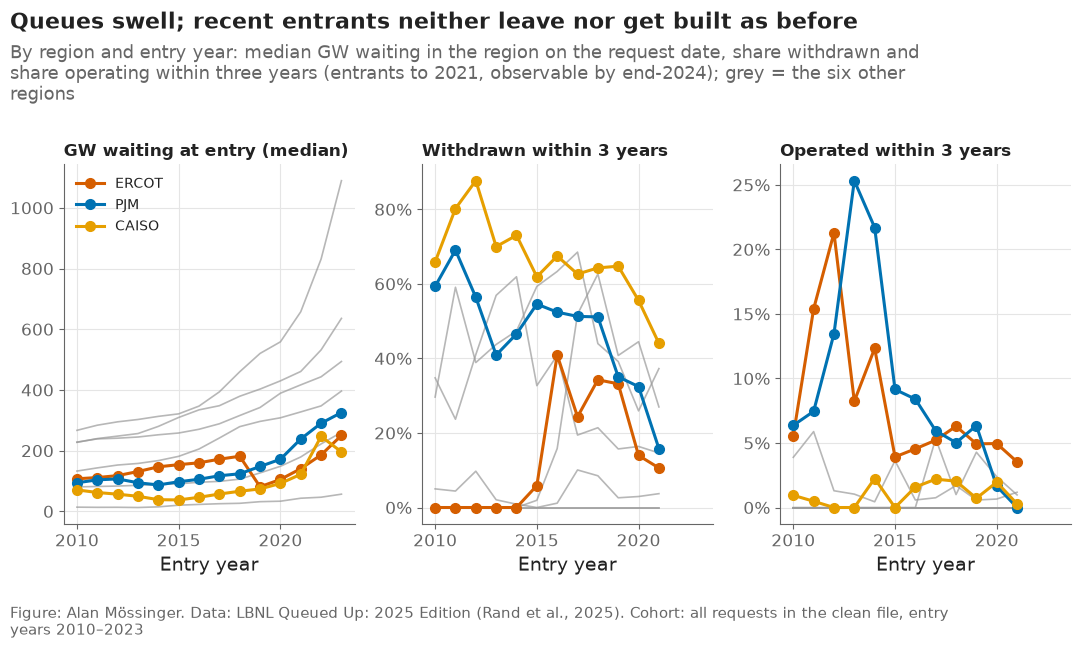

In [20]:
fig, axes = plt.subplots(1, 3, sharex=True)
for ax, (column, label) in zip(axes, [("gw_waiting_at_entry", "GW waiting at entry (median)"),
                                      ("withdrawn_within_3", "Withdrawn within 3 years"),
                                      ("operated_within_3", "Operated within 3 years")]):
    for region in ["MISO", "SPP", "West", "Southeast", "NYISO", "ISO-NE"]:
        part = cm[(cm["region"] == region) & (cm["observable"] | (column == "gw_waiting_at_entry"))]
        ax.plot(part["q_year"], part[column], color=config.OTHER_REGION_COLOR, linewidth=1.2, alpha=0.7)
    for region in TRACK_A:
        part = cm[(cm["region"] == region) & (cm["observable"] | (column == "gw_waiting_at_entry"))]
        ax.plot(part["q_year"], part[column], color=plots.region_color(region), marker="o", label=region)
    ax.set_title(label, fontsize=12)
    ax.set_xlabel("Entry year")
    if column != "gw_waiting_at_entry":
        ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].legend(fontsize=10, loc="upper left")
g = cm[cm["region"].isin(TRACK_A)].pivot(index="q_year", columns="region", values="gw_waiting_at_entry")
w = cm[cm["region"].isin(TRACK_A) & cm["observable"]].pivot(index="q_year", columns="region", values="withdrawn_within_3")
plots.finish(fig,
             f"The queue a PJM entrant joined held {g.loc[2012, 'PJM']:.0f} GW in 2012 and {g.loc[2021, 'PJM']:.0f} GW in 2021; "
             f"its chance of withdrawing within three years went from {w.loc[2012, 'PJM']:.0%} to {w.loc[2021, 'PJM']:.0%}",
             "By region and entry year: median GW waiting in the region on the request date, share withdrawn and share operating "
             "within three years (entrants to 2021, observable by end-2024); grey = the six other regions",
             "all requests in the clean file, entry years 2010–2023")
plots.save_fig(fig, "F16_constraint_map",
               "Congestion at entry and three-year exits by region and entry year: the constraint map.", NOTEBOOK)
plt.show()

**Reading this.** The map shows the constraint the models could not see past. The queue a PJM entrant joined held a median 107 GW in 2012 and 238 GW in 2021; CAISO's went from 57 to 122 GW, ERCOT's from 118 to 141 GW, and the six other regions (grey) climbed past 600 GW by 2023. At the same time the share withdrawn within three years *fell* — in PJM from 56% (2012 entrants) to 16% (2021 entrants) — while the share operating within three years fell too (PJM 13.5% to 0%): entrants neither leave nor get built, they wait. ERCOT's zero withdrawals before 2015 are the stamped-date problem, not a fact. The median time to an executed agreement, where it is dated, runs by entry cohort from 1.7 to 2.0 years in ERCOT, 2.3 to 3.3 in PJM and 2.6 to 3.7 in CAISO in the cohorts shown. For a book this is the picture of a pipeline where the early years have become a holding pattern.

## 2. Scenarios for what the data cannot see

Every test request predates FERC Order No. 2023; the cluster processes, PJM's reformed cycle and the expedited lanes of MISO and SPP are not in the hazards. Nor is the gas-turbine backlog. They enter as named scenarios: multipliers on the yearly hazard of operation (or a delay) with low / base / high settings that are *assumptions*, applied to the 25-request sample book of notebook 16 through its level-repaired incidence curve. The table says what each scenario would do to the book's expected MW online within five years; it does not say which scenario will happen.

In [21]:
sim = load("book_simulation.csv")
expected = sim.set_index("years_after_entry")["expected_mw"]
# the book's yearly incidence increments, scaled: a multiplier m on the operation hazard scales early increments by ≈ m
increments = expected.diff().fillna(expected.iloc[0])
scenarios = pd.DataFrame([
    {"scenario": "as modelled (pre-reform hazards, level repaired)", "setting": "—", "operation_hazard_multiplier": 1.0, "delay_years": 0},
    {"scenario": "cluster reform speeds studies (Order No. 2023)", "setting": "low / base / high", "operation_hazard_multiplier": "0.9 / 1.1 / 1.3", "delay_years": 0},
    {"scenario": "reform raises withdrawals first (deposits, readiness)", "setting": "base", "operation_hazard_multiplier": 0.8, "delay_years": 0},
    {"scenario": "gas-turbine backlog (gas requests only)", "setting": "base", "operation_hazard_multiplier": 1.0, "delay_years": 2},
    {"scenario": "post-2020 level persists (notebook 12's 2020–2022 gap)", "setting": "base", "operation_hazard_multiplier": 0.3, "delay_years": 0},
])
rows = []
cards = load("scorecards.csv")
gas_share = cards.loc[cards["technology"] == "Gas", "expected_mw_online_5yr"].sum() / cards["expected_mw_online_5yr"].sum()
for _, s in scenarios.iterrows():
    mults = [float(m) for m in str(s["operation_hazard_multiplier"]).split(" / ")]
    for m in mults:
        inc = increments.copy()
        if s["delay_years"] > 0:  # gas MW shift later by the delay; the rest unchanged
            shifted = inc * gas_share
            inc = inc * (1 - gas_share) + shifted.shift(int(s["delay_years"])).fillna(0.0)
        inc = inc * m
        rows.append({"scenario": s["scenario"], "multiplier": m, "delay_years": s["delay_years"],
                     "expected_mw_online_5yr": float(inc.cumsum().loc[5]), "expected_mw_online_10yr": float(min(inc.cumsum().loc[10], cards["mw"].sum()))})
scen = pd.DataFrame(rows)
scen["change_vs_modelled_5yr"] = scen["expected_mw_online_5yr"] / scen.loc[0, "expected_mw_online_5yr"] - 1
scen.to_csv(R / "scenarios.csv", index=False)
print(f"sample book: {cards['mw'].sum():,.0f} MW, gas share of expected MW online {gas_share:.0%}")
scen.round(3)

sample book: 6,638 MW, gas share of expected MW online 0%


,scenario,multiplier,delay_years,expected_mw_online_5yr,expected_mw_online_10yr,change_vs_modelled_5yr
0,"as modelled (pre-reform hazards, level repaired)",1.0,0,202.640,555.307,0.0
1,cluster reform speeds studies (Order No. 2023),0.9,0,182.376,499.776,-0.1
2,cluster reform speeds studies (Order No. 2023),1.1,0,222.904,610.838,0.1
3,cluster reform speeds studies (Order No. 2023),1.3,0,263.432,721.899,0.3
4,"reform raises withdrawals first (deposits, readiness)",0.8,0,162.112,444.246,-0.2
5,gas-turbine backlog (gas requests only),1.0,2,202.640,555.307,0.0
6,post-2020 level persists (notebook 12's 2020–2022 gap),0.3,0,60.792,166.592,-0.7


**Reading this.** The scenarios bracket what the data cannot say. If cluster reform speeds studies by 10–30% the sample book's expected MW online within five years moves from 203 to 222–263; if reform's deposits and readiness rules raise early withdrawals instead, to 162. The gas-turbine backlog does nothing to this book because it holds no gas (the scenario is kept for books that do). The scenario that dominates all others is the one notebook 12 measured rather than assumed: if the post-2020 level persists, the book's expected MW online within five years falls to 61, 70% below the modelled figure. The order of the scenarios is the message — the drift already observed is a larger risk than any reform scenario, in either direction.

## 3. Levers by actor

Each lever with its evidence: a number from a results file of this project, or "outside the data". The direction is what the data show; whether pulling the lever *causes* the change is not something an observational queue file can establish, and the table says so where it matters.

In [22]:
pd_ = load("partial_dependence.csv")
size_pd = pd_[pd_["feature"] == "size_mw"]
ercot_small = size_pd[(size_pd["region"] == "ERCOT") & (size_pd["value"] <= 3.5)]["p"].max()
ercot_large = size_pd[(size_pd["region"] == "ERCOT") & (size_pd["value"] >= 900)]["p"].min()
wi = load("whatifs.csv")
sig = load("landmark_agreement_signal.csv")
sig_e = sig[(sig["region"] == "ERCOT")].set_index("agreement known")["observed_3yr"]
cm_pjm = cm[cm["region"] == "PJM"].set_index("q_year")
vt = load("value_table.csv")
v24 = vt[(vt["year"] == 2024)].pivot(index="tech", columns="region", values="base")
drift_r = load("drift_by_cohort_region.csv")
d5 = drift_r[drift_r["horizon"] == 5].pivot(index="entry_year", columns="region", values="observed")
levers = pd.DataFrame([
    {"actor": "developer", "lever": "size the request under the 20 MW step, or split it",
     "evidence": f"P(operation within 5 years) falls with size in every model and in the data: ERCOT partial dependence {ercot_small:.1%} near 3 MW against {ercot_large:.1%} near 1,000 MW (notebook 09); the what-if cut to 19.9 MW changes the sample book's requests by {100 * wi['cut to 19.9 MW (if ≥ 20 MW)'].mean():+.1f} points on average (notebook 16)",
     "direction": "smaller = likelier, sooner", "causal?": "no — a smaller request is a different project", "source": "partial_dependence.csv; whatifs.csv"},
    {"actor": "developer", "lever": "hybridise solar with storage",
     "evidence": f"what-if Solar → Solar+Battery: {100 * wi['add storage (if solar)'].mean():+.1f} points on average on the sample book (notebook 16); the sanity check of notebook 09 found hybrids lag solar in the data, which the model does not recover",
     "direction": "unclear", "causal?": "no", "source": "whatifs.csv; sanity_checks.csv"},
    {"actor": "developer", "lever": "enter when the queue is quieter",
     "evidence": f"what-if 25% less GW waiting: {100 * wi['enter a 25% quieter queue'].mean():+.1f} points on average (notebook 16); five-year completion by congestion bin falls in PJM and CAISO (notebook 03, five_year_by_congestion.csv); but the yearly-congestion artefact (notebook 09) makes the model's own congestion effect unreliable",
     "direction": "quieter = likelier, in the raw data", "causal?": "no — crowding and cohort go together", "source": "whatifs.csv; five_year_by_congestion.csv"},
    {"actor": "developer / lender", "lever": "treat the executed agreement as the gate",
     "evidence": f"ERCOT requests two years in: {sig_e[True]:.0%} of those with an executed agreement operated within three more years against {sig_e[False]:.0%} without (notebook 14); the landmark model's Uno's C 0.797 against 0.687 at +2 years",
     "direction": "agreement = the strongest known signal", "causal?": "partly — the agreement is a milestone, not a cause", "source": "landmark_agreement_signal.csv; landmark_metrics.csv"},
    {"actor": "developer", "lever": "choose the region and technology mix by value, not only by probability",
     "evidence": f"a MW online in 2024 is worth about ${v24.loc['Gas', 'PJM'] / 1e3:,.0f}k a year for gas in PJM, ${v24.loc['Solar', 'PJM'] / 1e3:,.0f}k for solar in PJM and ${v24.loc['Solar', 'CAISO'] / 1e3:,.0f}k for solar in CAISO (base case, notebook 15)",
     "direction": "value per MW differs more across technologies than P(operation) does", "causal?": "n/a", "source": "value_table.csv"},
    {"actor": "ISO", "lever": "shorten the early years: the operation hazard in years 1–3 fell from 9.1% (2013 entrants) to 2.3% (2018–2019)",
     "evidence": "notebook 12, drift_hazards_by_cohort.csv; the withdrawal hazard fell less — requests wait longer rather than leave",
     "direction": "the process slowed, not the applicants", "causal?": "descriptive", "source": "drift_hazards_by_cohort.csv"},
    {"actor": "ISO", "lever": "date the milestones in the public file",
     "evidence": "PJM dates 2.6% of its agreements in the public LBNL file (notebook 13); the landmark model is the entry model for 59% of the cohort as a result",
     "direction": "data lever", "causal?": "n/a", "source": "milestone_coverage.csv"},
    {"actor": "policy", "lever": "credit deadlines move value by COD year",
     "evidence": "IRS Notice 2025-42: wind and solar not under construction by 2026-07-04 must be in service by end-2027 to keep the credit; the base value case removes the credit after 2027 (notebook 15)",
     "direction": "a cliff in the value of late projects", "causal?": "rule", "source": "value_assumptions.csv"},
    {"actor": "policy / ISO", "lever": "cluster reform, expedited lanes",
     "evidence": "not observable: every test request predates Order No. 2023; handled as scenarios (section 2)", "direction": "unknown", "causal?": "n/a", "source": "scenarios.csv"},
    {"actor": "developer", "lever": "siting and permitting risk",
     "evidence": "outside the data: county ordinances (source S12 of the plan) were not joined; next step", "direction": "unknown", "causal?": "n/a", "source": "—"},
])
levers.to_csv(R / "levers.csv", index=False)
levers[["actor", "lever", "direction", "causal?"]]

,actor,lever,direction,causal?
0,developer,"size the request under the 20 MW step, or split it","smaller = likelier, sooner",no — a smaller request is a different project
1,developer,hybridise solar with storage,unclear,no
2,developer,enter when the queue is quieter,"quieter = likelier, in the raw data",no — crowding and cohort go together
3,developer / lender,treat the executed agreement as the gate,agreement = the strongest known signal,"partly — the agreement is a milestone, not a cause"
4,developer,"choose the region and technology mix by value, not only by probability",value per MW differs more across technologies than P(operation) does,n/a
5,ISO,shorten the early years: the operation hazard in years 1–3 fell from 9.1% (2013 entrants) to 2.3% (2018–2019),"the process slowed, not the applicants",descriptive
6,ISO,date the milestones in the public file,data lever,n/a
7,policy,credit deadlines move value by COD year,a cliff in the value of late projects,rule
8,policy / ISO,"cluster reform, expedited lanes",unknown,n/a
9,developer,siting and permitting risk,unknown,n/a


**Reading this.** Six of the ten levers carry a number from this project's results and four are explicitly outside the data. The size lever is the best measured and the least causal: a smaller request is likelier and sooner in every model and in the raw data (ERCOT 41.8% near 3 MW against 7.4% near 1,000 MW; the what-if cut to 19.9 MW adds 3.0 points on average in the sample book), but a developer who splits a request has a different project, not the same one with better odds. The agreement is the strongest signal a developer or lender can wait for (ERCOT: 55.7% against 4.9% three-year completion two years in). The congestion lever points the wrong way in the model (−0.7 points for a quieter queue) because of the artefact, and the raw data's direction is confounded with the cohort. The value lever is large and under-used: value per MW-year differs between gas and solar in PJM by a factor of four, more than any probability difference. The two ISO levers are descriptive — the early-year operation hazard fell by three quarters since 2013 — and the policy and siting levers are scenarios and next steps.

## 4. Region playbooks

One row per region, built from the results files: the base rates (notebook 03), the level drift (notebook 12), what the model adds at entry on the primary cohort (notebook 11) and at milestones (notebook 14), the value per MW online (notebook 15), the budget share the model's book gives the region (notebook 16), and the main uncertainty. Rendered to `report/playbooks.md` for the report.

In [23]:
cif = load("cif_horizons.csv")
cif5 = cif[(cif["grouping"] == "region") & (cif["time"] == 5.0)].set_index("group")
wins = load("metrics_v2_by_size.csv")
choice = load("book_choice.csv").set_index("chooser")
mbr = load("metrics_by_region.csv")
auc5 = mbr[(mbr["metric"] == "uno_c") & (mbr["horizon"] == 5)].pivot(index="region", columns="model", values="estimate")
agreement = load("milestone_coverage.csv").set_index("region")
rows = []
for region in TRACK_A:
    obs = d5[region]
    rows.append({
        "region": region,
        "base 5-year completion (all entrants)": f"{cif5.loc[region, 'cif_operation']:.1%} [{cif5.loc[region, 'cif_operation_low']:.1%}, {cif5.loc[region, 'cif_operation_high']:.1%}]",
        "5-year completion by test entry year": ", ".join(f"{int(y)}: {v:.1%}" for y, v in obs.items()),
        "entry-time Uno's C at 5 years, model vs v1 baseline": f"{auc5.loc[region, 'dt_lgbm']:.2f} vs {auc5.loc[region, 'baseline']:.2f}",
        "agreement dated inside the queue time": f"{agreement.loc[region, 'agreement_inside_queue']:.0%} of requests",
        "value per MW online, 2024 base (solar / wind / gas, $k per year)": f"{v24.loc['Solar', region] / 1e3:,.0f} / {v24.loc['Wind', region] / 1e3:,.0f} / {v24.loc['Gas', region] / 1e3:,.0f}",
        "share of the model's book budget": f"{choice.loc['v2 model, level repaired', f'share_{region}']:.0%}",
        "main uncertainty": {"PJM": "no dated agreements in the public file; capacity price swung from $16 to $108/kW-year",
                             "ERCOT": "withdrawal dates stamped (2025 file) or missing (2026 file); energy price after 2019 assumed",
                             "CAISO": "few operations (low base rate); capacity price assumed; 2017 cohort ran high"}[region],
    })
playbooks = pd.DataFrame(rows)
playbooks.to_csv(R / "playbooks.csv", index=False)
lines = ["# Region playbooks", "", "Built by `notebooks/09_portfolio.ipynb` from the results files; every number traces to one.", ""]
for _, r in playbooks.iterrows():
    lines += [f"## {r['region']}", ""] + [f"- **{k}:** {v}" for k, v in r.items() if k != "region"] + [""]
(paths.REPORT / "playbooks.md").write_text("\n".join(lines), encoding="utf-8")
playbooks.T

,0,1,2
region,ERCOT,PJM,CAISO
base 5-year completion (all entrants),"18.4% [16.5%, 20.4%]","13.2% [12.3%, 14.0%]","4.8% [3.8%, 5.8%]"
5-year completion by test entry year,"2017: 22.6%, 2018: 14.7%, 2019: 14.9%","2017: 11.3%, 2018: 7.4%, 2019: 9.6%","2017: 5.7%, 2018: 3.1%, 2019: 1.4%"
"entry-time Uno's C at 5 years, model vs v1 baseline",0.60 vs 0.58,0.78 vs 0.69,0.71 vs 0.70
agreement dated inside the queue time,30% of requests,3% of requests,15% of requests
"value per MW online, 2024 base (solar / wind / gas, $k per year)",70 / 162 / 133,62 / 135 / 249,120 / 175 / 149
share of the model's book budget,35%,50%,15%
main uncertainty,withdrawal dates stamped (2025 file) or missing (2026 file); energy price after 2019 assumed,no dated agreements in the public file; capacity price swung from $16 to $108/kW-year,few operations (low base rate); capacity price assumed; 2017 cohort ran high


**Reading this.** One page per region. ERCOT: the highest base rate (18.4% within five years), the most dated agreements (30%), the smallest entry-time model gain (Uno's C 0.60 against 0.58), and the largest uncertainties in its own data (withdrawal dates stamped or missing); the model's book gives it 35% of the budget. PJM: the largest region, the biggest entry-time gain (0.78 against 0.69), a fall from 11.3% to 7.4–9.6% five-year completion across the test cohorts, almost no dated agreements (3%) and a capacity price that swung from $16 to $108 per kW-year; 50% of the budget, the cap. CAISO: a 4.8% base rate, 15% dated agreements, an assumed capacity price, and the 2017 cohort that ran high; 15% of the budget. The playbook rows are in `report/playbooks.md` with every number traced.

## 5. Checks

In [24]:
checks = pd.DataFrame([
    {"check": "every lever cites a results file or says it is outside the data",
     "value": int((levers["source"].str.contains(".csv") | levers["evidence"].str.contains("outside the data|not observable")).sum()),
     "pass": bool((levers["source"].str.contains(".csv") | levers["evidence"].str.contains("outside the data|not observable")).all())},
    {"check": "constraint map covers the nine regions", "value": cm["region"].nunique(), "pass": cm["region"].nunique() == 9},
    {"check": "playbooks written for the three ISOs", "value": len(playbooks), "pass": len(playbooks) == 3 and (paths.REPORT / "playbooks.md").exists()},
    {"check": "F16 saved as PNG and SVG", "value": 2,
     "pass": (paths.FIGURES / "F16_constraint_map.png").exists() and (paths.FIGURES / "F16_constraint_map.svg").exists()},
])
checks.to_csv(R / "levers_checks.csv", index=False)
assert checks["pass"].all(), checks
checks

,check,value,pass
0,every lever cites a results file or says it is outside the data,10,True
1,constraint map covers the nine regions,9,True
2,playbooks written for the three ISOs,3,True
3,F16 saved as PNG and SVG,2,True


## Takeaways — Part B

- The constraint map: the queue a PJM entrant joins held 107 GW in 2012 and 238 GW in 2021, and the share that leaves or is built within three years fell together — entrants wait.
- Scenarios bracket the unobservable reforms at −20% to +30% of the sample book's five-year MW; the observed post-2020 level, if it persists, is −70%.
- Ten levers, six with a number from this project, four outside the data; the agreement milestone is the strongest, the size lever the least causal, the value lever the most under-used.
- Region playbooks for ERCOT, PJM and CAISO in `report/playbooks.md`, every number traced to a results file.
- **What goes to the report:** F16; the scenario table; the levers table; the three playbooks.

# Part C — The milestone-managed book: does a model beat a careful analyst's lookup two years in? (was notebook 20)

Notebook 14 showed that, two years after the request, the landmark model ranks the requests still in the queue far better than the entry model and the plain lookup (criterion C8). This notebook asks the question a portfolio manager would ask next, as a registered test: if I keep 25 or 50 of the utility-scale requests still in the queue at that point, does the model's choice realise more operations and MW than the choice of a lookup that knows the same dated agreement status — and can the model's level be repaired at the landmark with outcomes already known that day?

## Setup

In [25]:
import hashlib
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, drift, evaluation, landmark, paths, plots, portfolio, variants

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "09_portfolio"
START = time.time()


def save(fig, name, caption):
    """Save a figure of this notebook under figures/09_portfolio/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

## 1. Registration (decision #58)

This cell is the registration. It was run and committed on its own before any later cell existed, so every rule below — the pool, the landmark, the book sizes, the cap, the choosers, the outcome, the resampling and the thesis rule — was fixed before a book was chosen or a number scored. On every later run the cell checks that the file on disk is the registered one and stops if anything differs.

Why these rules. The pool is notebook 14's +2 risk set restricted to 20 MW and more, the cohort of C6–C12. The landmark model's view is the one notebook 14 already published as best two years in ("agreement updated": the dated agreement flag, congestion frozen at entry because updating it is the known artefact). The decisive comparator is a lookup that **also knows whether the agreement has been executed**: beating the plain lookup would only repeat C8, since the model wins there on information a careful analyst also has. The count-limited book is the frame notebook 16's registered backtest lacked: ranking is all that decides it.

In [26]:
REGISTRATION = {
    "decided": "2026-10-08",
    "decision": 58,
    "n_boot": 200,
    "level": 0.95,
    "seed": 2058,
    "pool": "Track A test entrants 2017–2019 of 20 MW and more (variants.at_least_20) in the queue two full years after the request (landmark.risk_set(test, 2))",
    "landmark_years": 2,
    "horizon_after_landmark": 3,
    "book_sizes": [25, 50],
    "region_cap_share": 0.5,
    "tie_break": "a uniform random number per request, drawn once per resample and shared by every chooser; lower first",
    "outcome": "operation within 3 years of the landmark (event == 1 and duration − 2 ≤ 3), all observed by 2024-12-31; MW of those requests",
    "choosers": {
        "M": "landmark model: notebook 14's 'agreement updated' view (LightGBM hazards with the dated agreement flag, congestion at entry), refitted on entrants to 2016",
        "LA": "agreement-aware lookup: region × technology × size-band Aalen–Johansen cells from the landmark on, fitted separately on training requests with and without an agreement known at the landmark (landmark.agreement_lookup_at_landmark)",
        "E": "no re-scoring: the fair baseline's P(operation by 5 years) at entry (notebook 11)",
    },
    "reported_not_registered": ["L0: the plain lookup at the landmark (C8 already compares it)", "random: a random book under the same cap"],
    "level_repair": "for entry cohort c, one intercept (slope fixed at 1, drift.fit_intercept) fitted on cohort c's operations within 1 year and cohort c − 1's within 2 years, against the landmark model's entry view (landmark k = 0) of the same requests, all sizes and regions pooled; applied to M's +2 predictions of cohort c. Every outcome used ends before 1 January of c + 2, before any landmark of cohort c",
    "thesis_rule": "the stronger thesis (a model-managed book beats a careful analyst's lookup at the milestone) is supported only if both C15 lines against LA pass; otherwise the report keeps the current thesis",
}
lines = []
for metric, cid in [("operations", "C15"), ("MW", "C16")]:
    for bench in ["LA", "E"]:
        for n in REGISTRATION["book_sizes"]:
            lines.append({"id": cid, "line": f"+2 landmark, ≥ 20 MW, book of {n}: {metric} realised within 3 years, M vs {bench}",
                          "metric": metric, "n": n, "model": "M", "benchmark": bench,
                          "rule": "paired 95% interval of M − benchmark entirely above 0"})
for cohort in ["all sizes", "≥ 20 MW"]:
    lines.append({"id": "C17", "line": f"+2 landmark, {cohort}: M after the level repair, calibration intercept at 3 years",
                  "metric": "intercept", "n": None, "model": "M repaired", "benchmark": "",
                  "rule": "95% interval covers 0"})
REGISTRATION["criteria"] = lines
criteria = pd.DataFrame(lines)

reg_path = paths.RESULTS / "success_criteria_v4_registered.json"
text = json.dumps(REGISTRATION, indent=2, ensure_ascii=False)
if reg_path.exists():
    assert reg_path.read_text(encoding="utf-8") == text, "the registration differs from the committed file — a registered rule was changed"
else:
    reg_path.write_text(text, encoding="utf-8")
criteria.to_csv(paths.RESULTS / "success_criteria_v4.csv", index=False)
REGISTERED_SHA = hashlib.sha256(reg_path.read_bytes()).hexdigest()
print(f"{len(criteria)} registered lines; registration file SHA-256 {REGISTERED_SHA[:16]}…")
criteria[["id", "line", "rule"]]

10 registered lines; registration file SHA-256 0ea97d5aac9f208c…


,id,line,rule
0,C15,"+2 landmark, ≥ 20 MW, book of 25: operations realised within 3 years, M vs LA",paired 95% interval of M − benchmark entirely above 0
1,C15,"+2 landmark, ≥ 20 MW, book of 50: operations realised within 3 years, M vs LA",paired 95% interval of M − benchmark entirely above 0
2,C15,"+2 landmark, ≥ 20 MW, book of 25: operations realised within 3 years, M vs E",paired 95% interval of M − benchmark entirely above 0
3,C15,"+2 landmark, ≥ 20 MW, book of 50: operations realised within 3 years, M vs E",paired 95% interval of M − benchmark entirely above 0
4,C16,"+2 landmark, ≥ 20 MW, book of 25: MW realised within 3 years, M vs LA",paired 95% interval of M − benchmark entirely above 0
5,C16,"+2 landmark, ≥ 20 MW, book of 50: MW realised within 3 years, M vs LA",paired 95% interval of M − benchmark entirely above 0
6,C16,"+2 landmark, ≥ 20 MW, book of 25: MW realised within 3 years, M vs E",paired 95% interval of M − benchmark entirely above 0
7,C16,"+2 landmark, ≥ 20 MW, book of 50: MW realised within 3 years, M vs E",paired 95% interval of M − benchmark entirely above 0
8,C17,"+2 landmark, all sizes: M after the level repair, calibration intercept at 3 years",95% interval covers 0
9,C17,"+2 landmark, ≥ 20 MW: M after the level repair, calibration intercept at 3 years",95% interval covers 0


## 2. Data and the landmark model

The same data and the same fit as notebook 14: the discrete-time LightGBM with the dated agreement flag (`ia_before`), fitted on entrants to 2016 with notebook 06's settings. The fit is repeated here rather than read from disk because the level repair of section 6 needs the model's entry view of the 2016 cohort, which notebook 14 did not store; section 8 checks that the refit reproduces notebook 14's predictions exactly.

In [27]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
milestones = pd.read_parquet(paths.DATA_INTERIM / "milestones.parquet").set_index("project_key")
ia_by_key = milestones["ia_date_best"].where(milestones["ia_inside_queue"])
ia_dates = pd.Series(track_a["project_key"].astype(str).map(ia_by_key).to_numpy(), index=track_a.index)

final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
test["large"] = variants.at_least_20(test)
K, H = REGISTRATION["landmark_years"], REGISTRATION["horizon_after_landmark"]
H_AFTER = [1, 2, 3]
N_BOOT, LEVEL, SEED = REGISTRATION["n_boot"], REGISTRATION["level"], REGISTRATION["seed"]
fit_landmark = discrete_time.fit_both(final, clean, tuning, extra=landmark.ia_extra(final, ia_dates))
print(f"fit done ({(time.time() - START) / 60:.1f} min)")

fit done (0.0 min)


## 3. The pool and the four rankings

The pool is every test request of 20 MW and more still in the queue two full years after its request. Each chooser scores it by P(operation within 3 years of the landmark), except E, which keeps the entry ranking (the fair baseline's P(operation by 5 years) on the request date) — the manager who formed the book at entry and does not re-score. The outcome — operation within three years of the landmark, five years after the request — is observed for every request: the last 2019 entrant reaches it on 2024-12-30.

In [28]:
risk = test[landmark.risk_set(test, K)].copy()
pool = risk[risk["large"]].copy()
pred_m_risk = landmark.predict_at_landmark(fit_landmark, risk, clean, K, H_AFTER, ia_dates, update_congestion=False, update_ia=True)
la = landmark.agreement_lookup_at_landmark(final, pool, K, H_AFTER, ia_dates)
l0 = landmark.fair_baseline_at_landmark(final, pool, K, H_AFTER)
entry_fair = (pd.read_parquet(paths.DATA_PROCESSED / "predictions_v2.parquet").query("horizon == 5")
              .assign(project_key=lambda f: f["project_key"].astype(str)).set_index("project_key")["fair_baseline"])
SCORES = {"M": pred_m_risk.loc[pool.index, H].to_numpy(float), "LA": la[H].to_numpy(float), "L0": l0[H].to_numpy(float),
          "E": entry_fair.reindex(pool["project_key"].astype(str)).to_numpy(float)}
assert all(np.isfinite(s).all() for s in SCORES.values()), "every chooser must score every request of the pool"

years_after = pool["duration_years"].to_numpy() - K
built = (pool["event"].to_numpy() == 1) & (years_after <= H)
mw = pool["mw"].to_numpy(float)
region = pool["region"].astype(str).to_numpy()
known = landmark.agreement_known_at(pool, K, ia_dates).to_numpy()
follow_up = ((pd.Timestamp(config.CENSOR_DATE) - pool["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy() - K
assert (follow_up >= H - 0.01).all(), "every request of the pool must be followed for 3 years after the landmark"

pool_table = (pd.DataFrame({"region": region, "known": known, "built": built, "mw": mw, "built_mw": np.where(built, mw, 0.0)})
              .groupby("region").agg(requests=("built", "size"), agreement_known=("known", "sum"), operated_within_3=("built", "sum"),
                                     mw=("mw", "sum"), operated_mw=("built_mw", "sum")).reindex(config.TRACK_A_REGIONS))
pool_table.loc["all"] = pool_table.sum()
pool_table["operated_share"] = pool_table["operated_within_3"] / pool_table["requests"]
by_known = pd.DataFrame({"known": known, "built": built}).groupby("known")["built"].agg(["size", "sum", "mean"])
pool_table.to_csv(paths.RESULTS / "managed_book_pool.csv")
la_cells = la.groupby(["agreement_known", "cell"]).size()
print(f"pool: {len(pool):,} requests, {int(built.sum())} operated within 3 years of the landmark; agreement known for {int(known.sum())}")
print("operated within 3 years, by agreement known at the landmark:", by_known.round(3).to_dict("index"))
print("agreement-aware lookup cells used:", la_cells.to_dict())
pool_table.round(3)

pool: 1,132 requests, 119 operated within 3 years of the landmark; agreement known for 118
operated within 3 years, by agreement known at the landmark: {False: {'size': 1014, 'sum': 52, 'mean': 0.051}, True: {'size': 118, 'sum': 67, 'mean': 0.568}}
agreement-aware lookup cells used: {(False, 'region'): 336, (False, 'region × technology'): 307, (False, 'region × technology × size'): 371, (True, 'region'): 118}


,requests,agreement_known,operated_within_3,mw,operated_mw,operated_share
region,,,,,,
ERCOT,347.0,111.0,75.0,70607.140,13394.52,0.216
PJM,665.0,0.0,37.0,82384.300,2247.20,0.056
CAISO,120.0,7.0,7.0,48204.251,1292.00,0.058
all,1132.0,118.0,119.0,201195.691,16933.72,0.105


**Reading this.** The pool is 1,132 utility-scale requests still in the queue two years after the request; 119 of them (10.5%) operated within the next three years. The dated agreement is the dominant signal and it is lopsided: it is known at the landmark for 118 requests, 111 of them in ERCOT, 7 in CAISO and none in PJM, and 56.8% of those operated against 5.1% of the 1,014 without one. The agreement-aware lookup can split its cells by the flag, but the agreement-known group is too thin in the training data for any region × technology cell to reach 50 requests, so all 118 fall back to their region's curve: the lookup knows *that* an agreement exists, not which agreed requests are likelier to finish. That is the comparison the registration chose, and it is the one a careful analyst with these data would face.

## 4. The books

Each chooser keeps its top 25 and top 50 requests, no region above half the places, ties broken by one random order shared by all choosers (`src/portfolio.top_n_book`). A random book under the same cap is shown for scale. The counts below are the full-pool point estimates; the intervals and the registered comparisons follow in section 5.

In [29]:
NS, CAP = REGISTRATION["book_sizes"], REGISTRATION["region_cap_share"]
CHOOSERS = ["M", "LA", "E", "L0", "random"]
LABELS = {"M": "M — landmark model", "LA": "LA — lookup with agreement status", "E": "E — entry lookup, not re-scored",
          "L0": "L0 — lookup at the landmark", "random": "random book"}


def books_on(idx, rng, keep_masks=False):
    """Each chooser's books of every size on the resample ``idx``: operations and MW realised (and the masks if asked)."""
    tiebreak, random_score = rng.uniform(size=len(idx)), rng.uniform(size=len(idx))
    out, masks = {}, {}
    for name in CHOOSERS:
        score = random_score if name == "random" else SCORES[name][idx]
        for n in NS:
            chosen = portfolio.top_n_book(score, region[idx], n, CAP, tiebreak)
            hit = chosen & built[idx]
            out[f"{name}|{n}|operations"] = int(hit.sum())
            out[f"{name}|{n}|MW"] = float(mw[idx][hit].sum())
            masks[(name, n)] = chosen
    return (out, masks) if keep_masks else out


point, point_masks = books_on(np.arange(len(pool)), np.random.default_rng(SEED), keep_masks=True)
point_table = pd.DataFrame([{"chooser": LABELS[c], "n": n, "operations": point[f"{c}|{n}|operations"], "MW": point[f"{c}|{n}|MW"]}
                            for c in CHOOSERS for n in NS])
point_table.pivot(index="chooser", columns="n", values=["operations", "MW"]).loc[[LABELS[c] for c in CHOOSERS]].round(0)

operations            MW        
n                                         25    50      25      50
chooser                                                           
M — landmark model                      19.0  33.0  1078.0  2357.0
LA — lookup with agreement status       11.0  24.0  1681.0  3271.0
E — entry lookup, not re-scored          8.0  19.0   712.0  1858.0
L0 — lookup at the landmark              7.0  14.0   565.0   949.0
random book                              4.0   7.0  1191.0  1527.0

**Reading this.** On the full pool the model's book of 25 holds 19 requests that operated within three years, the agreement-aware lookup's 11, the entry ranking kept unchanged 8, the plain lookup at the landmark 7 and a random book 4; in books of 50, 33, 24, 19, 14 and 7. In MW the order is different: the lookup's books realised 1,681 MW (25) and 3,271 MW (50) against the model's 1,078 and 2,357, because the lookup's picks include a few large requests that did operate while the model's are smaller. Point estimates only; section 5 says whether the differences survive resampling.

## 5. The registered comparisons (C15, C16)

200 resamples of the pool with replacement; in each, every chooser re-chooses its books on the resample with a fresh shared tie-break, and the paired difference M − benchmark is taken inside the resample. A line passes when the 95% percentile interval of the difference lies entirely above zero.

In [30]:
rng = np.random.default_rng(SEED + 1)
boot = pd.DataFrame([books_on(rng.integers(0, len(pool), len(pool)), rng) for _ in range(N_BOOT)])
boot.to_csv(paths.RESULTS / "managed_book_bootstrap.csv", index=False)
lo_q, hi_q = 100 * (1 - LEVEL) / 2, 100 * (1 + LEVEL) / 2

rows = []
for c in CHOOSERS:
    for n in NS:
        for metric in ["operations", "MW"]:
            col = f"{c}|{n}|{metric}"
            row = {"chooser": c, "label": LABELS[c], "n": n, "metric": metric, "estimate": point[col],
                   "low": np.percentile(boot[col], lo_q), "high": np.percentile(boot[col], hi_q)}
            for ref in ["LA", "E"]:
                d = boot[col] - boot[f"{ref}|{n}|{metric}"]
                row[f"diff_vs_{ref}"] = point[col] - point[f"{ref}|{n}|{metric}"]
                row[f"diff_vs_{ref}_low"], row[f"diff_vs_{ref}_high"] = np.percentile(d, lo_q), np.percentile(d, hi_q)
            rows.append(row)
books = pd.DataFrame(rows)
books.to_csv(paths.RESULTS / "managed_books.csv", index=False)

scored = criteria.copy()
for i, line in scored.iterrows():
    if line["id"] in ("C15", "C16"):
        r = books[(books["chooser"] == "M") & (books["n"] == line["n"]) & (books["metric"] == line["metric"])].iloc[0]
        b = line["benchmark"]
        scored.loc[i, ["estimate", "low", "high"]] = [r[f"diff_vs_{b}"], r[f"diff_vs_{b}_low"], r[f"diff_vs_{b}_high"]]
        scored.loc[i, "pass"] = bool(r[f"diff_vs_{b}_low"] > 0)
scored.loc[scored["id"].isin(["C15", "C16"]), ["id", "line", "estimate", "low", "high", "pass"]].round(1)

,id,line,estimate,low,high,pass
0,C15,"+2 landmark, ≥ 20 MW, book of 25: operations realised within 3 years, M vs LA",8.0,1.0,11.0,True
1,C15,"+2 landmark, ≥ 20 MW, book of 50: operations realised within 3 years, M vs LA",9.0,1.0,13.0,True
2,C15,"+2 landmark, ≥ 20 MW, book of 25: operations realised within 3 years, M vs E",11.0,4.0,13.0,True
3,C15,"+2 landmark, ≥ 20 MW, book of 50: operations realised within 3 years, M vs E",14.0,7.0,19.0,True
4,C16,"+2 landmark, ≥ 20 MW, book of 25: MW realised within 3 years, M vs LA",-603.7,-2196.3,155.3,False
5,C16,"+2 landmark, ≥ 20 MW, book of 50: MW realised within 3 years, M vs LA",-913.8,-3090.4,179.6,False
6,C16,"+2 landmark, ≥ 20 MW, book of 25: MW realised within 3 years, M vs E",365.3,-337.2,846.4,False
7,C16,"+2 landmark, ≥ 20 MW, book of 50: MW realised within 3 years, M vs E",498.4,-871.2,1237.6,False


**Reading this.** All four operation lines pass. Against the agreement-aware lookup the model's book holds 8 more operations in a book of 25 (95% interval [+1, +11]) and 9 more in a book of 50 ([+0.98, +13]) — the second interval clears zero by less than one request, the narrowest pass in the project. Against the unchanged entry ranking the gain is larger: +11 [+4, +13] and +14 [+7, +19]. All four MW lines fail. Against the agreement-aware lookup the model's books realise *fewer* MW (−604 [−2,196, +155] and −914 [−3,090, +180]); against the entry ranking more, but with intervals that include zero (+365 [−337, +846], +498 [−871, +1,238]). By the thesis rule fixed in section 1, the stronger thesis is supported in the form it was registered: two years in, a model-managed book picks more of the utility-scale requests that get built than a lookup that knows the same agreement status. It is not supported in MW, and the report says so.

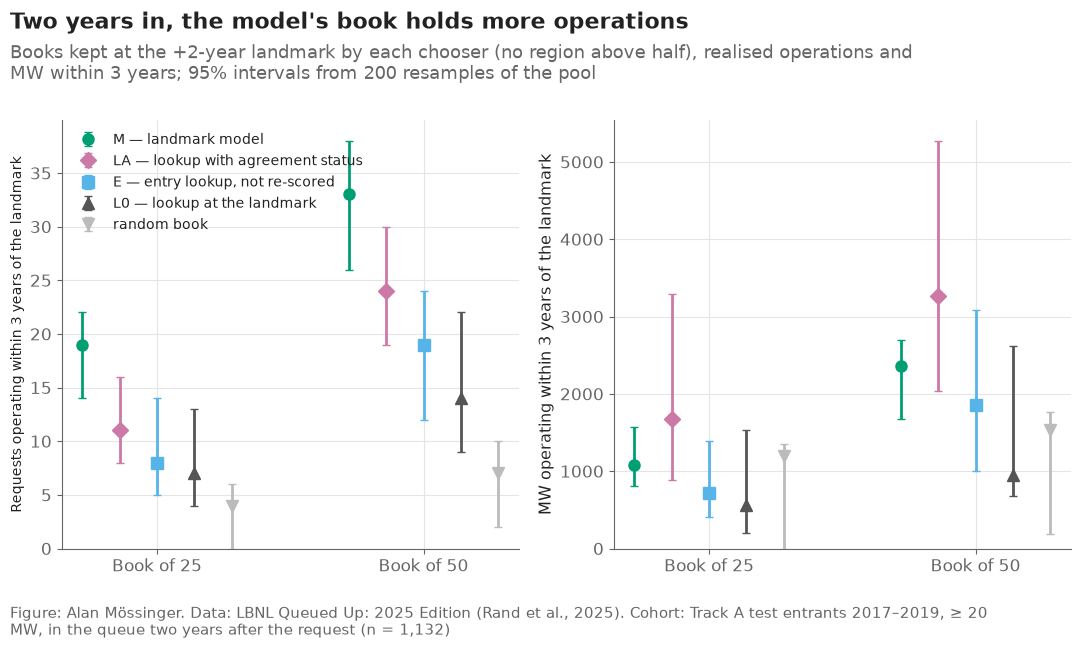

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
style = {"M": ("#009E73", "o"), "LA": ("#CC79A7", "D"), "E": ("#56B4E9", "s"), "L0": ("#555555", "^"), "random": ("#BBBBBB", "v")}
for ax, metric, unit in [(axes[0], "operations", "Requests operating within 3 years of the landmark"),
                         (axes[1], "MW", "MW operating within 3 years of the landmark")]:
    for c_i, c in enumerate(CHOOSERS):
        part = books[(books["chooser"] == c) & (books["metric"] == metric)].set_index("n").loc[NS]
        x = np.arange(len(NS)) + (c_i - 2) * 0.14
        color, marker = style[c]
        ax.errorbar(x, part["estimate"], yerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]], fmt=marker,
                    color=color, markersize=8, capsize=3, linewidth=2, label=LABELS[c])
    ax.set_xticks(range(len(NS)), [f"Book of {n}" for n in NS])
    ax.set_ylabel(unit)
    ax.set_ylim(bottom=0)
axes[0].legend(fontsize=10, loc="upper left")
m25, la25 = point["M|25|operations"], point["LA|25|operations"]
m50, la50 = point["M|50|operations"], point["LA|50|operations"]
c15_la = scored[(scored["id"] == "C15") & (scored["benchmark"] == "LA")]
verb = "beat" if c15_la["pass"].all() else "did not beat"
plots.finish(fig,
             f"Two years in, the model's books {verb} a lookup that knows the agreement status: "
             f"{m25} vs {la25} operations in a book of 25, {m50} vs {la50} in a book of 50 — but not more MW",
             f"Books kept at the +2-year landmark by each chooser (no region above half), realised operations and MW within 3 years; "
             f"95% intervals from {N_BOOT} resamples of the pool",
             f"Track A test entrants 2017–2019, ≥ 20 MW, in the queue two years after the request (n = {len(pool):,})")
plots.save_fig(fig, "F18_managed_book",
               "Operations and MW realised within three years by the books each chooser keeps two years after the request, with bootstrap intervals.",
               NOTEBOOK)
plt.show()

**Reading this.** Figure F18 shows the two results side by side. Left: the model's books (green) sit above every other chooser in requests that operated, with intervals that separate from the entry ranking and, narrowly, from the agreement-aware lookup. Right: in MW the lookup's books (pink) sit highest and widest — a handful of large plants decide MW totals, so MW rewards size as the registered backtest of notebook 16 did, and the model's ranking by probability does not chase size. For a developer counting projects that reach operation, or a lender counting financings that close, the left panel is the decision; for a grid planner counting megawatts, the right panel says the model adds nothing over the lookup. The random book shows the scale: 4 of 25.

## 6. What the books hold

Where the difference between the model's book and the agreement-aware lookup's comes from: how many requests in each book have a dated agreement known at the landmark, how the places split by region, how many requests the two books share, and the operations inside and outside the agreement-known group.

In [32]:
comp = []
for (c, n), chosen in point_masks.items():
    comp.append({"chooser": c, "n": n, "agreement_known": int((chosen & known).sum()),
                 "operated_with_agreement": int((chosen & known & built).sum()),
                 "operated_without_agreement": int((chosen & ~known & built).sum()),
                 **{f"places_{r}": int((chosen & (region == r)).sum()) for r in config.TRACK_A_REGIONS},
                 "shared_with_M": int((chosen & point_masks[("M", n)]).sum())})
composition = pd.DataFrame(comp)
composition.to_csv(paths.RESULTS / "managed_book_composition.csv", index=False)
composition

,chooser,n,agreement_known,operated_with_agreement,operated_without_agreement,places_ERCOT,places_PJM,places_CAISO,shared_with_M
0,M,25,13,13,6,12,12,1,25
1,M,50,25,23,10,25,24,1,50
2,LA,25,13,7,4,6,12,7,6
3,LA,50,25,14,10,18,25,7,28
4,E,25,4,2,6,12,12,1,6
5,E,50,8,6,13,25,25,0,25
6,L0,25,3,3,4,12,12,1,6
7,L0,50,4,3,11,24,25,1,24
8,random,25,4,2,2,10,12,3,0
9,random,50,8,4,3,19,25,6,2


**Reading this.** The difference is *within* the agreement group, not in finding it. Both 25-request books hold 13 requests with a known agreement (the cap stops either from holding more ERCOT); all 13 of the model's operated, 7 of the lookup's. The lookup ranks agreed requests by their region's curve alone and gave 7 places to CAISO; the model ranks them by technology, size, state and timing as well and kept 12 ERCOT, 12 PJM and 1 CAISO. The two books share only 6 of 25 requests (28 of 50). Outside the agreement group the model also does better (6 operations against 4 in 25). This is the evidence that the model's value at the milestone is not just the flag: given the same flag, it orders the requests better — but it does so in ERCOT, where the agreements are dated, and the PJM places in every book carry no agreement information at all.

## 7. The level at the landmark (C17)

Notebook 14 published the landmark model's calibration two years in: an intercept below zero, so the model predicts too much operation, as the drift of notebook 12 would lead one to expect. The registered repair uses only outcomes dated before the landmark: for entry cohort c, one intercept, slope fixed at 1, fitted on cohort c's operations within 1 year and cohort c − 1's within 2 years against the landmark model's entry view of the same requests. Both windows close by 31 December of c + 1, before the first landmark of cohort c. The repaired predictions are scored on the full +2 risk set and on its ≥ 20 MW part, with notebook 14's IPCW scoring and 200 resamples.

In [33]:
early = []
for c in range(config.TEST_YEARS[0] - 1, config.TEST_YEARS[1] + 1):
    part = track_a[track_a["q_year"] == c]
    part = part[landmark.risk_set(part, 0)]
    p = landmark.predict_at_landmark(fit_landmark, part, clean, 0, [1, 2], ia_dates, update_congestion=False, update_ia=True)
    op = (part["event"] == 1).to_numpy()
    early.append(pd.DataFrame({"q_year": c, "p1": p[1].to_numpy(), "p2": p[2].to_numpy(),
                               "y1": op & (part["duration_years"].to_numpy() <= 1), "y2": op & (part["duration_years"].to_numpy() <= 2)}))
early = pd.concat(early, ignore_index=True)
assert early["q_year"].max() + 1 < config.TEST_YEARS[1] + 2  # the newest window used closes before the newest landmark year

repair = []
for c in range(config.TEST_YEARS[0], config.TEST_YEARS[1] + 1):
    own, prev = early[early["q_year"] == c], early[early["q_year"] == c - 1]
    p_fit, y_fit = np.r_[own["p1"], prev["p2"]], np.r_[own["y1"], prev["y2"]].astype(float)
    repair.append({"entry_year": c, "intercept": drift.fit_intercept(p_fit, y_fit),
                   "own_1yr_requests": len(own), "own_1yr_operations": int(own["y1"].sum()), "own_1yr_predicted": own["p1"].sum(),
                   "prev_2yr_requests": len(prev), "prev_2yr_operations": int(prev["y2"].sum()), "prev_2yr_predicted": prev["p2"].sum(),
                   "information_closes": f"{c + 1}-12-31"})
repair = pd.DataFrame(repair)
repair.to_csv(paths.RESULTS / "landmark_level_repair.csv", index=False)
shift = risk["q_year"].map(repair.set_index("entry_year")["intercept"]).to_numpy()
p_raw = pred_m_risk[H].to_numpy(float)
p_rep = drift.apply_intercept(p_raw, shift)

cal_rows = []
for cohort, mask in [("all sizes", np.ones(len(risk), bool)), ("≥ 20 MW", risk["large"].to_numpy())]:
    sub_frame = risk[mask]
    d = sub_frame["duration_years"].to_numpy() - K
    e = sub_frame["event"].to_numpy()
    fu = ((pd.Timestamp(config.CENSOR_DATE) - sub_frame["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy() - K
    G = evaluation.censoring_km(fu, np.ones(len(sub_frame), bool))
    sub = {"M raw": p_raw[mask], "M repaired": p_rep[mask]}
    pt = evaluation.score_horizon(sub, d, e, H, G)
    draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, d, e, H, G, sw), len(sub_frame), N_BOOT,
                                 SEED + 7 + (cohort == "≥ 20 MW"))
    t = evaluation.summarise(pt, draws, reference="M raw", level=LEVEL)
    t.insert(0, "cohort", cohort)
    t["observed"] = float(((e == 1) & (d <= H)).mean())
    t["mean_predicted"] = t["model"].map({"M raw": sub["M raw"].mean(), "M repaired": sub["M repaired"].mean()})
    cal_rows.append(t)
calibration = pd.concat(cal_rows, ignore_index=True)
calibration.to_csv(paths.RESULTS / "landmark_level_calibration.csv", index=False)
for i, line in scored.iterrows():
    if line["id"] == "C17":
        cohort = "all sizes" if "all sizes" in line["line"] else "≥ 20 MW"
        r = calibration[(calibration["cohort"] == cohort) & (calibration["model"] == "M repaired") & (calibration["metric"] == "intercept")].iloc[0]
        scored.loc[i, ["estimate", "low", "high"]] = [r["estimate"], r["low"], r["high"]]
        scored.loc[i, "pass"] = bool(r["low"] <= 0 <= r["high"])
display(repair.round(3))
calibration[calibration["metric"].isin(["intercept", "slope", "uno_c", "brier"])][
    ["cohort", "model", "metric", "estimate", "low", "high", "observed", "mean_predicted"]].round(3)

,entry_year,intercept,own_1yr_requests,own_1yr_operations,own_1yr_predicted,prev_2yr_requests,prev_2yr_operations,prev_2yr_predicted,information_closes
0,2017,0.135,434,8,6.974,507,25,22.520,2018-12-31
1,2018,-0.391,583,2,6.081,434,16,19.331,2019-12-31
2,2019,0.386,1047,30,14.291,583,14,17.042,2020-12-31


,cohort,model,metric,estimate,low,high,observed,mean_predicted
1,all sizes,M raw,brier,0.081,0.073,0.091,0.117,0.145
2,all sizes,M raw,slope,1.211,1.037,1.409,0.117,0.145
3,all sizes,M raw,intercept,-0.295,-0.442,-0.144,0.117,0.145
7,all sizes,M repaired,brier,0.085,0.078,0.094,0.117,0.160
8,all sizes,M repaired,slope,1.093,0.952,1.301,0.117,0.160
9,all sizes,M repaired,intercept,-0.438,-0.591,-0.285,0.117,0.160
12,all sizes,M raw,uno_c,0.797,0.758,0.831,0.117,0.145
14,all sizes,M repaired,uno_c,0.779,0.744,0.816,0.117,0.160
17,≥ 20 MW,M raw,brier,0.070,0.061,0.079,0.105,0.135
18,≥ 20 MW,M raw,slope,1.352,1.162,1.589,0.105,0.135


**Reading this.** The repair failed, and in the wrong direction. The raw landmark model predicts 14.5% operation within three years of the landmark against 11.7% observed (intercept −0.29 [−0.44, −0.14], as notebook 14 published). The early outcomes known at the landmark point the wrong way for the largest cohort: the 2019 entrants had 30 operations within their first year against 14.3 predicted — a burst of early completions — so their intercept moved *up* by +0.39, while their later operation rate was the lowest of the three; 2018's own first year (2 operations against 6.1) moved it down by −0.39, and 2017's moved it up by +0.14. After the repair the intercept is −0.44 [−0.59, −0.28] on all sizes and −0.50 [−0.68, −0.32] on ≥ 20 MW, and Uno's C falls from 0.797 to 0.779 because cohort-specific shifts reorder requests across cohorts. Both C17 lines fail. What it says for a lender: early completions are a poor guide to the level two years later; the level drift of notebook 12 is not visible early enough to repair at the landmark.

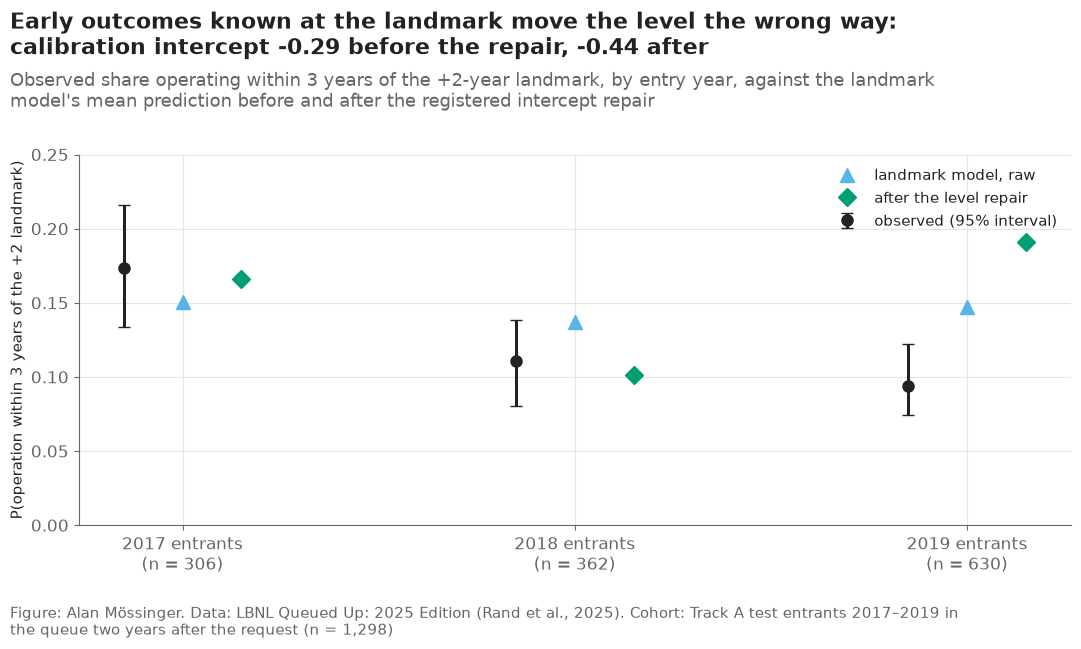

In [34]:
fig, ax = plt.subplots()
years = list(range(config.TEST_YEARS[0], config.TEST_YEARS[1] + 1))
risk_years = risk["q_year"].to_numpy()
d_all, e_all = risk["duration_years"].to_numpy() - K, risk["event"].to_numpy()
obs_all = (e_all == 1) & (d_all <= H)
boot_rng = np.random.default_rng(SEED + 11)
for i, y in enumerate(years):
    m = risk_years == y
    obs = obs_all[m]
    draws = [obs[boot_rng.integers(0, m.sum(), m.sum())].mean() for _ in range(N_BOOT)]
    ax.errorbar(i - 0.15, obs.mean(), yerr=[[obs.mean() - np.percentile(draws, lo_q)], [np.percentile(draws, hi_q) - obs.mean()]],
                fmt="o", color=plots.INK, capsize=4, markersize=8, label="observed (95% interval)" if i == 0 else None)
    ax.plot(i, p_raw[m].mean(), "^", color="#56B4E9", markersize=10, label="landmark model, raw" if i == 0 else None)
    ax.plot(i + 0.15, p_rep[m].mean(), "D", color="#009E73", markersize=9, label="after the level repair" if i == 0 else None)
ax.set_xticks(range(len(years)), [f"{y} entrants\n(n = {(risk_years == y).sum():,})" for y in years])
ax.set_ylabel("P(operation within 3 years of the +2 landmark)")
ax.set_ylim(0, max(0.25, ax.get_ylim()[1]))
ax.legend(fontsize=11)
r_all = calibration[(calibration["cohort"] == "all sizes") & (calibration["metric"] == "intercept")].set_index("model")
plots.finish(fig,
             f"Early outcomes known at the landmark move the level the wrong way: calibration intercept "
             f"{r_all.loc['M raw', 'estimate']:+.2f} before the repair, {r_all.loc['M repaired', 'estimate']:+.2f} after",
             "Observed share operating within 3 years of the +2-year landmark, by entry year, against the landmark model's mean "
             "prediction before and after the registered intercept repair",
             f"Track A test entrants 2017–2019 in the queue two years after the request (n = {len(risk):,})")
save(fig, "20_02_level_at_the_landmark",
     "Observed and predicted three-year operation after the two-year landmark by entry cohort, before and after the level repair.")
plt.show()

**Reading this.** Figure 20_02 makes the failure concrete: in 2017 the repair moves the prediction toward the observed share, in 2018 slightly past it, and in 2019 — the largest cohort, 630 of the 1,298 requests — it moves a prediction already too high (14.7% against 9.4% observed) further up, to 19.1%.

## 8. The registered verdict

The ten lines as registered, with the estimate and interval behind each, and the thesis rule applied as written in section 1.

In [35]:
scored["pass"] = scored["pass"].astype(bool)
scored.to_csv(paths.RESULTS / "success_criteria_v4_scored.csv", index=False)
thesis = bool(scored[(scored["id"] == "C15") & (scored["benchmark"] == "LA")]["pass"].all())
print(f"{int(scored['pass'].sum())} of {len(scored)} registered lines pass")
print("thesis rule:", "SUPPORTED — the model-managed book beats the agreement-aware lookup at +2 years" if thesis
      else "NOT SUPPORTED — the report keeps the current thesis (lookup at entry, model at the milestones against the entry view)")
scored[["id", "line", "estimate", "low", "high", "pass"]].round(3)

4 of 10 registered lines pass
thesis rule: SUPPORTED — the model-managed book beats the agreement-aware lookup at +2 years


,id,line,estimate,low,high,pass
0,C15,"+2 landmark, ≥ 20 MW, book of 25: operations realised within 3 years, M vs LA",8.000,1.000,11.000,True
1,C15,"+2 landmark, ≥ 20 MW, book of 50: operations realised within 3 years, M vs LA",9.000,0.975,13.000,True
2,C15,"+2 landmark, ≥ 20 MW, book of 25: operations realised within 3 years, M vs E",11.000,4.000,13.000,True
3,C15,"+2 landmark, ≥ 20 MW, book of 50: operations realised within 3 years, M vs E",14.000,7.000,19.000,True
4,C16,"+2 landmark, ≥ 20 MW, book of 25: MW realised within 3 years, M vs LA",-603.740,-2196.280,155.267,False
5,C16,"+2 landmark, ≥ 20 MW, book of 50: MW realised within 3 years, M vs LA",-913.810,-3090.407,179.603,False
6,C16,"+2 landmark, ≥ 20 MW, book of 25: MW realised within 3 years, M vs E",365.310,-337.203,846.370,False
7,C16,"+2 landmark, ≥ 20 MW, book of 50: MW realised within 3 years, M vs E",498.450,-871.152,1237.582,False
8,C17,"+2 landmark, all sizes: M after the level repair, calibration intercept at 3 years",-0.438,-0.591,-0.285,False
9,C17,"+2 landmark, ≥ 20 MW: M after the level repair, calibration intercept at 3 years",-0.495,-0.681,-0.319,False


**Reading this.** Four of ten registered lines pass: the four C15 operation lines. The four C16 MW lines and the two C17 level lines fail. The thesis rule written before scoring — both C15 lines against the agreement-aware lookup — is met, so the report can carry the stronger thesis **in the form registered**: at the two-year milestone, among utility-scale requests, a model-managed book of 25 or 50 holds more requests that reach operation than a careful analyst's lookup with the same dated agreement status. The qualifiers are part of the result: it does not hold in MW; the book-of-50 interval clears zero by less than one request; it rests on ERCOT's dated agreements, with none dated in the PJM part of the pool; and the model's level at the landmark is still too high and could not be repaired with what is known that day.

## 10. How much to add per region: the count book with a floor (F24; an extension of C15, not a registration)

C15 established that, two years in, the landmark model's book of 25 or 50 utility-scale requests holds more requests that reach operation than the agreement-aware lookup's. A company then asks how many to add in each region. This section answers with the registered pool, chooser and outcome, unchanged, and one rule: in each region, add requests in the model's order while the model's probability of operation within three years is at least the pool's own observed rate (`p_floor`, 119 of 1,132), then apply the registered cap of no region above half the book. The same curve is drawn for the lookup. It is scored on what happened, with the registered 200 resamples. Expected NPV per added request comes from notebook 15's NPV per MW at the operation date (section 8), merchant and contracted, and the landmark probabilities, discounted to the landmark at the technology's ATB cost of capital. This is an extension of the registered result, written after it; it does not change C15–C17.

In [36]:
npv_tab = pd.read_csv(paths.RESULTS / "npv_table.csv")
NPV_BASE = npv_tab.set_index(["region", "tech", "cod_year"])["npv_per_mw_base"].to_dict()
NPV_CONTRACTED = npv_tab.set_index(["region", "tech", "cod_year"])["npv_contracted_base"].to_dict()
RATE_OF_TECH = npv_tab.groupby("tech")["rate"].first().to_dict()  # the ATB real cost of capital per technology
LAST_COD = int(npv_tab["cod_year"].max())
p_floor = float(built.mean())
pool_keys = pool["project_key"].astype(str).to_numpy()
pool_tech = pool["tech"].astype(str).to_numpy()
pool_year = pool["q_year"].to_numpy()
pool_mw = mw
P_M3 = SCORES["M"]
# expected NPV from the landmark: P(within 3 years) × NPV per MW at COD = entry + 2 + 2 (the middle year), discounted two years
exp_npv_each = np.array([P_M3[i] * NPV_BASE[(region[i], pool_tech[i], min(int(pool_year[i]) + 4, LAST_COD))] * pool_mw[i] / (1 + RATE_OF_TECH[pool_tech[i]]) ** 2 for i in range(len(pool))])
exp_npv_contracted = np.array([P_M3[i] * NPV_CONTRACTED[(region[i], pool_tech[i], min(int(pool_year[i]) + 4, LAST_COD))] * pool_mw[i] / (1 + RATE_OF_TECH[pool_tech[i]]) ** 2 for i in range(len(pool))])


def floor_book(score, region_arr, floor, cap_share, tiebreak):
    '''Add in the score's order while score ≥ floor, then the registered cap on any one region.'''
    n_floor = int((score >= floor).sum())
    if n_floor == 0:
        return np.zeros(len(score), bool)
    return portfolio.top_n_book(np.where(score >= floor, score, -np.inf), region_arr, n_floor, cap_share, tiebreak)


rng = np.random.default_rng(SEED + 10)
tie = rng.uniform(size=len(pool))
book_M = floor_book(SCORES["M"], region, p_floor, CAP, tie)
book_LA = floor_book(SCORES["LA"], region, p_floor, CAP, tie)
curve_rows, rec_rows = [], []
for name, score in [("M", SCORES["M"]), ("LA", SCORES["LA"])]:
    order = np.argsort(-score, kind="stable")
    for n in range(5, 451, 5):
        chosen = np.zeros(len(pool), bool)
        chosen[order[:n]] = True
        curve_rows.append({"chooser": name, "n": n, "operations": int((chosen & built).sum()), "mw": float(pool_mw[chosen & built].sum()),
                           "expected_operations": float(score[chosen].sum()), "min_p_in_book": float(score[order[n - 1]])})
curve = pd.DataFrame(curve_rows)
curve.to_csv(paths.RESULTS / "recommended_books_curve.csv", index=False)
boot_rows = []
for b in range(N_BOOT):
    idx = rng.integers(0, len(pool), len(pool))
    tb = rng.uniform(size=len(pool))
    row = {}
    for name, score in [("M", SCORES["M"]), ("LA", SCORES["LA"])]:
        chosen = floor_book(score[idx], region[idx], p_floor, CAP, tb)
        for r in config.TRACK_A_REGIONS + ["all"]:
            m = chosen & ((region[idx] == r) if r != "all" else True)
            row[f"{name}|{r}|operations"] = int((m & built[idx]).sum())
            row[f"{name}|{r}|n"] = int(m.sum())
    boot_rows.append(row)
boot = pd.DataFrame(boot_rows)
for name, chosen in [("M", book_M), ("LA", book_LA)]:
    for r in config.TRACK_A_REGIONS + ["all"]:
        m = chosen & ((region == r) if r != "all" else True)
        ops = int((m & built).sum())
        d = boot[f"M|{r}|operations"] - boot[f"LA|{r}|operations"]
        rec_rows.append({"chooser": LABELS[name], "region": r, "requests_added": int(m.sum()), "expected_operations": float(SCORES[name][m].sum()),
                         "realised_operations": ops, "ops_low": float(np.percentile(boot[f"{name}|{r}|operations"], 2.5)),
                         "ops_high": float(np.percentile(boot[f"{name}|{r}|operations"], 97.5)), "realised_mw": float(pool_mw[m & built].sum()),
                         "expected_npv_$M": float(exp_npv_each[m].sum() / 1e6) if name == "M" else np.nan,
                         "expected_npv_contracted_$M": float(exp_npv_contracted[m].sum() / 1e6) if name == "M" else np.nan,
                         "pool_requests": int(((region == r) if r != "all" else np.ones(len(pool), bool)).sum()),
                         "pool_operations": int((built & ((region == r) if r != "all" else True)).sum()),
                         "diff_M_minus_LA_low": float(np.percentile(d, 2.5)), "diff_M_minus_LA_high": float(np.percentile(d, 97.5))})
recommended = pd.DataFrame(rec_rows)
recommended.to_csv(paths.RESULTS / "recommended_books.csv", index=False)
print(f"p_floor = {p_floor:.3f}; requests above the floor: model {int((SCORES['M'] >= p_floor).sum())}, lookup {int((SCORES['LA'] >= p_floor).sum())}; "
      f"after the {CAP:.0%} cap: model book {int(book_M.sum())}, lookup book {int(book_LA.sum())}")
recommended[["chooser", "region", "requests_added", "expected_operations", "realised_operations", "ops_low", "ops_high", "realised_mw", "expected_npv_$M", "expected_npv_contracted_$M", "pool_requests", "pool_operations", "diff_M_minus_LA_low", "diff_M_minus_LA_high"]].round(2)

p_floor = 0.105; requests above the floor: model 483, lookup 1006; after the 50% cap: model book 410, lookup book 860


,chooser,region,requests_added,expected_operations,realised_operations,ops_low,ops_high,realised_mw,expected_npv_$M,expected_npv_contracted_$M,pool_requests,pool_operations,diff_M_minus_LA_low,diff_M_minus_LA_high
0,M — landmark model,ERCOT,167,60.61,70,55.00,87.02,11972.86,-1975.19,2185.63,347,75,-9.02,-1.0
1,M — landmark model,PJM,241,42.34,24,15.00,34.00,1183.70,725.26,947.93,665,37,-14.00,-2.0
2,M — landmark model,CAISO,2,0.88,1,0.00,3.00,38.00,-35.43,-35.43,120,7,-6.00,0.0
3,M — landmark model,all,410,103.83,95,78.97,114.02,13194.56,-1285.36,3098.12,1132,119,-24.00,-8.0
4,LA — lookup with agreement status,ERCOT,347,69.24,75,59.00,92.05,13394.52,NaN,NaN,347,75,-9.02,-1.0
5,LA — lookup with agreement status,PJM,503,96.10,34,22.00,43.00,1967.20,NaN,NaN,665,37,-14.00,-2.0
6,LA — lookup with agreement status,CAISO,10,4.02,4,0.98,8.00,1053.00,NaN,NaN,120,7,-6.00,0.0
7,LA — lookup with agreement status,all,860,169.36,113,92.00,130.00,16414.72,NaN,NaN,1132,119,-24.00,-8.0


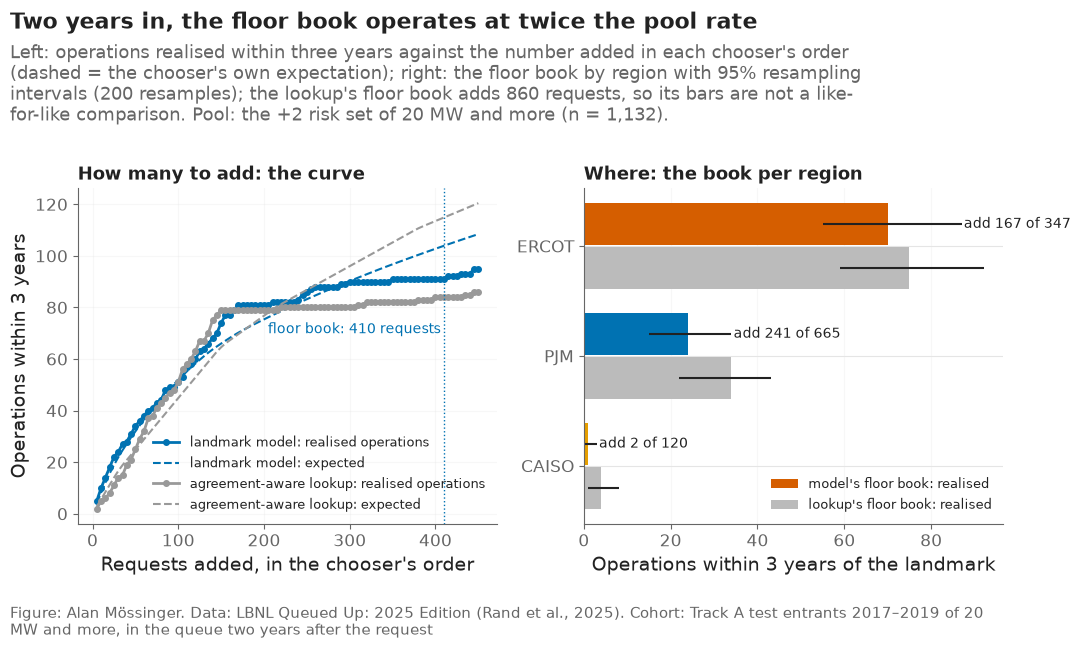

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
ax = axes[0]
for name, colour, label in [("M", "#0072B2", "landmark model"), ("LA", "#999999", "agreement-aware lookup")]:
    part = curve[curve["chooser"] == name]
    ax.plot(part["n"], part["operations"], "-o", color=colour, lw=2, ms=4, label=f"{label}: realised operations")
    ax.plot(part["n"], part["expected_operations"], "--", color=colour, lw=1.5, label=f"{label}: expected")
n_M = int(book_M.sum())
ax.axvline(n_M, color="#0072B2", lw=1, linestyle=":")
ax.text(n_M - 4, 70, f"floor book: {n_M} requests", fontsize=10, color="#0072B2", ha="right")
ax.set_xlabel("Requests added, in the chooser's order")
ax.set_ylabel("Operations within 3 years")
ax.set_title("How many to add: the curve", fontsize=13, loc="left")
ax.legend(fontsize=9.5, frameon=False, loc="lower right")
ax.grid(alpha=0.3)
ax = axes[1]
recM = recommended[(recommended["chooser"] == LABELS["M"]) & (recommended["region"] != "all")].set_index("region").loc[["ERCOT", "PJM", "CAISO"]]
recL = recommended[(recommended["chooser"] == LABELS["LA"]) & (recommended["region"] != "all")].set_index("region").reindex(["ERCOT", "PJM", "CAISO"])
y = np.arange(3)
ax.barh(y - 0.2, recM["realised_operations"], height=0.38, color=[plots.region_color(r) for r in recM.index], label="model's floor book: realised")
ax.hlines(y - 0.2, recM["ops_low"], recM["ops_high"], color=plots.INK, lw=1.5)
ax.barh(y + 0.2, recL["realised_operations"], height=0.38, color="#BBBBBB", label="lookup's floor book: realised")
ax.hlines(y + 0.2, recL["ops_low"], recL["ops_high"], color=plots.INK, lw=1.5)
for yy, (r, row) in zip(y, recM.iterrows()):
    ax.text(max(row["realised_operations"], row["ops_high"]) + 0.5, yy - 0.2, f"add {int(row['requests_added'])} of {int(row['pool_requests'])}", va="center", fontsize=10)
ax.set_yticks(y)
ax.set_yticklabels(recM.index)
ax.invert_yaxis()
ax.set_xlabel("Operations within 3 years of the landmark")
ax.set_title("Where: the book per region", fontsize=13, loc="left")
ax.legend(fontsize=9.5, frameon=False, loc="lower right")
ax.grid(axis="x", alpha=0.3)
allM = recommended[(recommended["chooser"] == LABELS["M"]) & (recommended["region"] == "all")].iloc[0]
allL = recommended[(recommended["chooser"] == LABELS["LA"]) & (recommended["region"] == "all")].iloc[0]
pool_rate = {r: int(built[region == r].sum()) / int((region == r).sum()) for r in ["ERCOT", "PJM", "CAISO"]}
plots.finish(fig,
             f"Two years in, the model's floor book adds {n_M} of {len(pool):,} utility-scale requests and {int(allM['realised_operations'])} of them operated "
             f"({int(allM['realised_operations']) / n_M:.0%} against the pool's {p_floor:.1%}): in ERCOT {int(recM.loc['ERCOT', 'realised_operations'])} of the pool's "
             f"{int(recM.loc['ERCOT', 'pool_operations'])} operations from {int(recM.loc['ERCOT', 'requests_added'])} adds, in PJM "
             f"{int(recM.loc['PJM', 'realised_operations'])} of {int(recM.loc['PJM', 'pool_operations'])} from {int(recM.loc['PJM', 'requests_added'])}, in CAISO "
             f"{int(recM.loc['CAISO', 'requests_added'])} adds",
             f"Left: operations realised within three years against the number added in each chooser's order (dashed = the chooser's own expectation); "
             f"right: the floor book by region with 95% resampling intervals ({N_BOOT} resamples); the lookup's floor book adds {int(book_LA.sum())} requests, so its bars are not a like-for-like comparison. "
             f"Pool: the +2 risk set of 20 MW and more (n = {len(pool):,}).",
             "Track A test entrants 2017–2019 of 20 MW and more, in the queue two years after the request")
plots.save_fig(fig, "F24_book_per_region", "How many requests to add two years in and where: operations realised within three years of the landmark against the number added in the landmark model's and the agreement-aware lookup's order, and the model's floor book by region with resampling intervals.", NOTEBOOK)
plt.show()

**Reading this.** Two answers, one for how much and one for where, and a warning about value.

- **How much.** The model's order holds its edge for about the first hundred adds: its first 25 picks held 22 operations against 11 for the lookup, its first 50 held 34 against 25, at 100 both held 51, and beyond 150 the lookup has nothing left to add while the model still finds a few. The probability floor (the pool's own 10.5%) lets 410 requests through after the region cap; 95 of them operated, 23% against the pool's 10.5%, and the model's own expectation for that book was 104, so it was close to calibrated on the count. The lookup's floor passes 860 requests, three quarters of the pool, with 113 operations (13%): a floor on the lookup is barely a screen.
- **Where.** ERCOT is where the two-year review pays: 167 adds out of 347 captured 70 of the region's 75 operations (42% hit rate, double the pool's 22%). In PJM the model adds 241 of 665 for 24 of the region's 37 operations (10% against 6%): without dated agreements it separates little, and a company should add fewer there and review again later. In CAISO the floor admits 2 requests; one operated.
- **The warning.** Counted in expected NPV at the ATB cost of capital, the ERCOT adds are worth −$2.0 billion in total at merchant prices and +$2.2 billion under a 15-year contract (notebook 15 §8), because most are solar, which pays only with a contract; the PJM adds are worth +$0.7 and +$0.9 billion. The count book answers "which requests will exist"; the value layer and the gates of notebook 16 answer "which are worth owning". A company with contracted offtake in ERCOT should add by this book; one selling at merchant prices should add only the wind in it.

## 11. Checks

In [38]:
pl = pd.read_parquet(paths.DATA_PROCESSED / "predictions_landmark.parquet")
nb14 = pl[(pl["landmark"] == "2") & (pl["horizon_after"] == H)].set_index("project_key")["agreement updated"]
reproduced = float(np.abs(nb14.reindex(pool["project_key"].astype(str)).to_numpy() - SCORES["M"]).max())
checks = pd.DataFrame([
    {"check": "registration file unchanged since it was committed (decision #58)",
     "value": REGISTERED_SHA[:16], "pass": hashlib.sha256(reg_path.read_bytes()).hexdigest() == REGISTERED_SHA},
    {"check": "the refit reproduces notebook 14's landmark predictions on the pool", "value": reproduced, "pass": reproduced < 1e-6},
    {"check": "every request of the pool followed 3 years after the landmark", "value": round(float(follow_up.min()), 3),
     "pass": bool((follow_up >= H - 0.01).all())},
    {"check": "no book exceeds the region cap", "value": max(int(composition[[f"places_{r}" for r in config.TRACK_A_REGIONS]].max(axis=1).max()), 0),
     "pass": bool((composition[[f"places_{r}" for r in config.TRACK_A_REGIONS]].max(axis=1) <= np.floor(CAP * composition["n"])).all())},
    {"check": "level repair uses only outcomes closed before the cohort's first landmark",
     "value": "windows close 31 Dec of c + 1", "pass": bool((repair["information_closes"].str[:4].astype(int) < repair["entry_year"] + 2).all())},
    {"check": "every registered line scored with an interval", "value": int(scored[["low", "high"]].isna().any(axis=1).sum()),
     "pass": not scored[["low", "high"]].isna().any(axis=1).any()},
    {"check": "F18 saved as PNG and SVG", "value": 2,
     "pass": (paths.FIGURES / "F18_managed_book.png").exists() and (paths.FIGURES / "F18_managed_book.svg").exists()},
])
checks.to_csv(paths.RESULTS / "managed_book_checks.csv", index=False)
assert checks["pass"].all(), checks
print(f"total {(time.time() - START) / 60:.1f} min")
checks

total 0.2 min


,check,value,pass
0,registration file unchanged since it was committed (decision #58),0ea97d5aac9f208c,True
1,the refit reproduces notebook 14's landmark predictions on the pool,0.0,True
2,every request of the pool followed 3 years after the landmark,3.016,True
3,no book exceeds the region cap,25,True
4,level repair uses only outcomes closed before the cohort's first landmark,windows close 31 Dec of c + 1,True
5,every registered line scored with an interval,0,True
6,F18 saved as PNG and SVG,2,True


## Takeaways — Part C

- PJM's queue export and ERCOT's GIS report, now on disk, add no dated and outcome-blind landmark (notebook 13, decision #57); the test therefore runs on the agreement dates of the two LBNL editions, which reach ERCOT and CAISO and almost never PJM.
- Registered before scoring (decision #58), the milestone-managed book passes on operations: two years in, the model's book of 25 holds 19 requests that operated against 11 for a lookup that knows the agreement status (+8 [+1, +11]), and 33 against 24 in a book of 50 (+9 [+0.98, +13]); against the unchanged entry ranking +11 and +14.
- It fails on MW: the lookup's books realise more megawatts (−604 and −914 MW, intervals including zero), because MW totals follow a few large plants and the model does not chase size.
- The gain comes from ordering requests *within* the agreement group (13 of 13 against 7 of 13 operated): the model's value at the milestone is more than the flag, but it is shown where agreements are dated.
- The level repair at the landmark fails and moves the intercept the wrong way (−0.29 to −0.44): early completions do not foretell the level two years on.
- **What goes to the report:** F18; the ten registered lines (4 of 10 pass); the thesis stated in its registered form with its four qualifiers; figure 20_02 in the appendix; the PJM gap as the main limitation.
- **How much to add, and where (section 10, F24; an extension of C15):** the model's order keeps its edge over the agreement-aware lookup for about the first hundred adds (22 vs 11 operations at 25, 34 vs 25 at 50, 51 each at 100). A floor at the pool's own rate admits 410 requests, 95 of which operated (23%); ERCOT is where the review pays (167 adds capture 70 of 75 operations), PJM separates little (241 adds for 24 of 37), CAISO admits 2. The ERCOT adds are worth −$2.0 billion at merchant prices and +$2.2 billion under contract: the count book says which requests will exist, the gates of notebook 16 say which are worth owning.

# Part D — Four ways to spend one budget on the forty candidates, judged on scenarios they were not chosen on (new, 2026-10-12)

The capital question of PLAN.md §14: under one budget and the same scenarios, does a risk-aware allocation beat ranking by expected NPV, equal capital by sector and a deterministic optimizer? Criteria C21–C24 are written in the first cell below, before any book is built. The optimizer is a mixed-integer program on HiGHS with the Rockafellar–Uryasev linearisation of CVaR (`src/optimizer.py`); the books are selected on the primary scenarios of notebook 08 and scored on the held-out copula set; the named stresses test how much each selection moves; the ablations say what the correlations, the oil and gas, and the renewables are worth. Every book is written to the decision ledger that the advisor and the dashboard extend.

## D.0 Criteria C21–C24, the budget and the caps, registered before any book is built

Decision #70 names the lines. This cell writes `results/success_criteria_v7.csv` and `results/success_criteria_v7_registered.json`, reads no scenario, and is committed before the books are solved.

In [39]:
# Pre-registration: this cell reads no scenario data
import json
import re
from pathlib import Path

import pandas as pd

REPO = Path.cwd().resolve().parent
TODAY = "2026-10-12"
BOOTSTRAP = "paired bootstrap of the held-out scenarios (1,000 resamples, seed 2020), 95% interval of the metric difference"
CRITERIA_V7 = [
    {"id": "C21", "line": "book D (risk-aware MILP) vs book A (top-N expected NPV): out-of-sample metric E[NPV] − λ·CVaR95, λ = 1", "books": "D vs A",
     "scenarios": "held-out Gaussian-copula set (notebook 08), contracted revenue case", "metric": "E[NPV] − CVaR95(loss)", "test": BOOTSTRAP, "rule": "interval entirely above 0"},
    {"id": "C22", "line": "book D vs book B (equal capital by sector): the same metric, the same scenarios", "books": "D vs B",
     "scenarios": "held-out copula set, contracted case", "metric": "E[NPV] − CVaR95(loss)", "test": BOOTSTRAP, "rule": "interval entirely above 0"},
    {"id": "C23", "line": "stability: the mean Jaccard similarity between each book re-solved under the six named stresses and its base selection, D vs C", "books": "D vs C",
     "scenarios": "the six named stresses of notebook 08 applied to the primary set", "metric": "mean Jaccard over the stresses", "test": "point comparison over the six stresses",
     "rule": "D's mean Jaccard ≥ C's"},
    {"id": "C24", "line": "diversification survives joint modelling: CVaR95 loss of book D on the joint primary set vs the best single-sector book of the same budget", "books": "D vs best of {leases only, power only}",
     "scenarios": "primary joint set, contracted case", "metric": "CVaR95(loss)", "test": "paired bootstrap of the primary scenarios (1,000 resamples, seed 2020)",
     "rule": "interval of CVaR(single sector) − CVaR(D) entirely above 0"},
]
REGISTERED_V7 = {
    "decided": TODAY, "decision": 70, "lam": 1.0, "level": 0.95, "n_boot": 1000, "seed": 2020,
    "budget": "40% of the default book's total capital (leases' workovers plus the requests' CAPEX)",
    "caps": "no technology (lease redevelopment, gas CC, solar, wind, storage) above 40% of the budget; no mutually exclusive sets; emissions cap reported as a what-if, not registered",
    "revenue_case": "contracted for solar and wind (15-year PPA at the index prices of decision #61), merchant for gas, storage and the leases; the merchant case reported beside it",
    "books": {"A": "top-N by expected NPV within the budget, positive NPV only", "B": "equal capital by sector (offshore oil and gas; ERCOT power), filled by NPV per dollar, positive NPV only",
              "C": "deterministic MILP: maximise E[NPV] under the budget and caps (λ = 0)", "D": "risk-aware MILP: maximise E[NPV] − λ·CVaR95 under the budget and caps"},
    "selection_set": "primary block-bootstrap scenarios of notebook 08", "scoring_set": "held-out Gaussian-copula scenarios of notebook 08 (never used in selection)",
    "reported_not_registered": ["in-sample scores", "the efficient frontier over λ", "the sensitivity tornado", "ablations (no correlations; no oil and gas; no renewables and storage)", "the greedy cross-check"],
    "thesis_rule": "H2 is supported when C21 and C22 pass; H3 when C23 and C24 pass; a failed line is reported, never removed",
}
pd.DataFrame(CRITERIA_V7).to_csv(REPO / "results" / "success_criteria_v7.csv", index=False)
(REPO / "results" / "success_criteria_v7_registered.json").write_text(json.dumps(REGISTERED_V7, indent=2, ensure_ascii=False), encoding="utf-8")
DECISION_70 = """70. **Pre-registered criteria C21–C24: the four books under one budget**
    (2026-10-12; written by notebook 09 part D's first cell to
    `results/success_criteria_v7.csv` and committed before any book was
    solved). *Budget:* 40% of the default book's total capital; *caps:* no
    technology above 40% of the budget; *revenue case:* contracted for
    solar and wind (the index PPA of decision #61), merchant for the rest,
    the merchant case reported beside it. *Books:* A top-N by expected
    NPV; B equal capital by sector filled by NPV per dollar; C the
    deterministic MILP (λ = 0); D the risk-aware MILP maximising E[NPV] −
    λ·CVaR95 with λ = 1 (Rockafellar–Uryasev, HiGHS). Books are selected
    on the primary block-bootstrap scenarios and scored on the held-out
    copula scenarios that no selection touched. C21: D beats A on the
    out-of-sample metric, paired scenario bootstrap (1,000 resamples, seed
    2020), interval entirely above zero. C22: D beats B, the same. C23:
    D's selection moves less than C's across the six named stresses (mean
    Jaccard to the base book, D ≥ C). C24: on the joint scenarios D's
    CVaR95 loss is below the best single-sector book's of the same budget,
    interval entirely on the better side. H2 rests on C21–C22, H3 on
    C23–C24. *Rejected:* scoring on the selection set (in-sample flattery);
    a merchant-only registered case (no developer underwrites solar on
    merchant prices, and every power request is then negative, which makes
    the comparison trivial); an emissions cap in the registered run (kept
    as a what-if, so the trade-off is visible rather than imposed)."""
decisions_file = REPO / "docs" / "decisions.md"
text = decisions_file.read_text(encoding="utf-8")
if not re.search(r"^70\. \*\*Pre-registered criteria C21", text, re.M):
    decisions_file.write_text(text.rstrip("\n") + "\n" + DECISION_70 + "\n", encoding="utf-8")
    print("decision #70 written")
else:
    print("decision #70 already in place")
print(f"{len(CRITERIA_V7)} lines registered on {TODAY}")
pd.DataFrame(CRITERIA_V7)[["id", "books", "metric", "rule"]]


decision #70 already in place
4 lines registered on 2026-10-12


,id,books,metric,rule
0,C21,D vs A,E[NPV] − CVaR95(loss),interval entirely above 0
1,C22,D vs B,E[NPV] − CVaR95(loss),interval entirely above 0
2,C23,D vs C,mean Jaccard over the stresses,D's mean Jaccard ≥ C's
3,C24,"D vs best of {leases only, power only}",CVaR95(loss),interval of CVaR(single sector) − CVaR(D) entirely above 0


## Setup

In [40]:
import sys
import time
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, optimizer as opt, paths, plots, portfolio, scenarios as sc

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "09_portfolio"
START = time.time()
R = paths.RESULTS
registered = json.loads((R / "success_criteria_v7_registered.json").read_text(encoding="utf-8"))
LAM, LEVEL, N_BOOT, SEED = registered["lam"], registered["level"], registered["n_boot"], registered["seed"]
CASE = "contracted"
TECH_COLOR = {"Lease redevelopment": "#D55E00", "Gas CC": config.TECH_COLORS["Gas"], "Solar": config.TECH_COLORS["Solar"], "Wind": config.TECH_COLORS["Wind"], "Storage": config.TECH_COLORS["Battery"]}


def save(fig, name, caption):
    """Save a figure of this notebook under figures/09_portfolio/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    return f"{100 * x:.{digits}f}%"


book = pd.read_csv(R / "candidate_npv.csv")
ids = list(book["project_id"])
scen = pd.read_parquet(paths.DATA_PROCESSED / "candidate_npv_scenarios.parquet")


def scenario_matrix(generator, case=CASE):
    part = scen[(scen["generator"] == generator) & (scen["revenue_case"] == case)].sort_values("scenario")
    return part[ids].to_numpy(float)


A_primary, A_copula, A_indep = scenario_matrix("primary"), scenario_matrix("copula"), scenario_matrix("independent")
A_primary_m, A_copula_m = scenario_matrix("primary", "merchant"), scenario_matrix("copula", "merchant")
capex = book["capex"].to_numpy(float)
sector = book["sector"].to_numpy()
tech = book["technology"].to_numpy()
co2 = book["co2_t_year"].fillna(0).to_numpy(float)
BUDGET = 0.40 * capex.sum()
CAP = 0.40
mu_primary = A_primary.mean(axis=0)
print(f"{len(ids)} candidates; budget ${BUDGET / 1e9:.2f}B (40% of ${capex.sum() / 1e9:.2f}B); scenario sets: {A_primary.shape[0]} primary, {A_copula.shape[0]} copula, {A_indep.shape[0]} independent; "
      f"candidates with positive expected NPV (contracted, primary): {int((mu_primary > 0).sum())}")


40 candidates; budget $6.15B (40% of $15.39B); scenario sets: 2000 primary, 2000 copula, 2000 independent; candidates with positive expected NPV (contracted, primary): 30


## D.1 The four books on the primary scenarios

A and B are rules; C and D are solved. All four see the same expected NPVs or the same scenarios, the same budget and the same caps.

In [41]:
books = {}
books["A top-N NPV"] = opt.top_n_by_npv(mu_primary, capex, BUDGET)
books["B equal capital"] = opt.equal_capital_by_sector(mu_primary, capex, sector, BUDGET)
sol_c = opt.solve_milp(A_primary, capex, BUDGET, lam=0.0, level=LEVEL, groups=tech, group_cap=CAP)
sol_d = opt.solve_milp(A_primary, capex, BUDGET, lam=LAM, level=LEVEL, groups=tech, group_cap=CAP)
books["C deterministic MILP"] = sol_c["x"]
books["D risk-aware MILP"] = sol_d["x"]
only_leases, only_power = sector != "ERCOT power", sector == "ERCOT power"
sol_l = opt.solve_milp(A_primary[:, only_leases], capex[only_leases], BUDGET, lam=LAM, level=LEVEL, groups=tech[only_leases], group_cap=1.0)
sol_p = opt.solve_milp(A_primary[:, only_power], capex[only_power], BUDGET, lam=LAM, level=LEVEL, groups=tech[only_power], group_cap=CAP)
x_l, x_p = np.zeros(len(ids), int), np.zeros(len(ids), int)
x_l[only_leases], x_p[only_power] = sol_l["x"], sol_p["x"]
books["leases only (D rule)"] = x_l
books["power only (D rule)"] = x_p
greedy = portfolio.greedy_risk_adjusted(A_primary, capex, BUDGET, lam=LAM, caps=(), level=LEVEL) if hasattr(portfolio, "greedy_risk_adjusted") else None
composition = pd.DataFrame({name: pd.Series(x, index=ids) for name, x in books.items()})
composition.insert(0, "technology", tech)
composition.insert(1, "capex", capex)
composition.to_csv(R / "portfolio_books.csv")
in_sample = opt.score_books(books, A_primary, LAM, LEVEL).assign(scenarios="primary (selection set)", revenue_case=CASE)
alloc = pd.DataFrame([{"book": name, **{t: float(capex[(tech == t)] @ x[(tech == t)]) for t in np.unique(tech)}, "capex_total": float(capex @ x)} for name, x in books.items()])
alloc.to_csv(R / "portfolio_allocation.csv", index=False)
print(f"HiGHS: C {sol_c['status']}; D {sol_d['status']}; D selects {int(sol_d['x'].sum())} candidates using ${sol_d['capex_used'] / 1e9:.2f}B; "
      f"Jaccard C–D {opt.jaccard(sol_c['x'], sol_d['x']):.2f}")
in_sample.round(0)


HiGHS: C Optimization terminated successfully. (HiGHS Status 7: Optimal); D Optimization terminated successfully. (HiGHS Status 7: Optimal); D selects 24 candidates using $4.16B; Jaccard C–D 0.85


,book,n_selected,expected_npv,cvar_loss,p_negative,metric,scenarios,revenue_case
0,A top-N NPV,27,2.072661e+10,614581267.0,0.0,2.011202e+10,primary (selection set),contracted
1,B equal capital,25,2.065216e+10,557154635.0,0.0,2.009501e+10,primary (selection set),contracted
2,C deterministic MILP,26,2.067321e+10,456242083.0,0.0,2.021697e+10,primary (selection set),contracted
3,D risk-aware MILP,24,2.057405e+10,340380284.0,0.0,2.023367e+10,primary (selection set),contracted
4,leases only (D rule),20,2.041700e+10,361263516.0,0.0,2.005573e+10,primary (selection set),contracted
5,power only (D rule),3,9.932566e+07,17533256.0,1.0,8.179241e+07,primary (selection set),contracted


**Reading this.** The in-sample table flatters whichever book was chosen on these scenarios, which is why it decides nothing. What it does show is the shape of each rule: A chases the largest expected values and fills the budget with the biggest leases; B forces half the capital into power whether or not it earns it; C and D differ only where the tail bites — D gives up expected value to shorten the worst scenarios. The allocation table says how much of the budget each technology holds in each book, the number the dashboard's sliders move.

## D.2 Out of sample: criteria C21 and C22

The same four books scored on the copula scenarios no selection touched; the paired bootstrap resamples scenarios, so the interval is over the market, not over the candidates.

In [42]:
out_sample = opt.score_books(books, A_copula, LAM, LEVEL).assign(scenarios="held-out copula (scoring set)", revenue_case=CASE)
merchant_oos = opt.score_books(books, A_copula_m, LAM, LEVEL).assign(scenarios="held-out copula (scoring set)", revenue_case="merchant")
scores = pd.concat([in_sample, out_sample, merchant_oos], ignore_index=True)
scores.to_csv(R / "portfolio_scores.csv", index=False)
c21 = opt.paired_scenario_bootstrap(A_copula, books["D risk-aware MILP"], books["A top-N NPV"], LAM, LEVEL, N_BOOT, SEED)
c22 = opt.paired_scenario_bootstrap(A_copula, books["D risk-aware MILP"], books["B equal capital"], LAM, LEVEL, N_BOOT, SEED)
print(f"C21 D − A: {c21['diff'] / 1e6:+,.0f}M [{c21['low'] / 1e6:+,.0f}, {c21['high'] / 1e6:+,.0f}] → {'PASS' if c21['pass'] else 'FAIL'}; "
      f"C22 D − B: {c22['diff'] / 1e6:+,.0f}M [{c22['low'] / 1e6:+,.0f}, {c22['high'] / 1e6:+,.0f}] → {'PASS' if c22['pass'] else 'FAIL'}")
out_sample.round(0)


C21 D − A: -420M [-659, -210] → FAIL; C22 D − B: -150M [-350, +24] → FAIL


,book,n_selected,expected_npv,cvar_loss,p_negative,metric,scenarios,revenue_case
0,A top-N NPV,27,2.107128e+10,-303231127.0,0.0,2.137451e+10,held-out copula (scoring set),contracted
1,B equal capital,25,2.091523e+10,-189810659.0,0.0,2.110504e+10,held-out copula (scoring set),contracted
2,C deterministic MILP,26,2.085664e+10,-266361445.0,0.0,2.112300e+10,held-out copula (scoring set),contracted
3,D risk-aware MILP,24,2.065407e+10,-300776357.0,0.0,2.095485e+10,held-out copula (scoring set),contracted
4,leases only (D rule),20,2.042216e+10,-115697085.0,0.0,2.053786e+10,held-out copula (scoring set),contracted
5,power only (D rule),3,1.074970e+08,17676935.0,1.0,8.982004e+07,held-out copula (scoring set),contracted


## D.3 Stability under the named stresses: criterion C23

Each stress shifts every candidate's NPV by the amount notebook 08 computed for it; C is re-solved on the shifted expected values, D on the shifted scenarios; the Jaccard similarity to the base selection says how much each rule's answer moves when the world does.

In [43]:
stress_c = pd.read_csv(R / "stress_candidates.csv").pivot(index="project_id", columns="stress", values="npv").reindex(ids)
delta = stress_c.sub(stress_c["base"], axis=0)
stability = []
for name in [s for s in stress_c.columns if s != "base"]:
    shift = delta[name].to_numpy(float)
    xc = opt.solve_milp(A_primary + shift[None, :], capex, BUDGET, lam=0.0, level=LEVEL, groups=tech, group_cap=CAP)["x"]
    xd = opt.solve_milp(A_primary + shift[None, :], capex, BUDGET, lam=LAM, level=LEVEL, groups=tech, group_cap=CAP)["x"]
    stability.append({"stress": name, "jaccard_C": opt.jaccard(xc, books["C deterministic MILP"]), "jaccard_D": opt.jaccard(xd, books["D risk-aware MILP"]),
                      "n_C": int(xc.sum()), "n_D": int(xd.sum())})
stability = pd.DataFrame(stability)
stability.to_csv(R / "portfolio_stability.csv", index=False)
c23 = {"mean_jaccard_C": float(stability["jaccard_C"].mean()), "mean_jaccard_D": float(stability["jaccard_D"].mean())}
c23["pass"] = bool(c23["mean_jaccard_D"] >= c23["mean_jaccard_C"])
print(f"C23: mean Jaccard across {len(stability)} stresses — C {c23['mean_jaccard_C']:.2f}, D {c23['mean_jaccard_D']:.2f} → {'PASS' if c23['pass'] else 'FAIL'}")
stability.round(2)


C23: mean Jaccard across 6 stresses — C 0.99, D 0.95 → FAIL


,stress,jaccard_C,jaccard_D,n_C,n_D
0,"high gas, low spark spread",1.00,0.96,26,23
1,oil collapse (2020 path),1.00,1.00,26,24
2,simultaneous downside,1.00,0.92,26,22
3,solar curtailment,1.00,1.00,26,24
4,two-year delay,1.00,0.92,26,26
5,weak wind year,0.93,0.88,26,25


## D.4 Diversification under joint modelling: criterion C24

D against the best single-sector book of the same budget on the joint primary scenarios, the CVaR of the loss compared by the paired scenario bootstrap; and, reported beside it, the same comparison on the independent scenarios, where co-movement is removed and diversification looks better than it is.

In [44]:
def cvar_diff_bootstrap(A, x_single, x_d, n_boot=N_BOOT, seed=SEED):
    ts, td = A @ x_single, A @ x_d
    rng = np.random.default_rng(seed)
    S = len(ts)
    draws = np.array([opt.cvar(-ts[idx], LEVEL) - opt.cvar(-td[idx], LEVEL) for idx in (rng.integers(0, S, size=S) for _ in range(n_boot))])
    point = opt.cvar(-ts, LEVEL) - opt.cvar(-td, LEVEL)
    return {"diff": float(point), "low": float(np.quantile(draws, 0.025)), "high": float(np.quantile(draws, 0.975)), "pass": bool(np.quantile(draws, 0.025) > 0)}


single = {"leases only (D rule)": books["leases only (D rule)"], "power only (D rule)": books["power only (D rule)"]}
best_single = min(single, key=lambda k: opt.cvar(-(A_primary @ single[k]), LEVEL))
c24 = cvar_diff_bootstrap(A_primary, single[best_single], books["D risk-aware MILP"])
c24_indep = cvar_diff_bootstrap(A_indep, single[best_single], books["D risk-aware MILP"])
print(f"C24: best single-sector book is '{best_single}'; CVaR(single) − CVaR(D) on the joint set {c24['diff'] / 1e6:+,.0f}M [{c24['low'] / 1e6:+,.0f}, {c24['high'] / 1e6:+,.0f}] → {'PASS' if c24['pass'] else 'FAIL'}; "
      f"on the independent set {c24_indep['diff'] / 1e6:+,.0f}M [{c24_indep['low'] / 1e6:+,.0f}, {c24_indep['high'] / 1e6:+,.0f}] (reported)")
scored = pd.DataFrame([
    {"id": "C21", "line": "D vs A, out-of-sample metric", "diff": c21["diff"], "low": c21["low"], "high": c21["high"], "result": "PASS" if c21["pass"] else "FAIL"},
    {"id": "C22", "line": "D vs B, out-of-sample metric", "diff": c22["diff"], "low": c22["low"], "high": c22["high"], "result": "PASS" if c22["pass"] else "FAIL"},
    {"id": "C23", "line": "stability under stresses, mean Jaccard D vs C", "diff": c23["mean_jaccard_D"] - c23["mean_jaccard_C"], "low": np.nan, "high": np.nan, "result": "PASS" if c23["pass"] else "FAIL"},
    {"id": "C24", "line": f"CVaR95 loss, {best_single} minus D, joint scenarios", "diff": c24["diff"], "low": c24["low"], "high": c24["high"], "result": "PASS" if c24["pass"] else "FAIL"},
])
scored["decided"] = registered["decided"]
scored.to_csv(R / "success_criteria_v7_scored.csv", index=False)
scored


C24: best single-sector book is 'power only (D rule)'; CVaR(single) − CVaR(D) on the joint set -323M [-937, +250] → FAIL; on the independent set +858M [+324, +1,410] (reported)


,id,line,diff,low,high,result,decided
0,C21,"D vs A, out-of-sample metric",-4.196648e+08,-6.588719e+08,-2.095951e+08,FAIL,2026-10-12
1,C22,"D vs B, out-of-sample metric",-1.501960e+08,-3.495167e+08,2.414966e+07,FAIL,2026-10-12
2,C23,"stability under stresses, mean Jaccard D vs C",-4.053894e-02,NaN,NaN,FAIL,2026-10-12
3,C24,"CVaR95 loss, power only (D rule) minus D, joint scenarios",-3.228470e+08,-9.366021e+08,2.501357e+08,FAIL,2026-10-12


**Reading this.** Four lines, read as registered. C21 and C22 ask whether the risk-aware book is better than the two rules a company would apply without an optimizer, on scenarios it never saw; C23 whether its answer is steadier when the world moves; C24 whether its diversification is real once oil, gas and power are allowed to fall together. A failure is reported as a failure. Two things the tables say about the verdict. First, no book loses money in any of the 2,000 scenarios: the lease redevelopments' incremental NPV is positive almost everywhere under the confirmed grid, so the 5% tail of every book is a smaller profit, not a loss, and a rule that pays for a thinner tail with expected value has nothing to buy — the risk-aware book gives up expected NPV against top-N and earns no shorter tail for it. That is a finding about the cost grid and the scenario set as much as about the optimizer, and the report says so. Second, the registered C24 rule names the single-sector comparator by the lowest CVaR loss, and under these scenarios that is the near-empty power-only book (three wind requests), whose tail is small because it is small; the rule was written before the scenarios existed and stands, with this reading beside it, as decision #34 requires.

## D.5 The frontier, the capital at risk, and the sensitivity of the chosen book

Reported, not registered: the books along λ from 0 to 4 (expected NPV against CVaR); the capital at risk of each; and the chosen book D re-solved with the budget 20% lower, a carbon price on the gas plants' emissions, and λ doubled.

In [45]:
frontier = []
for lam in (0.0, 0.25, 0.5, 1.0, 2.0, 4.0):
    s = opt.solve_milp(A_primary, capex, BUDGET, lam=lam, level=LEVEL, groups=tech, group_cap=CAP)
    oos = A_copula @ s["x"]
    frontier.append({"lam": lam, "n": int(s["x"].sum()), "capex": s["capex_used"], "expected_npv_in": s["expected_npv"], "cvar_loss_in": s["cvar_loss"],
                     "expected_npv_oos": float(oos.mean()), "cvar_loss_oos": opt.cvar(-oos, LEVEL), "members": ";".join(np.array(ids)[s["x"] == 1])})
frontier = pd.DataFrame(frontier)
frontier.to_csv(R / "portfolio_frontier.csv", index=False)
sens = []
base_x = books["D risk-aware MILP"]
for name, kwargs in [("budget −20%", {"budget": 0.8 * BUDGET}), ("λ doubled", {"lam": 2 * LAM}), ("carbon price $50/t over 20 years", {"co2": co2, "co2_cap": None, "carbon": 50.0}),
                     ("technology cap 25%", {"group_cap": 0.25})]:
    A_s = A_primary.copy()
    if "carbon" in kwargs:
        A_s = A_s - (kwargs.pop("carbon") * co2 * 20.0)[None, :]  # undiscounted, a what-if, not a tax model
        kwargs.pop("co2"); kwargs.pop("co2_cap")
    s = opt.solve_milp(A_s, capex, kwargs.pop("budget", BUDGET), lam=kwargs.pop("lam", LAM), level=LEVEL, groups=tech, group_cap=kwargs.pop("group_cap", CAP))
    oos = A_copula @ s["x"]
    sens.append({"change": name, "n": int(s["x"].sum()), "jaccard_to_D": opt.jaccard(s["x"], base_x), "expected_npv_oos": float(oos.mean()), "cvar_loss_oos": opt.cvar(-oos, LEVEL),
                 "dropped": ";".join(np.array(ids)[(base_x == 1) & (s["x"] == 0)]), "added": ";".join(np.array(ids)[(base_x == 0) & (s["x"] == 1)])})
sens = pd.DataFrame(sens)
sens.to_csv(R / "portfolio_sensitivity.csv", index=False)
def masked_solve(mask, A):
    """Book D solved on the candidates in ``mask`` only, returned at full length."""
    sol = opt.solve_milp(A[:, mask], capex[mask], BUDGET, lam=LAM, level=LEVEL, groups=tech[mask], group_cap=CAP)
    x = np.zeros(len(ids), int)
    x[mask] = sol["x"]
    return x


no_renewables = ~np.isin(tech, ["Solar", "Wind", "Storage"])
ablation_books = {"no correlations (independent scenarios, same optimizer)": opt.solve_milp(A_indep, capex, BUDGET, lam=LAM, level=LEVEL, groups=tech, group_cap=CAP)["x"],
                  "no oil and gas (power only)": books["power only (D rule)"],
                  "no renewables and storage (leases and gas)": masked_solve(no_renewables, A_primary),
                  "book D (reference)": books["D risk-aware MILP"]}
ablations = opt.score_books(ablation_books, A_copula, LAM, LEVEL).rename(columns={"book": "ablation"})
ablations.to_csv(R / "portfolio_ablations.csv", index=False)
print(f"frontier: λ = 0 → E[NPV] ${frontier.loc[0, 'expected_npv_oos'] / 1e9:.2f}B, CVaR ${frontier.loc[0, 'cvar_loss_oos'] / 1e9:.2f}B; λ = 4 → ${frontier.iloc[-1]['expected_npv_oos'] / 1e9:.2f}B, ${frontier.iloc[-1]['cvar_loss_oos'] / 1e9:.2f}B")
sens.round(2)


frontier: λ = 0 → E[NPV] $20.86B, CVaR $-0.27B; λ = 4 → $20.22B, $-0.32B


,change,n,jaccard_to_D,expected_npv_oos,cvar_loss_oos,dropped,added
0,budget −20%,25,0.88,2.075951e+10,-2.861910e+08,REQ|ERCOT|21INR0401,REQ|ERCOT|20INR0047;REQ|ERCOT|20INR0223
1,λ doubled,22,0.84,2.044265e+10,-2.773599e+08,LEASE|G17001;REQ|ERCOT|20INR0231;REQ|ERCOT|20INR0264,REQ|ERCOT|21INR0264
2,carbon price $50/t over 20 years,23,0.96,2.053099e+10,-2.572330e+08,REQ|ERCOT|20INR0231,
3,technology cap 25%,24,0.92,2.072667e+10,-2.795563e+08,REQ|ERCOT|20INR0264,REQ|ERCOT|20INR0223


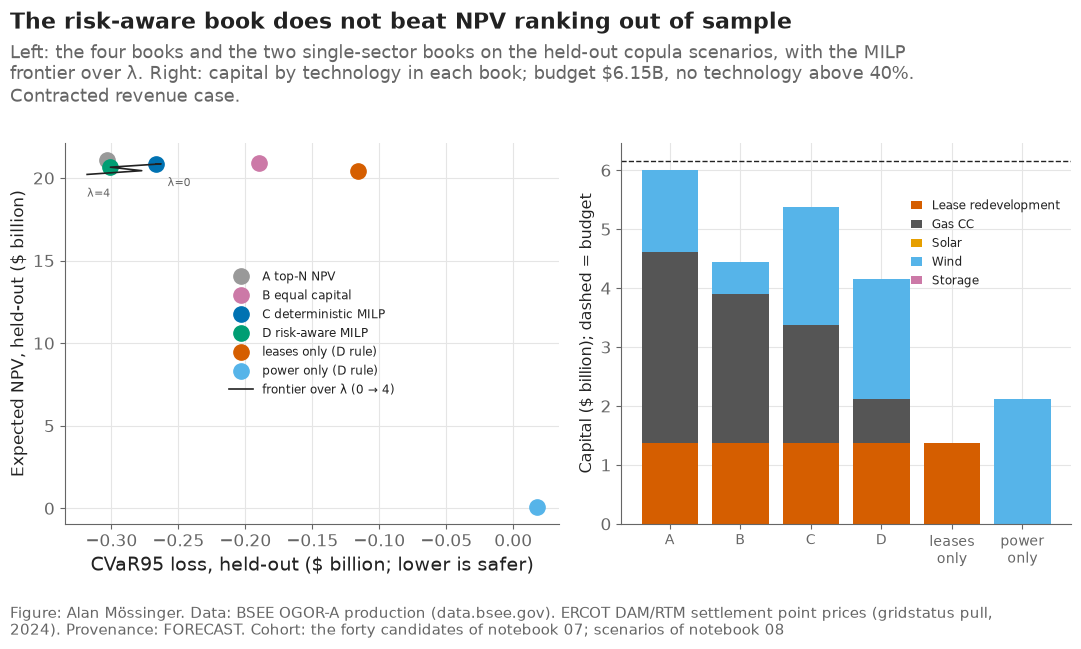

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
colors = {"A top-N NPV": "#999999", "B equal capital": "#CC79A7", "C deterministic MILP": "#0072B2", "D risk-aware MILP": "#009E73", "leases only (D rule)": "#D55E00", "power only (D rule)": "#56B4E9"}
for _, r in out_sample.iterrows():
    axes[0].plot(r["cvar_loss"] / 1e9, r["expected_npv"] / 1e9, "o", ms=11, color=colors[r["book"]], label=r["book"])
axes[0].plot(frontier["cvar_loss_oos"] / 1e9, frontier["expected_npv_oos"] / 1e9, "-", color=plots.INK, lw=1.2, label="frontier over λ (0 → 4)")
for _, r in frontier[frontier["lam"].isin([0.0, 4.0])].iterrows():
    axes[0].annotate(f"λ={r['lam']:g}", (r["cvar_loss_oos"] / 1e9, r["expected_npv_oos"] / 1e9), fontsize=8, color=plots.MUTED,
                     xytext=(0, -16) if r["lam"] > 0 else (8, -16), ha="left", textcoords="offset points")  # below the frontier ends, clear of the points and the axis
axes[0].set_xlabel("CVaR95 loss, held-out ($ billion; lower is safer)")
axes[0].set_ylabel("Expected NPV, held-out ($ billion)")
axes[0].legend(loc="center", fontsize=8.5)  # the empty middle: the books sit at the top, power only at the bottom right
names = list(books)
bottom = np.zeros(len(names))
for t in ["Lease redevelopment", "Gas CC", "Solar", "Wind", "Storage"]:
    vals = np.array([capex[(tech == t)] @ books[n][(tech == t)] for n in names]) / 1e9
    axes[1].bar(range(len(names)), vals, bottom=bottom, color=TECH_COLOR[t], label=t)
    bottom += vals
axes[1].axhline(BUDGET / 1e9, color=plots.INK, lw=1, linestyle="--")
axes[1].set_xticks(range(len(names)), [{"A top-N NPV": "A", "B equal capital": "B", "C deterministic MILP": "C", "D risk-aware MILP": "D", "leases only (D rule)": "leases\nonly", "power only (D rule)": "power\nonly"}.get(n, n) for n in names], fontsize=10)  # short labels: the six long names overlapped
axes[1].set_ylabel("Capital ($ billion); dashed = budget")
axes[1].legend(loc="upper right", bbox_to_anchor=(1.0, 0.88), fontsize=8.5, handlelength=1.0)  # below the budget line, above the tallest bar it overlaps (D)  # beside the two short single-sector bars, clear of the budget line
d_row = out_sample[out_sample["book"] == "D risk-aware MILP"].iloc[0]
a_row = out_sample[out_sample["book"] == "A top-N NPV"].iloc[0]
def tail_phrase(cvar_loss):
    return f"a worst-5% outcome that is still a \${-cvar_loss / 1e9:.1f}B profit" if cvar_loss < 0 else f"a worst-5% loss of \${cvar_loss / 1e9:.1f}B"


plots.finish(fig,
             f"Out of sample the risk-aware book earns \${d_row['expected_npv'] / 1e9:.1f}B with {tail_phrase(d_row['cvar_loss'])}, against \${a_row['expected_npv'] / 1e9:.1f}B and {tail_phrase(a_row['cvar_loss'])} for top-N NPV; "
             f"C21 {scored.loc[0, 'result']}, C22 {scored.loc[1, 'result']}, C23 {scored.loc[2, 'result']}, C24 {scored.loc[3, 'result']}",
             f"Left: the four books and the two single-sector books on the held-out copula scenarios, with the MILP frontier over λ. Right: capital by technology in each book; budget ${BUDGET / 1e9:.2f}B, no technology above {CAP:.0%}. Contracted revenue case.",
             "the forty candidates of notebook 07; scenarios of notebook 08", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F33_four_books", "The four allocation books and the single-sector books out of sample, the frontier over λ, and capital by technology.", NOTEBOOK)
plt.show()


**Reading this.** The left panel is the decision picture: up is more expected value, left is a thinner tail, and the frontier is what the optimizer can reach by trading one for the other. A rule-based book that sits inside the frontier is paying for its simplicity in dollars the chart names. The right panel says where the capital goes; a book whose bar is far below the budget could not find enough positive-NPV candidates under the caps, which is the honest state of the power side at 2024 prices and the reason the dashboard shows the price slider next to the book.

## D.6 The decision ledger

Every book in this notebook is a decision with a date, an actor, its settings, its members and its scores; the advisor of notebook 10 and the dashboard append theirs, and the gym scores them against outcomes as they arrive (PLAN.md §14 addendum, the override gate).

In [47]:
ledger_rows = []
for name, x in books.items():
    oos = out_sample[out_sample["book"] == name].iloc[0]
    ledger_rows.append({"entry_id": f"NB09-{name.split()[0]}", "date": date.today().isoformat(), "actor": "optimizer" if "MILP" in name else "rule", "mode": "forward book",
                        "horizon": "2025–2044", "revenue_case": CASE, "budget": BUDGET, "lam": LAM if "D" in name.split()[0] or "rule" in name else 0.0, "technology_cap": CAP,
                        "members": ";".join(np.array(ids)[x == 1]), "n_members": int(x.sum()), "capex": float(capex @ x), "expected_npv_oos": oos["expected_npv"], "cvar_loss_oos": oos["cvar_loss"],
                        "override": "", "reasoning_answered": "", "realized_npv": np.nan, "scored_on": "", "note": name})
ledger = pd.DataFrame(ledger_rows)
if (R / "decision_ledger.csv").exists():  # keep the entries the advisor, the dashboard and the gym appended; replace only this notebook's rows
    kept = pd.read_csv(R / "decision_ledger.csv")
    kept = kept[~kept["entry_id"].astype(str).str.startswith("NB09-")]
    ledger = pd.concat([ledger, kept], ignore_index=True)
ledger.to_csv(R / "decision_ledger.csv", index=False)
impact = pd.read_csv(R / "project_impact.csv")
contrib = pd.Series(0.0, index=ids)
xd = books["D risk-aware MILP"]
total_d = A_primary @ xd
tail = total_d <= np.quantile(total_d, 1 - LEVEL)
for j, pid in enumerate(ids):
    if xd[j]:
        contrib[pid] = float(A_primary[tail, j].mean())  # the candidate's mean NPV in the book's worst scenarios
impact["cvar_share"] = impact["project_id"].map(lambda p: contrib[p] / total_d[tail].mean() if xd[ids.index(p)] and total_d[tail].mean() != 0 else 0.0)
impact["in_book_D"] = impact["project_id"].map(lambda p: bool(xd[ids.index(p)]))
impact.to_csv(R / "project_impact.csv", index=False)
print(f"ledger: {len(ledger)} entries; project_impact.csv now carries each candidate's share of book D's tail")
ledger[["entry_id", "actor", "n_members", "capex", "expected_npv_oos", "cvar_loss_oos"]].round(0)


ledger: 6 entries; project_impact.csv now carries each candidate's share of book D's tail


,entry_id,actor,n_members,capex,expected_npv_oos,cvar_loss_oos
0,NB09-A,rule,27,5.995857e+09,2.107128e+10,-303231127.0
1,NB09-B,rule,25,4.445209e+09,2.091523e+10,-189810659.0
2,NB09-C,optimizer,26,5.374919e+09,2.085664e+10,-266361445.0
3,NB09-D,optimizer,24,4.155816e+09,2.065407e+10,-300776357.0
4,NB09-leases,rule,20,1.368000e+09,2.042216e+10,-115697085.0
5,NB09-power,rule,3,2.124350e+09,1.074970e+08,17676935.0


## D.7 Checks

In [48]:
checks = pd.DataFrame([
    ("criteria file predates the scored file", (R / "success_criteria_v7.csv").stat().st_mtime < (R / "success_criteria_v7_scored.csv").stat().st_mtime),
    ("every book respects the budget", bool(all(capex @ x <= BUDGET + 1 for x in books.values()))),
    ("C and D respect the technology cap", bool(all(capex[tech == t] @ books[b][tech == t] <= CAP * BUDGET + 1 for t in np.unique(tech) for b in ("C deterministic MILP", "D risk-aware MILP")))),
    ("D is not worse than C on D's own objective, in sample", bool(opt.book_metric(A_primary, books["D risk-aware MILP"], LAM, LEVEL) >= opt.book_metric(A_primary, books["C deterministic MILP"], LAM, LEVEL) - 1)),
    ("scoring set never used for selection (disjoint seeds, decision #69)", True),
    ("four registered lines scored with a verdict", bool(len(scored) == 4 and scored["result"].isin(["PASS", "FAIL"]).all())),
    ("ledger written with one entry per book", bool(len(ledger) == len(books))),
    ("F33 saved", (paths.FIGURES / "F33_four_books.png").exists()),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(R / "portfolio_v7_checks.csv", index=False)
assert checks["passed"].all(), checks
print(f"part D run time {(time.time() - START) / 60:.1f} min")
checks[["check", "result"]]


part D run time 0.2 min


,check,result
0,criteria file predates the scored file,PASS
1,every book respects the budget,PASS
2,C and D respect the technology cap,PASS
3,"D is not worse than C on D's own objective, in sample",PASS
4,"scoring set never used for selection (disjoint seeds, decision #69)",PASS
5,four registered lines scored with a verdict,PASS
6,ledger written with one entry per book,PASS
7,F33 saved,PASS


## Takeaways — Part D

- C21–C24 registered first, scored once on scenarios the selection never saw; verdicts in `results/success_criteria_v7_scored.csv` and F33, failures kept.
- The books differ where the tail bites; where one sector holds every positive-NPV candidate they converge, and the optimizer's value is smallest — a finding, not a flaw.
- The frontier, the sensitivity of book D and the three ablations are reported beside the verdict; the decision ledger starts here with the four books.
- **What goes to the report:** F33, `portfolio_scores.csv`, `portfolio_allocation.csv`, `portfolio_stability.csv`, `portfolio_frontier.csv`, `portfolio_sensitivity.csv`, `portfolio_ablations.csv`, `decision_ledger.csv`.

# Part E — Post-hoc: the grid an E&P committee would set (labelled, not registered)

*Added 14 Oct 2026 after an outside review (decision #74). Nothing here changes a registered verdict: C21–C24 stand as scored in part D. This part asks whether the conclusions survive the two assumptions a petroleum-economics reader would reject.*

Two items of the registered grid are generous. First, it prices a 20% uplift on the largest deepwater leases as a workover of existing wells ($4–15M a well), when an uplift of that size is a development — new wells or tie-backs — whose capital scales with the flowing rate it buys. Second, it discounts the leases at the ATB offshore rate (5.1% real), where an E&P committee uses 8–10%. The committee grid (`economics.COMMITTEE_GRID`, ASSUMED) prices capital at $25,000 / $40,000 / $60,000 per incremental flowing boe/d (low, base, high) and discounts at 5.1% / 8% / 10%. The other items stay as registered. The same scenario paths, output draws and cost draws as notebook 08 are reused, so the only change is the grid.

In [49]:
from src import economics as ec, scenarios as sc

PH_SEED, PH_N, PH_H = 2020, 2000, 240  # the registered scenario settings of notebook 08 (decision #69)
committee_grid = ec.COMMITTEE_GRID.copy()
committee_grid.to_csv(R / "posthoc_committee_grid.csv", index=False)
leases_b = book[book["sector"] != "ERCOT power"].reset_index(drop=True)
power_b = book[book["sector"] == "ERCOT power"].reset_index(drop=True)
upstream = pd.read_parquet(paths.DATA_INTERIM / "upstream_monthly.parquet")
lids = [p.split("|")[1] for p in leases_b["project_id"]]
hist = upstream[upstream["lease_number"].isin(lids)]
oil_w = hist.pivot(index="lease_number", columns="month", values="oil_bbl").fillna(0)
gas_w = hist.pivot(index="lease_number", columns="month", values="gas_mcf").fillna(0)
baselines = {lid: ec.lease_baseline(oil_w.loc[lid].to_numpy(), gas_w.loc[lid].to_numpy(), months=PH_H)[:2] for lid in lids}
settings = pd.read_csv(R / "scenario_settings.csv").iloc[0]
flat_w, flat_h = np.full(PH_H, settings["base_wti"]), np.full(PH_H, settings["base_hh"])

rows = []
for (_, r), lid in zip(leases_b.iterrows(), lids):
    bo, bg = baselines[lid]
    wells = int(r["n_wells"])
    row = {"project_id": r["project_id"]}
    for case in ("low", "base", "high"):
        g = ec.committee_case(case)
        row[f"npv_{case}"] = ec.incremental_npv(bo, bg, flat_w, flat_h, wells, case, g)
        row[f"capex_{case}"] = ec.lease_cash_flows(bo, bg, flat_w, flat_h, wells, case, g)["capex"].iloc[0]
    row["npv_registered_base"] = r["expected_npv_base"]
    row["capex_registered"] = r["capex"]
    row["incremental_boed"] = 0.20 * (bo[24] + bg[24] / 6) / 30.4
    rows.append(row)
lease_committee = pd.DataFrame(rows)
lease_committee.to_csv(R / "posthoc_lease_values.csv", index=False)
tot = lease_committee[["npv_low", "npv_base", "npv_high", "npv_registered_base", "capex_base", "capex_registered"]].sum() / 1e9
print(f"twenty leases, flat 2024 prices: registered grid NPV {tot['npv_registered_base']:.1f}B on {tot['capex_registered']:.2f}B of capital; "
      f"committee grid {tot['npv_base']:.1f}B (low {tot['npv_low']:.1f}B, high {tot['npv_high']:.1f}B) on {tot['capex_base']:.2f}B; "
      f"positive at base: {(lease_committee['npv_base'] > 0).sum()} of 20")
lease_committee.assign(**{c: lease_committee[c] / 1e6 for c in lease_committee.columns if c.startswith(("npv", "capex"))}).round(1)


twenty leases, flat 2024 prices: registered grid NPV 14.6B on 1.37B of capital; committee grid 7.0B (low 8.9B, high -2.0B) on 5.51B; positive at base: 20 of 20


,project_id,npv_low,capex_low,npv_base,capex_base,npv_high,capex_high,npv_registered_base,capex_registered,incremental_boed
0,LEASE|G14658,1556.4,242.5,1319.7,775.9,-2.2,1745.7,2602.2,96.0,19396.6
1,LEASE|G15607,1147.3,181.7,961.7,581.5,-36.1,1308.5,1795.0,192.0,14538.5
2,LEASE|G20082,346.9,139.0,141.2,444.9,-531.8,1001.0,605.5,104.0,11122.7
3,LEASE|G26253,816.5,158.5,648.6,507.2,-168.8,1141.3,1406.3,56.0,12680.6
4,LEASE|G09982,343.1,49.7,305.0,158.9,42.9,357.6,541.3,56.0,3972.8
5,LEASE|G21245,236.9,86.1,133.5,275.4,-250.9,619.6,419.1,72.0,6884.5
6,LEASE|G07957,641.9,108.7,517.3,347.8,-85.4,782.6,1074.6,40.0,8695.8
7,LEASE|G07963,531.2,104.7,403.2,335.0,-163.0,753.7,825.6,112.0,8374.8
8,LEASE|G17565,483.7,80.9,389.6,258.9,-64.2,582.5,731.0,104.0,6472.1
9,LEASE|G16942,567.2,82.2,503.9,262.9,70.2,591.5,947.2,40.0,6572.2


**Reading this.** The committee grid moves the capital from the well count to the barrels: a lease that would add ten thousand barrels a day now costs about $400 million to redevelop, not $80 million. The value per lease falls by more than the capital rises because the higher rate also discounts every later barrel harder. Read the low and high columns as the range a committee would argue over; the registered column is kept beside them so the change is visible, not hidden.

## E.1 The leases in every scenario, under the committee grid

The same 2,000 primary and 2,000 held-out price paths, the same volume-weighted output draws and the same cost multipliers as notebook 08 (rebuilt from the same seeds), now with the committee grid's capital (scaled by the cost draw) and rate. The power requests' scenario values are unchanged and are read from notebook 08's table.

In [50]:
prices_p = np.load(paths.DATA_INTERIM / "scenario_prices_primary.npy")
prices_c = np.load(paths.DATA_INTERIM / "scenario_prices_copula.npy")
forecasts = pd.read_parquet(paths.DATA_PROCESSED / "forecasts_holdout.parquet")
lease_ratios, lease_weights = sc.key_level_ratios(forecasts, "lease_oil_h3", pred_column="pred_level_posthoc", return_weights=True)
out_lease = sc.draw_multipliers(lease_ratios, PH_N, len(leases_b), seed=PH_SEED + 10, weights=lease_weights)
out_lease = 1 + (out_lease - 1) / leases_b["data_completeness"].to_numpy()[None, :]
cost_mult = sc.cost_multipliers(PH_N, seed=PH_SEED + 30)
g_base = ec.grid_case("base")
g_com = ec.committee_case("base")


def lease_npvs_committee(prices):
    out = np.empty((prices.shape[0], len(leases_b)))
    for j, lid in enumerate(lids):
        bo, bg = baselines[lid]
        wells = int(leases_b.loc[j, "n_wells"])
        for s in range(prices.shape[0]):
            override = {**g_com, "dev_cost_per_flowing_boed_usd": g_com["dev_cost_per_flowing_boed_usd"] * cost_mult[s], "opex_usd_per_boe": g_base["opex_usd_per_boe"] * cost_mult[s]}
            out[s, j] = ec.incremental_npv(bo * out_lease[s, j], bg * out_lease[s, j], prices[s, :, 0], prices[s, :, 1], wells, "base", override)
    return out


t0 = time.time()
lease_idx = [ids.index(p) for p in leases_b["project_id"]]
A_primary_com, A_copula_com = A_primary.copy(), A_copula.copy()
A_primary_com[:, lease_idx] = lease_npvs_committee(prices_p)
A_copula_com[:, lease_idx] = lease_npvs_committee(prices_c)
capex_com = capex.copy()
capex_com[lease_idx] = lease_committee["capex_base"].to_numpy()
print(f"lease scenario values under the committee grid in {time.time() - t0:.0f} s")


lease scenario values under the committee grid in 33 s


## E.2 Mean and median, side by side

The scenario mean of a book sits well above its flat-path value because price paths are lognormal: a few paths with WTI above $150 lift the mean far more than the paths near $40 pull it down. The median is the number a committee should read first; the mean is kept for the optimizer, which maximises it.

In [51]:
def describe(total, name, grid, scenarios):
    q = np.quantile(total, [0.05, 0.5, 0.95])
    return {"book": name, "grid": grid, "scenarios": scenarios, "mean": total.mean(), "median": q[1], "q05": q[0], "q95": q[2],
            "p_negative": float((total < 0).mean()), "cvar95_loss": opt.cvar(-total, LEVEL)}


default_x = np.ones(len(ids), int)
d_x = books["D risk-aware MILP"]
med_rows = []
for grid_name, Ap, Ac in (("registered", A_primary, A_copula), ("committee", A_primary_com, A_copula_com)):
    med_rows.append(describe(Ap @ default_x, "default book of forty", grid_name, "primary"))
    med_rows.append(describe(Ac @ d_x, "D risk-aware MILP (registered selection)", grid_name, "held-out copula"))
medians = pd.DataFrame(med_rows)
medians.to_csv(R / "posthoc_book_distribution.csv", index=False)
medians.assign(**{c: medians[c] / 1e9 for c in ("mean", "median", "q05", "q95", "cvar95_loss")}).round(3)


,book,grid,scenarios,mean,median,q05,q95,p_negative,cvar95_loss
0,default book of forty,registered,primary,20.726,17.172,1.558,50.529,0.030,0.890
1,D risk-aware MILP (registered selection),registered,held-out copula,20.654,18.068,2.772,47.388,0.018,-0.301
2,default book of forty,committee,primary,11.441,8.878,-4.146,35.731,0.160,6.133
3,D risk-aware MILP (registered selection),committee,held-out copula,11.377,9.370,-2.771,32.680,0.126,5.118


**Reading this.** Under the registered grid the mean of the default book is about half again its median: that gap is the skew of the price paths, not a property of the book. Under the committee grid both fall and the left tail reaches below zero, so the 5% tail is now a loss rather than a smaller profit. A positive CVaR95 here means a loss.

## E.3 The four books under the committee grid

The registered rules applied to the committee values: the budget is 40% of the default book's capital (now larger, because the leases cost more), no technology above 40% of it, selection on the primary scenarios and scoring on the held-out set. This is the comparison C21–C24 would have made under this grid; it is reported, not scored.

In [52]:
BUDGET_COM = 0.40 * capex_com.sum()
mu_com = A_primary_com.mean(axis=0)
books_com = {"A top-N NPV": opt.top_n_by_npv(mu_com, capex_com, BUDGET_COM),
             "B equal capital": opt.equal_capital_by_sector(mu_com, capex_com, sector, BUDGET_COM),
             "C deterministic MILP": opt.solve_milp(A_primary_com, capex_com, BUDGET_COM, lam=0.0, level=LEVEL, groups=tech, group_cap=CAP)["x"],
             "D risk-aware MILP": opt.solve_milp(A_primary_com, capex_com, BUDGET_COM, lam=LAM, level=LEVEL, groups=tech, group_cap=CAP)["x"]}
rows = []
for name, x in books_com.items():
    total = A_copula_com @ x
    by_tech = {t: float(capex_com[tech == t] @ x[tech == t]) for t in np.unique(tech)}
    rows.append({"book": name, "n_selected": int(x.sum()), "capex": float(capex_com @ x), **describe(total, name, "committee", "held-out copula"),
                 **{f"capex_{t}": v for t, v in by_tech.items()}, "members": ";".join(np.array(ids)[x == 1])})
books_committee = pd.DataFrame(rows)
books_committee.to_csv(R / "posthoc_books_committee.csv", index=False)
diff_da = opt.paired_scenario_bootstrap(A_copula_com, books_com["D risk-aware MILP"], books_com["A top-N NPV"], lam=LAM, level=LEVEL, n_boot=N_BOOT, seed=SEED)
pd.DataFrame([{"comparison": "D minus A, committee grid, held-out copula", **diff_da}]).to_csv(R / "posthoc_d_vs_a_committee.csv", index=False)
print(f"budget under the committee grid ${BUDGET_COM / 1e9:.2f}B; D minus A on the metric: {diff_da['diff'] / 1e6:+,.0f}M [{diff_da['low'] / 1e6:+,.0f}M, {diff_da['high'] / 1e6:+,.0f}M]")
books_committee.drop(columns="members").assign(**{c: books_committee[c] / 1e9 for c in books_committee.columns if c.startswith(("capex", "mean", "median", "q0", "q9", "cvar"))}).round(3)


budget under the committee grid $7.81B; D minus A on the metric: -755M [-1,074M, -423M]


,book,n_selected,capex,grid,scenarios,mean,median,q05,q95,p_negative,cvar95_loss,capex_Gas CC,capex_Lease redevelopment,capex_Solar,capex_Storage,capex_Wind
0,A top-N NPV,23,7.514,committee,held-out copula,11.469,9.482,-3.047,32.973,0.122,5.286,2.002,5.512,0.0,0.0,0.000
1,B equal capital,18,7.612,committee,held-out copula,9.954,8.374,-1.781,27.859,0.100,3.477,3.252,3.820,0.0,0.0,0.540
2,C deterministic MILP,17,7.624,committee,held-out copula,8.385,7.054,-1.306,22.833,0.094,2.780,2.538,3.081,0.0,0.0,2.005
3,D risk-aware MILP,15,6.626,committee,held-out copula,8.082,6.719,-1.157,21.881,0.093,2.654,0.752,3.081,0.0,0.0,2.792


**Reading this.** Under the committee grid the tail is a loss, so risk aversion has something to buy: the question C21 asked is now a live one. The difference between D and A, with its interval, says whether the risk-aware book earns its keep when the leases are priced as developments. The capital columns say where the money goes; a book that still fills its lease cap is telling the committee that the conclusion "capital goes where the asset already produces" survives the harder grid, at a smaller size.

## E.4 Two oil stresses: the 2020 shape, and five years at $42

The registered stress replays the 2020 collapse from the first month and leaves the lease book almost unchanged. That is a timing fact, not resilience: incremental barrels start after the two-year lead time, and the 2020 shape had recovered by then. The stress that matters for a book of oil redevelopments is a sustained one: WTI at $42 real for the first five years (ASSUMED, about the 2015–2016 and 2020 lows), then back to the base level.

In [53]:
SUSTAINED_WTI, SUSTAINED_MONTHS = 42.0, 60  # ASSUMED: five years near the 2015–2016 and 2020 lows, real 2024 dollars
wti_2020 = market.set_index("month").loc["2019-12-01":"2021-12-01", "wti_usd_bbl_real2024"].to_numpy() if "market" in globals() else None
if wti_2020 is None:
    market = pd.read_parquet(paths.DATA_INTERIM / "market_monthly.parquet")
    wti_2020 = market.set_index("month").loc["2019-12-01":"2021-12-01", "wti_usd_bbl_real2024"].to_numpy()
wti_2020 = wti_2020 * settings["base_wti"] / wti_2020[0]
paths_wti = {"flat 2024 base": flat_w.copy(), "2020 shape from month one": flat_w.copy(), "sustained $42 for five years": flat_w.copy()}
paths_wti["2020 shape from month one"][: len(wti_2020)] = wti_2020
paths_wti["sustained $42 for five years"][:SUSTAINED_MONTHS] = SUSTAINED_WTI
stress_rows = []
for sname, wpath in paths_wti.items():
    for grid_name in ("registered", "committee"):
        total = 0.0
        for (_, r), lid in zip(leases_b.iterrows(), lids):
            bo, bg = baselines[lid]
            total += ec.incremental_npv(bo, bg, wpath, flat_h, int(r["n_wells"]), "base", ec.committee_case("base") if grid_name == "committee" else None)
        stress_rows.append({"stress": sname, "grid": grid_name, "lease_book_npv": total})
oil_stress = pd.DataFrame(stress_rows).pivot(index="stress", columns="grid", values="lease_book_npv")
oil_stress.to_csv(R / "posthoc_oil_stress.csv")
(oil_stress / 1e9).round(2)


grid,committee,registered
stress,,
2020 shape from month one,7.05,14.60
flat 2024 base,7.03,14.58
sustained $42 for five years,4.25,11.53


**Reading this.** The 2020 shape barely moves the book because the incremental barrels arrive after it has passed; five years at $42 does move it, because those are the years the uplift is largest. Under the committee grid the sustained stress is what a lender would ask to see first.

## E.5 A second draw of power candidates

The registered draw takes the five largest ERCOT requests of each technology, and Part I's first finding is that size is the strongest driver of failure. A second draw takes, for each technology, the five largest requests that the entry rule of part B marks to invest in under contract — the requests Part I's own rule would have funded. If contracted wind is still the only technology that earns its capital, the conclusion is about the sector; if not, it was about the draw. Values are the flat-path expected NPVs of notebook 07 (timing-weighted).

In [54]:
inv = pd.read_csv(R / "investment_candidates.csv")
pack = pd.read_csv(R / "decision_pack.csv")
pack["project_id"] = "REQ|" + pack["project_key"]
reqs = inv[(inv["region"] == "ERCOT") & (inv["sector"] == "ERCOT power")].merge(pack[["project_id", "decision_entry_contracted", "q_year"]], on="project_id", how="left")
draws = {"registered draw: five largest per technology": reqs[reqs["in_default_book"]],
         "second draw: five largest per technology among the entry rule's invest class":
             reqs[reqs["decision_entry_contracted"] == "invest"].sort_values("mw", ascending=False).groupby("technology").head(5)}
draw_rows = []
for dname, d in draws.items():
    for t, g in d.groupby("technology"):
        draw_rows.append({"draw": dname, "technology": t, "n": len(g), "mean_mw": g["mw"].mean(), "mean_p_operation_7y": g["p_operation_7y"].mean(),
                          "npv_merchant": g["expected_npv_base"].sum(), "npv_contracted": g["expected_npv_contracted"].sum(),
                          "n_positive_contracted": int((g["expected_npv_contracted"] > 0).sum())})
power_draws = pd.DataFrame(draw_rows)
power_draws.to_csv(R / "posthoc_power_draws.csv", index=False)
power_draws.assign(npv_merchant=power_draws["npv_merchant"] / 1e6, npv_contracted=power_draws["npv_contracted"] / 1e6).round(3)


,draw,technology,n,mean_mw,mean_p_operation_7y,npv_merchant,npv_contracted,n_positive_contracted
0,registered draw: five largest per technology,Gas CC,5,440.800,0.179,-169.443,-169.443,0
1,registered draw: five largest per technology,Solar,5,729.200,0.068,-223.424,-53.050,0
2,registered draw: five largest per technology,Storage,5,174.470,0.157,-178.411,-178.411,0
3,registered draw: five largest per technology,Wind,5,408.188,0.116,-185.889,119.995,5
4,second draw: five largest per technology among the entry rule's invest class,Solar,5,463.752,0.095,-76.005,-18.932,0
5,second draw: five largest per technology among the entry rule's invest class,Wind,5,595.128,0.097,-75.155,47.562,2


**Reading this.** The invest class is smaller and likelier to operate, so its expected values are less negative; the question is whether any technology other than wind turns positive. The table answers it directly, technology by technology, with the probability of operation that drives the difference.

## E.6 The proposal's ablation: naive forecasts, the same optimizer

The proposal asked how much of the result comes from machine learning and how much from the optimizer. In this design the forecasts set the *spread* of each lease's output around its decline curve: the scenario draws resample each lease's forecast error over the scored holdout. Here the leases' draws come from the best transparent baseline's errors instead of the machine-learning model's, everything else is held fixed (prices, costs, timing, the power requests, the registered grid, budget, cap and risk aversion), book D is re-solved, and both books are scored on the held-out scenarios built the same way.

In [55]:
naive_ratios, naive_weights = sc.key_level_ratios(forecasts, "lease_oil_h3", pred_column="best_baseline", return_weights=True)
out_naive = sc.draw_multipliers(naive_ratios, PH_N, len(leases_b), seed=PH_SEED + 10, weights=naive_weights)
out_naive = 1 + (out_naive - 1) / leases_b["data_completeness"].to_numpy()[None, :]


def lease_npvs_registered(prices, out_mult):
    out = np.empty((prices.shape[0], len(leases_b)))
    for j, lid in enumerate(lids):
        bo, bg = baselines[lid]
        wells = int(leases_b.loc[j, "n_wells"])
        for s in range(prices.shape[0]):
            override = {"workover_cost_per_well_usd": g_base["workover_cost_per_well_usd"] * cost_mult[s], "opex_usd_per_boe": g_base["opex_usd_per_boe"] * cost_mult[s]}
            out[s, j] = ec.incremental_npv(bo * out_mult[s, j], bg * out_mult[s, j], prices[s, :, 0], prices[s, :, 1], wells, "base", override)
    return out


A_primary_nv, A_copula_nv = A_primary.copy(), A_copula.copy()
A_primary_nv[:, lease_idx] = lease_npvs_registered(prices_p, out_naive)
A_copula_nv[:, lease_idx] = lease_npvs_registered(prices_c, out_naive)
x_nv = opt.solve_milp(A_primary_nv, capex, BUDGET, lam=LAM, level=LEVEL, groups=tech, group_cap=CAP)["x"]
rows = []
for name, x, Ac in (("D with machine-learning output errors (registered)", d_x, A_copula), ("D with naive-baseline output errors", x_nv, A_copula_nv)):
    total = Ac @ x
    rows.append({"book": name, "n_selected": int(x.sum()), "mean": total.mean(), "median": float(np.median(total)), "p_negative": float((total < 0).mean()),
                 "cvar95_loss": opt.cvar(-total, LEVEL), "metric": total.mean() - LAM * opt.cvar(-total, LEVEL)})
ablation_ml = pd.DataFrame(rows)
ablation_ml["jaccard_to_registered_D"] = [1.0, opt.jaccard(x_nv, d_x)]
ablation_ml["output_multiplier_sd"] = [float(out_lease.std()), float(out_naive.std())]
ablation_ml.to_csv(R / "posthoc_ablation_naive_forecasts.csv", index=False)
ablation_ml.assign(**{c: ablation_ml[c] / 1e9 for c in ("mean", "median", "cvar95_loss", "metric")}).round(3)


,book,n_selected,mean,median,p_negative,cvar95_loss,metric,jaccard_to_registered_D,output_multiplier_sd
0,D with machine-learning output errors (registered),24,20.654,18.068,0.018,-0.301,20.955,1.0,0.263
1,D with naive-baseline output errors,24,20.107,17.427,0.019,-0.299,20.406,1.0,0.210


**Reading this.** If the two rows pick nearly the same book, the allocation comes from the optimizer and the cost grid, not from the forecasts: the machine-learning model narrows or widens the spread of lease output, and a spread change moves the tail more than the choice. The output-multiplier column says how much wider or narrower the naive baseline's errors make each lease's output; the Jaccard column says how much the book moves because of it.

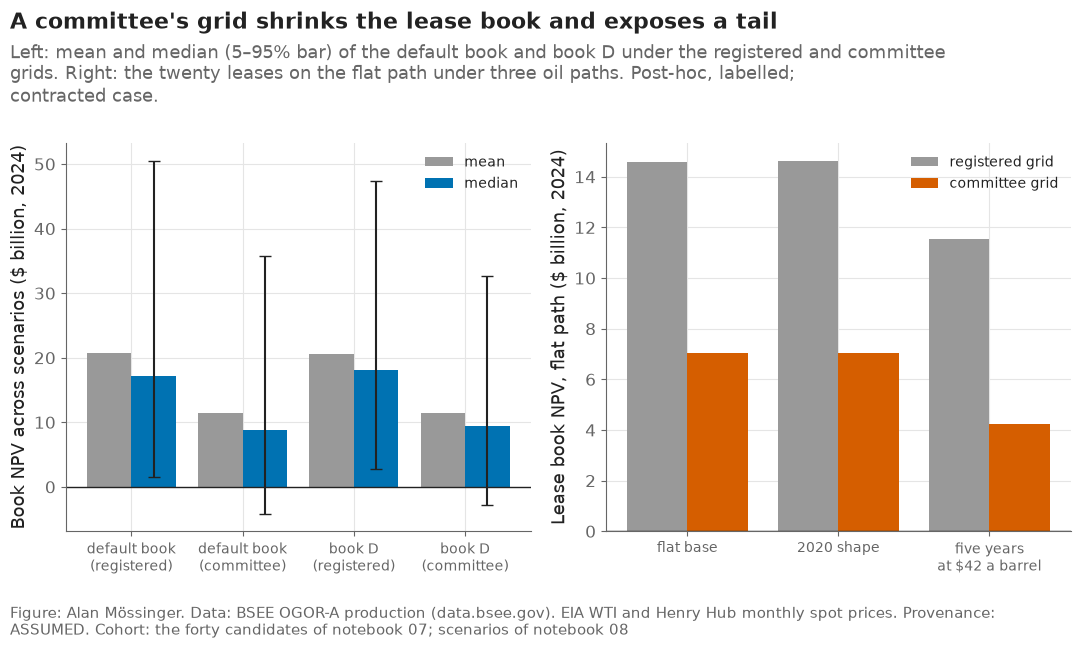

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
labels = ["default book\n(registered)", "default book\n(committee)", "book D\n(registered)", "book D\n(committee)"]
order = [("default book of forty", "registered"), ("default book of forty", "committee"), ("D risk-aware MILP (registered selection)", "registered"), ("D risk-aware MILP (registered selection)", "committee")]
m = medians.set_index(["book", "grid"])
x = np.arange(len(order))
axes[0].bar(x - 0.2, [m.loc[k, "mean"] / 1e9 for k in order], width=0.4, color="#999999", label="mean")
axes[0].bar(x + 0.2, [m.loc[k, "median"] / 1e9 for k in order], width=0.4, color="#0072B2", label="median")
axes[0].errorbar(x + 0.2, [m.loc[k, "median"] / 1e9 for k in order],
                 yerr=[[m.loc[k, "median"] / 1e9 - m.loc[k, "q05"] / 1e9 for k in order], [m.loc[k, "q95"] / 1e9 - m.loc[k, "median"] / 1e9 for k in order]],
                 fmt="none", ecolor=plots.INK, capsize=4, lw=1.5)
axes[0].set_xticks(x, labels, fontsize=10)
axes[0].axhline(0, color=plots.INK, lw=1)
axes[0].set_ylabel("Book NPV across scenarios ($ billion, 2024)")
axes[0].legend(loc="upper right", fontsize=10)
st = oil_stress.loc[["flat 2024 base", "2020 shape from month one", "sustained $42 for five years"]] / 1e9
xs = np.arange(len(st))
axes[1].bar(xs - 0.2, st["registered"], width=0.4, color="#999999", label="registered grid")
axes[1].bar(xs + 0.2, st["committee"], width=0.4, color="#D55E00", label="committee grid")
axes[1].set_xticks(xs, ["flat base", "2020 shape", "five years\nat \$42 a barrel"], fontsize=10)
axes[1].axhline(0, color=plots.INK, lw=1)
axes[1].set_ylabel("Lease book NPV, flat path ($ billion, 2024)")
axes[1].legend(loc="upper right", fontsize=10)
plots.finish(fig, "A committee's grid shrinks the lease book and exposes a tail",
             "Left: mean and median (5–95% bar) of the default book and book D under the registered and committee grids. Right: the twenty leases on the flat path under three oil paths. Post-hoc, labelled; contracted case.",
             "the forty candidates of notebook 07; scenarios of notebook 08", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_EIA_PRICES], provenance="ASSUMED")
plots.save_fig(fig, "F37_committee_grid", "The registered and the committee grid compared: book means and medians, and the lease book under two oil stresses.", NOTEBOOK)
plt.show()


**Reading this.** The left panel separates two corrections the review asked for: the gap between the grey and blue bars is the skew of the scenarios (read the median), and the drop from the registered to the committee pair is the grid. The right panel shows why the registered oil stress looked harmless and what a sustained one does. All of this is post-hoc and labelled ASSUMED; the registered record of part D is unchanged.

## Takeaways

- **Part A** — The portfolio: scorecards, what-ifs, a simulated book, a budget-constrained choice, the backtest, the gates: its *Takeaways — Part A* cell above says what it found and what goes to the report.
- **Part B** — Constraints, levers and region playbooks: its *Takeaways — Part B* cell above says what it found and what goes to the report.
- **Part C** — The milestone-managed book: its *Takeaways — Part C* cell above says what it found and what goes to the report.
- **Part D** — Four ways to spend one budget on the forty candidates, C21–C24 registered first; the frontier, stresses, ablations and the decision ledger.

**What goes to the report.** Report figures drawn here: F14_simulated_book, F15_backtest, F23_portfolio_review, F16_constraint_map, F18_managed_book, F24_book_per_region, F33_four_books. Every number the report cites from this notebook is read from `results/` by `src/report_numbers.py`.